# Hebron: building demolitions and construction from Sentinel-1 (final)

**Research question.** Can Sentinel-1 detect building demolitions and new construction in Hebron, date them, and tell them apart?

**What this version produces.** A *candidate* map: buildings (footprints) where the backscatter changed lastingly, with a date, a score and a type, plus new built-up clusters off existing footprints. Every candidate is meant to be confirmed on dated very-high-resolution imagery before it is reported as a demolition. Published Sentinel-1 damage methods describe their output the same way (a screening tool, not a verified assessment), and section 9 measures how good the screening is.

### What changed from v5, and why

| v5 | v6 | Reason |
|---|---|---|
| GRD search capped at 100 results: the run covered only 2026-05-01 – 2026-10-28 | the whole period, searched in windows that split when they hit the cap, then thinned to 10 dry-season dates per year (two per month, June–October) | the test needs a reference year before every date; every acquisition of every track would be ~1,450 GB |
| VH only | **VV and VH** from the same download; one track by default, more when the volume allows | PWTT tests both polarisations and both pass directions; in a Ukraine study VV carried more destruction information than VH, both together best |
| 30 m cells, step between 3-date means | **10 m pixels**, Lee filter, two-sample t-test per pixel of a reference period against the period after each acquisition date; the new level must hold afterwards. Default series: 10 dry-season dates per year (last season = reference, this season = test, next season = confirmation); with every acquisition: a year of reference against 60 days, 120 days to confirm, season check | PWTT (one-year reference, two-month inference window, t-test per pixel, 10 m); LT-CCD (detection must recur; seasons matched). The thinned default keeps the downloads to about 120 GB for one track |
| fixed thresholds (3 dB, z 3) | threshold from a permutation null of the same statistic | the score is a maximum over ~100 dates and 4–6 track/polarisation pairs: a single-test threshold would flag noise everywhere |
| type from the sign of the VH step | type from **what stood there before**: change on an existing footprint = demolition candidate; change off footprints = construction candidate | backscatter after destruction can rise, fall or stay level (Ukraine study); no study we found validates the sign rule |
| cells, 3-cell blobs | **per-building scores** (mean over the footprint, as PWTT) | a house (100–200 m²) is below the 20 × 22 m resolution of GRDH; scoring the footprint uses every pixel it touches |
| coherence drop as a required layer | coherence as **supporting evidence** where SLC pairs exist | coherence covers only the SLC months; requiring it hid every event outside them |
| hit rate at locality points | **quiet-period false-alarm rate** and **building-level** precision / recall / AUC against your own labels | OCHA coordinates are mostly at locality level; LT-CCD measured false positives over a period without events |

### Sources of the method
* *Open Access Battle Damage Detection via Pixel-Wise T-Test on Sentinel-1 Imagery*, arXiv:2405.06323, 2024 (PWTT: building-level AUC 0.81 Gaza, 0.88 Ukraine; F1 falls with class imbalance; 26 % of footprints smaller than one pixel; false positives cluster next to real damage, median 31 m).
* *An Open-Source Tool for Mapping War Destruction at Scale in Ukraine using Sentinel-1 Time Series*, arXiv:2406.02506, 2024 (VV more informative than VH; backscatter after destruction can increase, decrease or stay stable; buildings ≤ 50 m² excluded; a screening tool).
* *Active InSAR monitoring of building damage in Gaza*, arXiv:2506.14730, 2025 (LT-CCD: matched-season pre-event reference, z < −2, recurrence within a month; FPR 1.2 % measured on a counterfactual period; neighbourhood-scale at 40 m).
* ESA, Sentinel-1 Level-1 GRD: IW GRDH resolution 20 × 22 m, pixel spacing 10 m, ENL 4.4.
* Microsoft Global ML Building Footprints (imagery 2014–2021 for most areas, later updates; Middle East precision 95.7 %, recall 85.4 % in their evaluation).

### What it cannot do (state it with the results)
* **Single small structures** (sheds, tents, walls, water tanks) are far below the resolution; expect them to be missed.
* **Rare events.** Demolitions are a tiny share of Hebron's buildings, so precision, not recall, will be the weak number (PWTT's F1 dropped from 0.76 on balanced samples to 0.64 in Gaza overall).
* **The "existed before" rule** is only as good as the footprints and their date: a building built after the footprint imagery and later demolished is labelled construction; a building demolished before it is invisible. Check the footprint date for Hebron (section 5).
* **Neighbours.** A demolition changes backscatter in neighbouring pixels too, so adjacent buildings can be flagged.

**Sections.** 1 setup · 2 complete GRD search · 3 calibrated σ⁰, VV and VH, all tracks · 4 10 m stacks on disk · 5 settlement mask and footprints · 6 change test and threshold · 7 candidates and type · 8 coherence support (optional, SLC) · 9 validation · 10 export and maps.

## 1. Setup and configuration

In [1]:
import gc
import getpass
import inspect
import json
import os
import warnings
from collections import Counter
from datetime import date, timedelta
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.crs import CRS
from rasterio.transform import from_origin
from rasterio.warp import Resampling, reproject, transform as warp_xy, transform_bounds
from scipy.interpolate import griddata
from scipy.ndimage import binary_dilation, distance_transform_edt, label, map_coordinates
from shapely.geometry import box, shape

from pygeofetch import PyGeoFetch
from pygeofetch.core.orbits import fetch_orbit_file
from pygeofetch.insar import InterferogramGenerator
from pygeofetch.insar.interferogram import InterferogramResult
from pygeofetch.insar.workflow import InSARProject
from pygeofetch.models.download_task import DownloadOptions
from pygeofetch.models.search_query import BoundingBox, SearchQuery
from pygeofetch.sar import GRDExtractor
from pygeofetch.sar.extraction import _verify_product      # the same check extract_sigma0 runs before it deletes anything

import hebron_tools as ht                                   # hebron_tools.py sits next to this notebook

warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")
warnings.filterwarnings("ignore", message="Degrees of freedom")

assert hasattr(GRDExtractor, "extract_sigma0"), "Install the upgraded sar/extraction.py (it adds GRDExtractor.extract_sigma0)."
assert "streaming_cleanup" in inspect.signature(InterferogramGenerator.process_pairs).parameters, \
    "Install the upgraded insar/interferogram.py (it adds process_pairs(streaming_cleanup=...))."
try:
    import pygeofetch.insar.tops  # noqa: F401  (TOPS deramping: without it Sentinel-1 coherence collapses)
except ImportError:
    raise ImportError("This pygeofetch has no insar/tops.py: install the TOPS-fixed version.")

✅ Success: snaphu binary detected at '/usr/local/bin/snaphu'. No manual installation needed.


In [2]:
# ── Run size ────────────────────────────────────────────────────────────────
PILOT = False              # True: a short pipeline check (newest PILOT_N scenes per track); the test needs years, not weeks
PILOT_N = 30
MAX_DOWNLOAD_GB = 200      # refuse to start the GRD downloads above this (raise it consciously: see section 2)
STREAMING_CLEANUP = True   # delete each raw download only after its products are saved AND verified
CHUNK_ROWS = 500           # SLC rows processed at a time (section 8)

# ── Study area and periods ──────────────────────────────────────────────────
BBOX = (35.04, 31.48, 35.18, 31.60)       # Hebron: (min_lon, min_lat, max_lon, max_lat)
AOI_PATH = None                            # optional GeoJSON/GPKG/SHP: its bounds replace BBOX
START, END = "2020-01-01", "2026-10-31"    # GRD series. The first year is reference only: detections start a year after START
GRID_M = 30                                # coherence grid (m), section 8
GRID10_M = 10                              # backscatter grid (m): the GRDH pixel spacing

# ── GRD: tracks, polarisations, search ─────────────────────────────────────
GRD_TRACKS = [("descending", 94)]   # start with one track (v5's, its 2026 VH files are reused); None = every track covering the area
MIN_TRACK_DATES = 5        # with GRD_TRACKS = None: tracks with fewer (thinned) dates are left out
GRD_POLS = ("VV", "VH")
GRD_SEARCH_MAX = 500       # results per search window; a window that hits it is split and searched again
GRD_SEARCH_WINDOW_DAYS = 120
LEGACY_VH_TRACK = ("descending", 94)       # v5 wrote this track's VH files straight into grd/sigma0: reused, not downloaded again

# ── Thinning: how many acquisitions per year are downloaded ─────────────────
SAMPLING = "dry_season"    # "dry_season": DATES_PER_YEAR dates per year, in SEASON_MONTHS, the same months every year; "all": every acquisition
DATES_PER_YEAR = 10       # two per month of SEASON_MONTHS; 5 = one per month (half the download, see section 2)
SEASON_MONTHS = (6, 7, 8, 9, 10)   # Hebron's dry months (rain falls mainly November to April): soil moisture and vegetation change least

# ── Terrain correction of the GRD positions (section 4) ─────────────────────
# Measured with hebron_geolocation_check.ipynb on track D094 (5 dates of 2020, 250,426 open-ground pixels, run of
# 2026-11-16): the GRD sigma0 files are georeferenced on the ellipsoid from 16 control points, so a point appears
# shifted towards the satellite by c + k (h - h_mean). k = 1.64 m/m (theory: cot 31.96 deg = 1.60), c = +440 m at
# 878.2 m (zero shift at about 610 m); correlation with the DEM simulation 0.64 against -0.10 without a shift.
# Another track needs its own measurement (run the check with its TRACK_KEY). None = no correction (tests only).
TERRAIN_CORRECTION = {"D094": {"k_m_per_m": 1.64, "c_m": 440.0, "h_mean_m": 878.2,
                               "to_sat_en": (0.9826, -0.1858), "incidence_deg": 31.96}}
PER_DATE_OFFSET = True     # measure what is left of the shift on every date (against the DEM simulation) and remove it too
MAX_RESIDUAL_M = 60        # a date whose remaining shift is larger is left out of the stack and listed (only without COREGISTER)
# ── Co-registration: every date lined up with one reference image (section 4) ──
# hebron_geolocation_check.ipynb (section 6B, 17 Nov 2026) found the D094 products from 2022 on placed differently from
# 2020-2021: about 65 m further west and stretched about 34 m east-west across the area. One shift per date cannot remove
# a stretch; lining every date up with a reference image (shift + linear stretch, from tile matching) does: the false
# alarms dated 2022 fell from 275 to 88 of 3,000 buildings. It replaces PER_DATE_OFFSET.
COREGISTER = True
COREG_REF_DATES = 5        # the first VV dates of a track, averaged (terrain-corrected) into its reference image
COREG_TILE_PX, COREG_MAX_SHIFT_PX = 128, 12   # tiles of 1.28 km; offsets searched up to 120 m
MIN_COREG_TILES, MAX_COREG_SCATTER_M = 8, 15  # a date with fewer matching tiles, or tiles scattering more around the fit, is left out
# ── Neighbourhood level (section 4) ──
# The first full v7 run (17 Nov 2026) gave 6,905 demolition candidates, 46 % of them dated on the first image of a dry
# season, and no match with OCHA's records. Brightness differences shared by a whole neighbourhood from one year to the
# next (moisture, vegetation, processing) are not removed by the whole-image median and look like change. With
# LOCAL_NORM_M, every pixel on every date is taken relative to the median of its surroundings (about LOCAL_NORM_M x
# LOCAL_NORM_M metres) on that date: a shared shift cancels, one building's change stays. None = off (as before).
LOCAL_NORM_M = 400
# ── The building test (section 7) ──
# "step" (default): each building's pixels averaged per date, and a lasting step tested at every season start: all
# seasons before against all seasons after, with the uncertainty including the area's typical season-to-season wobble
# of a building (section 7c measured it: twice what independent dates give), and the threshold from shuffling whole
# seasons. On the 4,000 sampled buildings (7d) it cut false alarms from 14.9 % to 2.9 % and still found 81 % of 4 dB
# and 98 % of 6 dB steps; 43 of the 57 remaining "false alarms" got brighter (building activity is the likely cause).
# "pixels": the earlier test (pixels tested one year before against 150 days after, footprint mean of the scores).
BUILDING_TEST = "step"
STEP_SEASON_STARTS_ONLY = True
DEMOLITION_DIRECTION = "darker"   # "darker": demolition candidates are buildings that got darker (the corner
                                  # reflection of walls lost); brighter steps are listed separately as "brightening".
                                  # "any": both directions are demolition candidates (rubble can be brighter).
DEM_PATH_TC = None         # DEM for the correction; None = the COP30 DEM in DATA/dem (the one the check used)

# ── Change test (section 6) ────────────────────────────────────────────────
LEE_WINDOW = 5             # Lee speckle filter window (pixels) before the test; 0 = off. ENL 4.4 (ESA, IW GRDH)
if SAMPLING == "dry_season":    # one season per year: last season is the reference, this season the test, next season the confirmation
    TEST = ht.TestParams(ref_days=365, post_days=150, confirm_days=365, min_ref=4, min_post=2, min_confirm=2, season_check=False)
else:                           # every acquisition: PWTT-like windows (a year of reference, two months of test)
    TEST = ht.TestParams(ref_days=365, post_days=60, confirm_days=120, min_ref=15, min_post=3, min_confirm=3, season_check=True)
T_THRESHOLD = None         # None = from the permutation null (NULL_QUANTILE); or a fixed |t|
NULL_QUANTILE = 0.999      # pixel threshold (maps, construction clusters): share of null pixel scores below it
N_NULL = 20_000            # pixels sampled for the pixel null
T_THRESHOLD_BUILDING = None   # None = from the building null (NULL_QUANTILE_BUILDING); or a fixed mean |t|
NULL_QUANTILE_BUILDING = 0.995   # building threshold: share of null building scores below it (0.995 = 5 per 1,000 unchanged buildings)
N_NULL_BUILDINGS = 4000    # footprints sampled for the building null
BLOCK_ROWS = 32            # rows of the 10 m grid tested at a time (memory: ~BLOCK_ROWS x width x dates x 30 bytes)
DATE_TOL_DAYS = 150 if SAMPLING == "dry_season" else 60   # results of different tracks/polarisations agree when this close

# ── Buildings and type (sections 5 and 7) ──────────────────────────────────
FOOTPRINTS_PATH = None     # your footprint file (any vector format); None = Microsoft Global ML Building Footprints, downloaded once
MS_LINKS_URLS = ["https://minedbuildings.z5.web.core.windows.net/global-buildings/dataset-links.csv",
                 "https://bfppub.blob.core.windows.net/%24web/2026-08-13/dataset-links.csv"]
MIN_FOOTPRINT_M2 = 50      # smaller footprints dropped (under half a 10 m pixel; as in the Ukraine study)
MIN_CONFIRMED_FRAC = 0.5   # share of a building's changed pixels whose new level held (persistence)
CON_MIN_AREA_M2 = 400      # construction clusters off footprints: at least 4 pixels of 10 m
CONSTRUCTION_ZONE_M = 300  # construction searched within this distance of existing footprints (and the settlement mask)
SPILLOVER_M = 30           # a construction cluster this close to a demolition candidate of the same date is the same event
WSF_PATH = DW_PATH = None  # optional settlement masks (WSF value > 0, Dynamic World class 6)

# ── Coherence support (section 8, optional) ────────────────────────────────
RUN_COHERENCE = True
SLC_START, SLC_END = "2026-06-01", "2026-10-31"
MAX_SLC, SLC_DATES = 16, None
TRACK = LEGACY_VH_TRACK    # SLC track (the coherence chain of v5)
COH_DROP, COH_STABLE, TOL_DAYS = 0.30, 0.40, 24

# ── Validation (section 9) ─────────────────────────────────────────────────
QUIET_PERIOD = None        # ("YYYY-MM-DD", "YYYY-MM-DD"): a period with NO known demolitions in QUIET_AREA_PATH (or the whole AOI)
QUIET_AREA_PATH = None
BUILDING_REF_PATH = None   # your building-level labels: points or polygons, column "class" (demolition / construction / none), optional "date"
LABEL_AREA_PATH = None     # polygons where EVERY change was mapped (needed for precision); None = recall and AUC only
REF_MATCH_M = 20           # a candidate matches a label within this distance
OCHA_PATH = PEACENOW_PATH = ARIJ_PATH = None    # locality-level references (section 9c)
REF_RADIUS_M = 150
# ── OCHA demolition records, place and time (section 9d) ──
# OCHA's records (date, community, structures), e.g. demo-repository.xlsx from the Dryad dataset "Occupation, violence,
# and displacement in the West Bank" (OCHA data to 30 June 2024). More files with the same columns can be added.
OCHA_FILES = None          # None = DATA/references/demo-repository.xlsx; or a list of files
OCHA_GOVERNORATE, OCHA_START = "Hebron", "2020-01-01"
OCHA_RADIUS_M = 1000       # candidates within this distance of a community's point count for it
OCHA_DATE_TOL_DAYS = 15    # a candidate's date may differ this much from the first acquisition after the OCHA date
OCHA_N_DRAWS = 2000        # random-date repetitions for the chance level
OCHA_SKIP = ["Hebron", "Massafer Yatta", "Masafer Bani Na'im"]   # names that cover a whole city or region: not placed
OCHA_MANUAL_COORDS = {}    # community name -> (lon, lat), from Google Earth, to correct or add a location
SEED = 0

if PILOT:
    print(f"PILOT: newest {PILOT_N} GRD scenes per track. With fewer than about a year and a half of dates the test "
          "has no reference year: use it to check the chain only.")

In [3]:
DATA = Path("/run/media/samuel-appiah-kubi/New Volume/hebronv5")
RAW_GRD, SIGMA0_DIR, DEM_DIR, IFG_DIR, RESULTS = (DATA / s for s in ("grd/raw", "grd/sigma0", "dem", "ifg", "results"))
STACK_DIR, CHANGE_DIR, FOOT_DIR = DATA / "grd/stacks10", RESULTS / "change", DATA / "footprints"
for p in (RAW_GRD, SIGMA0_DIR, DEM_DIR, IFG_DIR, RESULTS, DATA / "slc", STACK_DIR, CHANGE_DIR, FOOT_DIR):
    p.mkdir(parents=True, exist_ok=True)
if AOI_PATH:
    BBOX = tuple(float(v) for v in gpd.read_file(AOI_PATH).to_crs(4326).total_bounds)
aoi, aoi_poly = BoundingBox.from_string(",".join(map(str, BBOX))), box(*BBOX)

# Two grids in UTM 36N (Hebron lies at 35.1 deg E): 10 m for backscatter, 30 m for coherence.
GRID_CRS = CRS.from_epsg(32636)
left, bottom, right, top = transform_bounds("EPSG:4326", GRID_CRS, *BBOX)
W, H = int((right - left) // GRID_M), int((top - bottom) // GRID_M)
GRID_T = from_origin(left, top, GRID_M, GRID_M)
EXTENT = (left, left + W * GRID_M, top - H * GRID_M, top)
W10, H10 = int((right - left) // GRID10_M), int((top - bottom) // GRID10_M)
GRID10_T = from_origin(left, top, GRID10_M, GRID10_M)
EXTENT10 = (left, left + W10 * GRID10_M, top - H10 * GRID10_M, top)
INVENTORY = RESULTS / "grd_inventory.json"      # dates per track (section 2), so later sections work in a fresh kernel
print(f"backscatter grid {H10} x {W10} at {GRID10_M} m; coherence grid {H} x {W} at {GRID_M} m")

backscatter grid 1356 x 1354 at 10 m; coherence grid 452 x 451 at 30 m


In [4]:
client = PyGeoFetch()
# client.add_credentials("copernicus", username=os.environ.get("CDSE_USER") or input("Copernicus e-mail: "),
#                        password=os.environ.get("CDSE_PASS") or getpass.getpass("Copernicus password: "))
# client.add_credentials("opentopography", api_key=os.environ.get("OPENTOPO_KEY") or getpass.getpass("OpenTopography API key: "))

14:44:54 INFO [      engine] PyGeoFetch ready


In [5]:
def name_of(item):
    return item.properties.get("name") or item.id

def track_of(item):
    return (str(item.pass_direction).lower(), int(item.relative_orbit))

def track_key(track):
    """('descending', 94) -> 'D094' (used in folder and layer names)."""
    return f"{track[0][0].upper()}{int(track[1]):03d}"

def covers_aoi(item):
    return item.geometry is None or shape(item.geometry).buffer(0).contains(aoi_poly)

def one_per_date(items, track, only=None):
    """One scene per acquisition date on `track`, oldest first (only = optional list of dates)."""
    out = {}
    for item in sorted(items, key=lambda i: i.datetime):
        if track_of(item) == tuple(track) and (not only or str(item.datetime)[:10] in only):
            out.setdefault(str(item.datetime)[:10], item)
    return list(out.values())

def newest_or_first(items, n):
    """Pilot: the newest n scenes; full run: the first n. None = all."""
    return items if not n else (items[-n:] if PILOT else items[:n])

def size_gb(items):
    return sum((i.assets["download"].size_bytes or 0) for i in items if "download" in i.assets) / 1e9


GRD_KW = dict(lut="sigmaNought", remove_noise=True, out_db=False, aoi_bbox=BBOX)
_NAME_KW = {k: GRD_KW[k] for k in ("lut", "out_db", "aoi_bbox")}
EXTRACTOR = {pol: GRDExtractor(pol) for pol in GRD_POLS}


def sigma0_dir(track, pol):
    if tuple(track) == tuple(LEGACY_VH_TRACK) and pol == "VH":
        return SIGMA0_DIR                                       # v5 layout, reused
    d = SIGMA0_DIR / track_key(track) / pol.lower()
    d.mkdir(parents=True, exist_ok=True)
    return d


def sigma0_path(track, pol, day):
    return sigma0_dir(track, pol) / EXTRACTOR[pol].sigma0_filename(day, **_NAME_KW)

## 2. Complete GRD search, then a thinned series

v5 asked for at most 100 results and got the 100 newest products, so its series started on 2026-05-01. Here the period is searched in windows of `GRD_SEARCH_WINDOW_DAYS`; a window that returns `GRD_SEARCH_MAX` results may be truncated and is split in two and searched again (`ht.search_all`).

**Thinning (`SAMPLING = "dry_season"`).** Every acquisition of every track from 2020 would be about 1,450 GB of downloads. Instead, `DATES_PER_YEAR` dates per year are kept in `SEASON_MONTHS` (10: two per month, near the 8th and the 23rd; 5: one per month, nearest the 15th; dates already processed win), on the tracks in `GRD_TRACKS`. For one track from 2020, 10 per year is about 70 scenes (~120 GB), 5 per year about 35 (~60 GB). Taking the same dry months every year means each year is compared with the same season a year earlier, so moisture and vegetation differ as little as possible between the two. The table shows both volumes per track.

**What thinning costs**, stated with the results:
* **Dating** is to the season: a change is placed between the last acquisition that does not show it and the first that does, which can be up to about eight months apart (October to June).
* **Statistics**: about 10 reference and up to 10 test dates per pixel instead of ~30 and ~5 (PWTT). The threshold comes from the permutation null of the same thinned series, and sections 9a–9b measure the result.
* **On a synthetic town** (1 track, 1,120 buildings, 10 demolitions, 4 construction sites; `test_v6.py`): every acquisition found 10/10 demolitions dated within 5 days (median); 10 dry-season dates per year found 10/10, dated within 49 days; 5 per year found only 5/10, dated within 112 days. Precision was 0.42–0.50 in all three (about 5 false candidates per 1,000 buildings at the default building threshold). That is why the default is 10, not 5. These are synthetic numbers; only section 9 measures Hebron.
* **One track** sees the town from one side only; buildings in radar shadow or layover from that side are not tested. Add a second track (an ascending one) when the volume allows: PWTT combines both pass directions.

Downloads are streamed: one raw scene (~1.7 GB) is on disk at a time; what stays is ~20 MB per date (VV + VH, cropped).

In [6]:
query = SearchQuery(bbox=aoi, start_date=START, end_date=END, product_type="GRD", polarisation="VH", max_results=GRD_SEARCH_MAX)
found = ht.search_all(client, query, ["copernicus"], START, END, window_days=GRD_SEARCH_WINDOW_DAYS)
grd = [i for i in found if "_GRD" in name_of(i) and "COG" not in name_of(i) and covers_aoi(i)]
assert grd, "No Sentinel-1 GRD scene covers the AOI in this period."

def thinned(items, track):
    """The dates kept for the test: all, or DATES_PER_YEAR per year in SEASON_MONTHS (dates already processed win)."""
    if SAMPLING != "dry_season":
        return items
    dates = [str(i.datetime)[:10] for i in items]
    done = {d for d in dates if any(sigma0_path(track, pol, d).exists() for pol in GRD_POLS)}
    keep = set(ht.select_seasonal_dates(dates, SEASON_MONTHS, DATES_PER_YEAR, prefer=done))
    return [i for i in items if str(i.datetime)[:10] in keep]


rows = []
for tr, n in Counter(track_of(i) for i in grd).most_common():
    its = one_per_date(grd, tr)
    th = thinned(its, tr)
    rows.append({"track": tr, "key": track_key(tr), "dates": len(its), "first": str(its[0].datetime)[:10],
                 "last": str(its[-1].datetime)[:10], "satellites": dict(Counter(name_of(i)[:3] for i in its)),
                 "GB, every date": round(size_gb(its), 1), "dates kept": len(th), "GB, dates kept": round(size_gb(th), 1)})
track_table = pd.DataFrame(rows).set_index("key")
display(track_table)

tracks = [tuple(t) for t in GRD_TRACKS] if GRD_TRACKS else [r["track"] for r in rows if r["dates kept"] >= MIN_TRACK_DATES]
grd_items = {track_key(t): newest_or_first(thinned(one_per_date(grd, t), t), PILOT_N if PILOT else None) for t in tracks}
inventory = {track_key(t): {"track": list(t), "dates": [str(i.datetime)[:10] for i in grd_items[track_key(t)]]} for t in tracks}
INVENTORY.write_text(json.dumps(inventory, indent=1))
todo_items = [i for k, v in grd_items.items() for i in v
              if not all(sigma0_path(tuple(inventory[k]["track"]), pol, str(i.datetime)[:10]).exists() for pol in GRD_POLS)]
total = size_gb(todo_items)
print(f"tracks kept: {[track_key(t) for t in tracks]}; {sum(len(v) for v in grd_items.values())} dates, of which "
      f"{len(todo_items)} still to download: about {total:.0f} GB, one scene at a time (~{total * 1e3 / 3 / 3600:.0f} h at 3 MB/s). "
      f"Disk: ~1.7 GB at a time for the raw scene, then ~20 MB per date")
assert total <= MAX_DOWNLOAD_GB or PILOT, (f"{total:.0f} GB > MAX_DOWNLOAD_GB = {MAX_DOWNLOAD_GB}: raise it, or set GRD_TRACKS "
                                           "to fewer tracks, or START later")

┌ SEARCH PARAMETERS ───────────────────────────────────────────────────────┐
│ Providers  : copernicus                                                  │
│ BBox       : [35.040, 31.480, 35.180, 31.600]                            │
│ Date range : 2020-01-01  →  2020-04-29                                   │
│ Cloud max  : 100%                                                        │
│ Product    : GRD                                                         │
└──────────────────────────────────────────────────────────────────────────┘
14:44:55 INFO [  copernicus] Authenticated with Copernicus Data Space as 'appiahkubis14@gmail.com'


/home/samuel-appiah-kubi/Desktop/main/PLUS/GeoHumanitarian Action/Research/venv/lib/python3.14/site-packages/pydantic/main.py:520: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `date` - serialized value may not be as expected [field_name='start_date', input_value='2020-01-01', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `datetime` - serialized value may not be as expected [field_name='start_date', input_value='2020-01-01', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `date` - serialized value may not be as expected [field_name='end_date', input_value='2020-04-29', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `datetime` - serialized value may not be as expected [field_name='end_date', input_value='2020-04-29', input_type=str])
  return self.__pydantic_serializer__.to_python(


  ✓  copernicus                      79 scenes   4.9s
┌────────────────────────────────────────────┬────────────┬────────────────┬────────┬─────────┬──────────────┬─────────────┬───────┬───────┬──────────────────────┐
│                  SCENE ID                  │    DATE    │   SATELLITE    │ CLOUD  │ PRODUCT │ POLARISATION │    PASS     │ ORBIT │ SCORE │       PROVIDER       │
├────────────────────────────────────────────┼────────────┼────────────────┼────────┼─────────┼──────────────┼─────────────┼───────┼───────┼──────────────────────┤
│ d6701cde-7d06-5336-9c89-2f43de2b06b2       │ 2020-04-26 │ SENTINEL-1A    │ —      │ IW_GRD… │ VV&VH        │ descending  │ 21    │ 0.50  │ copernicus           │
│ 0b31abe7-ea41-5f82-9de8-3ff7c1db4ba6       │ 2020-04-25 │ SENTINEL-1B    │ —      │ IW_GRD… │ VV&VH        │ descending  │ 94    │ 0.50  │ copernicus           │
│ 6f737ff3-a4a3-5e7c-bc93-630f25ffdf9f       │ 2020-04-25 │ SENTINEL-1B    │ —      │ IW_GRD… │ VV&VH        │ descending  │ 9

/home/samuel-appiah-kubi/Desktop/main/PLUS/GeoHumanitarian Action/Research/venv/lib/python3.14/site-packages/pydantic/main.py:520: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `date` - serialized value may not be as expected [field_name='start_date', input_value='2020-04-30', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `datetime` - serialized value may not be as expected [field_name='start_date', input_value='2020-04-30', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `date` - serialized value may not be as expected [field_name='end_date', input_value='2020-08-27', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `datetime` - serialized value may not be as expected [field_name='end_date', input_value='2020-08-27', input_type=str])
  return self.__pydantic_serializer__.to_python(


  ✓  copernicus                      73 scenes   3.4s
┌────────────────────────────────────────────┬────────────┬────────────────┬────────┬─────────┬──────────────┬─────────────┬───────┬───────┬──────────────────────┐
│                  SCENE ID                  │    DATE    │   SATELLITE    │ CLOUD  │ PRODUCT │ POLARISATION │    PASS     │ ORBIT │ SCORE │       PROVIDER       │
├────────────────────────────────────────────┼────────────┼────────────────┼────────┼─────────┼──────────────┼─────────────┼───────┼───────┼──────────────────────┤
│ cd1d6f12-e543-5e3c-b438-20c6070a7905       │ 2020-08-24 │ SENTINEL-1A    │ —      │ IW_GRD… │ VV&VH        │ descending  │ 21    │ 0.50  │ copernicus           │
│ 1a24838f-4222-5b09-b469-1d7dd23fa17f       │ 2020-08-23 │ SENTINEL-1B    │ —      │ IW_GRD… │ VV&VH        │ descending  │ 94    │ 0.50  │ copernicus           │
│ a13bc86a-3b17-58b1-8668-e99ac42e109e       │ 2020-08-23 │ SENTINEL-1B    │ —      │ IW_GRD… │ VV&VH        │ descending  │ 9

/home/samuel-appiah-kubi/Desktop/main/PLUS/GeoHumanitarian Action/Research/venv/lib/python3.14/site-packages/pydantic/main.py:520: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `date` - serialized value may not be as expected [field_name='start_date', input_value='2020-08-28', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `datetime` - serialized value may not be as expected [field_name='start_date', input_value='2020-08-28', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `date` - serialized value may not be as expected [field_name='end_date', input_value='2020-12-25', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `datetime` - serialized value may not be as expected [field_name='end_date', input_value='2020-12-25', input_type=str])
  return self.__pydantic_serializer__.to_python(


... (35 outputs left out)

/home/samuel-appiah-kubi/Desktop/main/PLUS/GeoHumanitarian Action/Research/venv/lib/python3.14/site-packages/pydantic/main.py:520: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `date` - serialized value may not be as expected [field_name='start_date', input_value='2026-07-28', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `datetime` - serialized value may not be as expected [field_name='start_date', input_value='2026-07-28', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `date` - serialized value may not be as expected [field_name='end_date', input_value='2026-10-31', input_type=str])
  PydanticSerializationUnexpectedValue(Expected `datetime` - serialized value may not be as expected [field_name='end_date', input_value='2026-10-31', input_type=str])
  return self.__pydantic_serializer__.to_python(


  ✓  copernicus                      47 scenes   1.7s
┌────────────────────────────────────────────┬────────────┬────────────────┬────────┬─────────┬──────────────┬─────────────┬───────┬───────┬──────────────────────┐
│                  SCENE ID                  │    DATE    │   SATELLITE    │ CLOUD  │ PRODUCT │ POLARISATION │    PASS     │ ORBIT │ SCORE │       PROVIDER       │
├────────────────────────────────────────────┼────────────┼────────────────┼────────┼─────────┼──────────────┼─────────────┼───────┼───────┼──────────────────────┤
│ e6480f89-ccbc-4abe-9a76-7e8b6c582bc8       │ 2026-10-29 │ SENTINEL-1C    │ —      │ IW_GRD… │ VV&VH        │ descending  │ 21    │ 0.78  │ copernicus           │
│ 7836f8bc-efb8-4c0c-bda9-d4bd08aa9c04       │ 2026-10-28 │ SENTINEL-1D    │ —      │ IW_GRD… │ VV&VH        │ descending  │ 94    │ 0.78  │ copernicus           │
│ f3a1bbbd-3f17-4595-add3-eb6e566cd51e       │ 2026-10-23 │ SENTINEL-1D    │ —      │ IW_GRD… │ VV&VH        │ descending  │ 2

,track,dates,first,last,satellites,"GB, every date",dates kept,"GB, dates kept"
key,,,,,,,,
A087,"(ascending, 87)",316,2020-01-01,2026-10-21,"{'S1A': 196, 'S1B': 59, 'S1C': 45, 'S1D': 16}",551.3,70,122.2
D094,"(descending, 94)",260,2020-01-02,2026-10-28,"{'S1A': 195, 'S1B': 1, 'S1C': 47, 'S1D': 17}",455.4,70,122.2
D021,"(descending, 21)",253,2020-01-09,2026-10-29,"{'S1A': 191, 'S1B': 1, 'S1C': 45, 'S1D': 16}",441.7,69,120.5


tracks kept: ['D094']; 70 dates, of which 0 still to download: about 0 GB, one scene at a time (~0 h at 3 MB/s). Disk: ~1.7 GB at a time for the raw scene, then ~20 MB per date


## 3. Calibrated σ⁰, VV and VH, one scene at a time

As in v5: σ⁰ = (DN² − N) / A² with the calibration table A and the thermal noise N removed (`extract_sigma0(lut="sigmaNought", remove_noise=True)`), linear power, cropped to the area, saved as a Cloud-Optimized GeoTIFF and verified. **New:** both polarisations are taken from the same download (dual-polarisation SDV products), and each track and polarisation has its own folder (`grd/sigma0/<track>/<pol>`), so files of different tracks on the same day cannot collide. Only the last polarisation of a scene runs with `streaming_cleanup`, so the raw file is deleted after both are verified. v5's VH files of track D094 (in `grd/sigma0`) are reused.

In [7]:
def process_grd_scene(item, track):
    """Download one GRD scene once, calibrate every polarisation still missing, verify, then delete the raw file
    (STREAMING_CLEANUP, on the last polarisation only). Returns {pol: COG path} for the polarisations that exist."""
    day = str(item.datetime)[:10]
    have, todo = {}, []
    for pol in GRD_POLS:
        p = sigma0_path(track, pol, day)
        if p.exists() and _verify_product(p, require_crs=False)[0]:
            have[pol] = p
        else:
            todo.append(pol)
    if not todo:
        return have                                               # resume: nothing is downloaded again
    try:
        result = client.download([item], destination=RAW_GRD, options=DownloadOptions(parallel=1, resume=True))[0]
        if not result.success or result.output_path is None or not Path(result.output_path).exists():
            print(day, "DOWNLOAD FAILED:", result.error_type, result.error)
            return have
        for k, pol in enumerate(todo):
            last = k == len(todo) - 1
            cog = EXTRACTOR[pol].extract_sigma0(result, sigma0_dir(track, pol), label=day,
                                               streaming_cleanup=STREAMING_CLEANUP and last, **GRD_KW)
            if cog is None:
                print(day, pol, "CALIBRATION FAILED: see the log above; the raw file was kept")
            else:
                have[pol] = Path(cog)
    except Exception as exc:                                       # one bad scene must not stop a 6-year series
        print(day, f"FAILED: {type(exc).__name__}: {exc}")
    finally:
        gc.collect()
    return have


for key, items in grd_items.items():
    track = tuple(inventory[key]["track"])
    done = Counter()
    for n, item in enumerate(items, 1):
        got = process_grd_scene(item, track)
        done.update(got.keys())                                  # count the polarisations saved for this date
        if n % 10 == 0 or n == len(items):
            print(f"{key}: {n}/{len(items)} scenes; {dict(done)}; raw files left: {len(list(RAW_GRD.glob('*.zip')))}")

D094: 10/70 scenes; {'VV': 10, 'VH': 10}; raw files left: 0
D094: 20/70 scenes; {'VV': 20, 'VH': 20}; raw files left: 0
D094: 30/70 scenes; {'VV': 30, 'VH': 30}; raw files left: 0
D094: 40/70 scenes; {'VV': 40, 'VH': 40}; raw files left: 0
D094: 50/70 scenes; {'VV': 50, 'VH': 50}; raw files left: 0
D094: 60/70 scenes; {'VV': 60, 'VH': 60}; raw files left: 0
D094: 70/70 scenes; {'VV': 70, 'VH': 70}; raw files left: 0


## 4. 10 m stacks on disk, terrain-corrected

**Why a correction.** The σ⁰ files are placed on the map from 16 ground control points on the ellipsoid. Radar measures distance, so a point on high ground appears shifted towards the satellite. `hebron_geolocation_check.ipynb` measured it for track D094: **shift = c + k · (h − h_mean)** towards the satellite, k = 1.64 m per metre of height (theory: cot 32° = 1.60), +440 m at the mean height of 878 m, so from about −130 m in the lowest valleys to about +670 m on the highest ridges. Uncorrected, a change would be given to a building hundreds of metres away.

**What this section does.** Every 10 m cell at its true position p (height h(p) from the DEM) takes the σ⁰ value the file shows at p + shift(h(p)) towards the satellite (bilinear on linear power). With `PER_DATE_OFFSET`, each date's remaining shift is then measured against the DEM-simulated brightness (open ground, ±120 m, 5 m steps) and removed as well: the control points differ a little from scene to scene. Dates whose remaining shift exceeds `MAX_RESIDUAL_M` are left out and listed. Then, as before: Lee filter (`LEE_WINDOW`), dB, the date's median over the area removed (rain and soil moisture shift the whole scene; a building change is local).

**What it cannot fix.** Slopes facing the satellite (east-facing here) are compressed in the radar image: several ground cells share one radar pixel, so after correction they carry the same, smeared value. Their change scores are less sharp; no position error remains.

**Co-registration (`COREGISTER = True`, replaces `PER_DATE_OFFSET`).** The geolocation check found that the D094 products from 2022 on are placed differently from 2020–2021: about 65 m further west, and stretched about 34 m east–west across the area. A stretch cannot be removed by one shift per date, and a building then partly shows its neighbour, which the test reads as a change: before co-registration, the false alarms dated 2022 were three times those of other years. So every date is lined up with one **reference image** per track, the average of the track's first `COREG_REF_DATES` VV dates (terrain-corrected, and moved by their own left-over shift against the DEM).
1. The area is cut into tiles of `COREG_TILE_PX` pixels.
2. In each tile, the offset that best matches the date to the reference is found from the image patterns (buildings, roads, slopes), to a fraction of a pixel.
3. A plane is fitted through the tile offsets: a shift plus a linear stretch.
4. The file is read once more at the lined-up positions.

VH uses the offsets measured on VV of the same date (same product, same geometry). A date with fewer than `MIN_COREG_TILES` matching tiles, or tiles scattering more than `MAX_COREG_SCATTER_M` around the plane, is left out and listed (a broken or very different image).

Stacks are kept on disk per track and polarisation (`grd/stacks10/<track>_<pol>_tc_cr/`, memory-mapped); stacks made without co-registration (`_tc`) or without the terrain correction are not used, so turning it on rebuilds the stacks once. Missing dates stay empty; re-running fills only what is new. The offsets of every date are written to `results/terrain_offsets.json`.

In [8]:
inventory = json.loads(INVENTORY.read_text())
COMBOS = [(key, pol) for key in inventory for pol in GRD_POLS]
STACK_TAG = ("_tc" if TERRAIN_CORRECTION else "") + ("_cr" if COREGISTER else "")
combo_name = lambda key, pol: f"{key}_{pol}{STACK_TAG}"
TC = {}
OPEN10 = None
if TERRAIN_CORRECTION:
    missing = [k for k in inventory if k not in TERRAIN_CORRECTION]
    assert not missing, (f"no terrain correction measured for {missing}: run hebron_geolocation_check.ipynb with that "
                         "TRACK_KEY and add its numbers to TERRAIN_CORRECTION (or drop the track from GRD_TRACKS)")
    if DEM_PATH_TC is not None:
        dem_tc = Path(DEM_PATH_TC)
    elif (RESULTS / "dem_path.txt").exists() and Path((RESULTS / "dem_path.txt").read_text().strip()).exists():
        dem_tc = Path((RESULTS / "dem_path.txt").read_text().strip())
    else:
        found = sorted(DEM_DIR.rglob("*COP30*.tif")) or sorted(DEM_DIR.rglob("*.tif"))
        assert found, f"no DEM in {DEM_DIR}: set DEM_PATH_TC (the Copernicus 30 m DEM the geolocation check used)"
        dem_tc = found[-1]
    H10_DEM = ht.height_on_grid(dem_tc, GRID10_T, (H10, W10), GRID_CRS)
    fp_file = FOOT_DIR / "ms_buildings.gpkg"
    if FOOTPRINTS_PATH is not None or fp_file.exists():      # open ground for the offset check: few buildings
        fpg = gpd.read_file(FOOTPRINTS_PATH or fp_file)
        fpg = (fpg.set_crs(4326) if fpg.crs is None else fpg).to_crs(GRID_CRS)
        from rasterio.features import rasterize as _rz
        OPEN10 = _rz(((g, 1) for g in fpg.geometry), out_shape=(H10, W10), transform=GRID10_T, fill=0, dtype="uint8",
                     all_touched=True) == 0
        from scipy.ndimage import binary_erosion
        OPEN10 = binary_erosion(OPEN10, np.ones((5, 5), bool))
    else:
        OPEN10 = np.ones((H10, W10), bool)
    for key, tc in TERRAIN_CORRECTION.items():
        if key not in inventory:
            continue
        shift = ht.terrain_shift_m(H10_DEM, tc["k_m_per_m"], tc["c_m"], tc["h_mean_m"])
        TC[key] = {**tc, "shift": shift, "se": shift * tc["to_sat_en"][0], "sn": shift * tc["to_sat_en"][1],
                   "sim": ht.simulated_brightness(H10_DEM, GRID10_M, tc["to_sat_en"], tc["incidence_deg"])}
        print(f"{key}: shift towards the satellite {np.percentile(shift, 1):+.0f} .. {np.percentile(shift, 99):+.0f} m "
              f"(DEM {dem_tc.name}, {H10_DEM.min():.0f}-{H10_DEM.max():.0f} m); open ground for the offset check {OPEN10.mean():.0%}")
OFFSETS_FILE = RESULTS / "terrain_offsets.json"
OFFSETS = json.loads(OFFSETS_FILE.read_text()) if OFFSETS_FILE.exists() else {}
RR10, CC10 = np.mgrid[0:H10, 0:W10].astype(float)


def finish(power):
    # linear power on the 10 m grid -> Lee filter, dB, scene median removed
    power = np.where(power > 0, power, np.nan)                     # after noise subtraction a pixel can be <= 0
    power = ht.lee_filter(power, LEE_WINDOW) if LEE_WINDOW else power
    with np.errstate(invalid="ignore", divide="ignore"):
        db = 10 * np.log10(power)
    return (db - np.nanmedian(db)).astype("float32")


def to_db(power):
    with np.errstate(invalid="ignore", divide="ignore"):
        return 10 * np.log10(np.where(power > 0, power, np.nan))


def sample_power(path, key, de=0.0, dn=0.0):
    # the file's linear power at every 10 m cell's true position + the terrain shift + (de east, dn north) metres
    se, sn = (TC[key]["se"], TC[key]["sn"]) if key in TC else (0.0, 0.0)
    return ht.sample_geotiff(path, *ht.offset_lonlat(GRID10_T, (H10, W10), GRID_CRS, se + de, sn + dn))


def own_residual(power, key):
    # left-over shift (m, towards the satellite) of a terrain-corrected image against the DEM simulation
    if key not in TC:
        return 0.0, float("nan")
    db = to_db(power)
    return ht.residual_offset_m(db, TC[key]["sim"], OPEN10 & np.isfinite(db), GRID10_M, TC[key]["to_sat_en"])


# the reference image of every track: its first COREG_REF_DATES VV dates, terrain-corrected and moved by their own
# left-over shift, averaged; made once and kept, so every later date is lined up with the same image
REFERENCE, COREG = {}, {}
if COREGISTER:
    for key in inventory:
        track = tuple(inventory[key]["track"])
        ref_file = STACK_DIR / f"{key}_reference{STACK_TAG}.npy"
        if ref_file.exists():
            REFERENCE[key] = np.load(ref_file)
        else:
            days = [d for d in inventory[key]["dates"] if sigma0_path(track, "VV", d).exists()][:COREG_REF_DATES]
            assert len(days) >= 2, f"{key}: fewer than 2 VV dates on disk, no reference image yet"
            acc = []
            for d in days:
                pth = sigma0_path(track, "VV", d)
                r0, _ = own_residual(sample_power(pth, key), key)
                ts = TC[key]["to_sat_en"] if key in TC else (0.0, 0.0)
                acc.append(sample_power(pth, key, r0 * ts[0], r0 * ts[1]))
            REFERENCE[key] = to_db(np.nanmean(np.stack(acc), axis=0)).astype("float32")
            np.save(ref_file, REFERENCE[key])
            (STACK_DIR / f"{key}_reference{STACK_TAG}.json").write_text(json.dumps({"dates": days}))
        print(f"{key}: reference image from {json.loads((STACK_DIR / f'{key}_reference{STACK_TAG}.json').read_text())['dates']}")
    for rec in OFFSETS.values():                                    # offsets measured on VV in earlier runs, for VH
        if rec.get("pol") == "VV" and "coef_r" in rec and rec.get("stack") == STACK_TAG:
            COREG[(rec["key"], rec["date"])] = (rec["coef_r"], rec["coef_c"])


def cog_to_grid10(path, key, pol, day):
    # sigma0 COG (linear power, lon/lat) -> 10 m grid at true positions; None for a date left out
    rec = {"key": key, "pol": pol, "date": day, "stack": STACK_TAG}
    power = sample_power(path, key)
    if COREGISTER:
        if pol != "VV" and (key, day) in COREG:                     # same product as the VV of this date
            cr, cf = (np.asarray(v, float) for v in COREG[(key, day)])
            rec["coreg_from"] = "VV of the same date"
        else:
            co = ht.coregistration(to_db(power), REFERENCE[key], tile_px=COREG_TILE_PX, max_shift_px=COREG_MAX_SHIFT_PX,
                                   min_peak=0.25 if pol == "VV" else 0.15, min_tiles=MIN_COREG_TILES)
            rec.update(coreg_from="measured", tiles=co["n_tiles"],
                       scatter_m=round(GRID10_M * co["scatter_px"], 1) if co["ok"] else None)
            if not co["ok"] or GRID10_M * co["scatter_px"] > MAX_COREG_SCATTER_M:
                rec.update(left_out=True, why=f"co-registration failed ({co['n_tiles']} tiles"
                           + (f", scatter {GRID10_M * co['scatter_px']:.0f} m)" if co["ok"] else ")"))
                OFFSETS[str(path.name)] = rec
                return None
            cr, cf = co["coef_r"], co["coef_c"]
            rec.update(coef_r=[float(v) for v in cr], coef_c=[float(v) for v in cf])
            if pol == "VV":
                COREG[(key, day)] = (rec["coef_r"], rec["coef_c"])
        dr = cr[0] + cr[1] * RR10 + cr[2] * CC10
        dc = cf[0] + cf[1] * RR10 + cf[2] * CC10
        rc, ccn = H10 / 2, W10 / 2
        rec.update(east_m=round(GRID10_M * float(cf[0] + cf[1] * rc + cf[2] * ccn), 1),
                   north_m=round(-GRID10_M * float(cr[0] + cr[1] * rc + cr[2] * ccn), 1),
                   stretch_ew_m=round(GRID10_M * float(cf[2]) * W10, 1), stretch_ns_m=round(-GRID10_M * float(cr[1]) * H10, 1))
        power = sample_power(path, key, GRID10_M * dc, -GRID10_M * dr)   # rows run north -> south
    elif key in TC and PER_DATE_OFFSET:
        r, corr = own_residual(power, key)
        rec.update(residual_m=r, correlation=round(corr, 3))
        if abs(r) > MAX_RESIDUAL_M:
            rec.update(left_out=True, why=f"left-over shift {r:+.0f} m")
            OFFSETS[str(path.name)] = rec
            return None
        if r != 0:
            ts = TC[key]["to_sat_en"]
            power = sample_power(path, key, r * ts[0], r * ts[1])
    OFFSETS[str(path.name)] = rec
    return finish(power)


STORES, LEFT_OUT = {}, []
for key, pol in COMBOS:                                             # VV before VH: VH reuses VV's offsets
    track = tuple(inventory[key]["track"])
    store = ht.StackStore.open(STACK_DIR / combo_name(key, pol), inventory[key]["dates"], (H10, W10))
    added = 0
    for d in store.dates:
        p = sigma0_path(track, pol, d)
        if d not in store.filled and p.exists():
            img = cog_to_grid10(p, key, pol, d)
            if img is None:
                LEFT_OUT.append(f"{p.name}: {OFFSETS[str(p.name)].get('why', '')}")
                continue
            store.write(d, img, str(p))
            added += 1
    STORES[(key, pol)] = store
    OFFSETS_FILE.write_text(json.dumps(OFFSETS, indent=1))
    print(f"{combo_name(key, pol)}: {len(store.filled_dates())}/{len(store.dates)} dates filled ({added} new)")
mine = pd.DataFrame([v for v in OFFSETS.values() if v.get("stack") == STACK_TAG and not v.get("left_out")])
if COREGISTER and len(mine) and "stretch_ew_m" in mine:
    mine = mine[mine["pol"] == "VV"]
    print("co-registration, per year (VV, median, m): offset of each date from the reference at the centre, and its "
          "stretch across the area")
    display(mine.groupby([mine["key"], mine["date"].str[:4]])[["east_m", "north_m", "stretch_ew_m", "stretch_ns_m", "scatter_m"]]
            .median().round(1))
elif TC and len(mine) and "residual_m" in mine:
    res = mine["residual_m"].to_numpy(float)
    print(f"remaining shift after the model, per date: median {np.median(res):+.0f} m, 5-95% {np.percentile(res, 5):+.0f} .. "
          f"{np.percentile(res, 95):+.0f} m over {res.size} images (removed per date)")
if LEFT_OUT:
    print("left out:", LEFT_OUT)

# neighbourhood level: derived stacks, each date minus the median of its surroundings (made once from the stacks above)
BASE_STORES = dict(STORES)
if LOCAL_NORM_M:
    LN_TAG = f"_ln{int(LOCAL_NORM_M)}"
    win = max(3, int(round(LOCAL_NORM_M / GRID10_M)))
    for key, pol in list(STORES):
        base = STORES[(key, pol)]
        der = ht.StackStore.open(STACK_DIR / (combo_name(key, pol) + LN_TAG), base.dates, (H10, W10))
        mm = base.memmap("r")
        new = 0
        for d in base.filled_dates():
            if d not in der.filled:
                img = np.asarray(mm[base.dates.index(d)], dtype="float32")
                der.write(d, (img - ht.local_level(img, win)).astype("float32"), f"{combo_name(key, pol)} minus local level ({LOCAL_NORM_M} m)")
                new += 1
        del mm
        STORES[(key, pol)] = der
        print(f"{combo_name(key, pol)}{LN_TAG}: {len(der.filled_dates())}/{len(der.dates)} dates relative to their neighbourhood ({new} new)")
    STACK_TAG = STACK_TAG + LN_TAG                                  # later sections (results, caches) use the new name
COMBOS = [c for c in COMBOS if len(STORES[c].filled_dates()) >= TEST.min_ref + TEST.min_post]
assert COMBOS, "no track/polarisation has enough dates for the test"

D094: shift towards the satellite +66 .. +640 m (DEM opentopo_COP30_34.99_31.43_dem.tif, 531-1022 m); open ground for the offset check 54%
D094: reference image from ['2020-06-06', '2020-06-18', '2020-07-12', '2020-07-24', '2020-08-05']
D094_VV_tc_cr: 70/70 dates filled (0 new)
D094_VH_tc_cr: 70/70 dates filled (0 new)
co-registration, per year (VV, median, m): offset of each date from the reference at the centre, and its stretch across the area


east_m  north_m  stretch_ew_m  stretch_ns_m  scatter_m
key  date                                                        
D094 2020    15.1     -2.8           0.9           0.2        1.8
     2021    13.7     -4.0           0.6           0.8        2.3
     2022   -54.2      8.8          33.8           1.6        6.1
     2023   -54.3      8.6          34.1           0.5        7.3
     2024   -53.1      8.6          33.8           1.2        5.9
     2025   -30.0      5.0          34.2          -1.2        5.6
     2026    12.0     -2.4          34.1           0.2        4.9

D094_VV_tc_cr_ln400: 70/70 dates relative to their neighbourhood (0 new)
D094_VH_tc_cr_ln400: 70/70 dates relative to their neighbourhood (0 new)


## 5. Settlement mask and building footprints

**Footprints** come from `FOOTPRINTS_PATH` or, if it is not set, from Microsoft Global ML Building Footprints (downloaded once for the area into `footprints/ms_buildings.gpkg`). Footprints under `MIN_FOOTPRINT_M2` are dropped. Each footprint covers the 10 m pixels whose centres fall inside it; a footprint smaller than that gets the pixel containing its centroid, so no building is lost.

**Check the footprint date.** The type rule (section 7) treats a footprint as "a building that stood before the change". Microsoft's imagery for most areas is from 2014–2021 (some regions updated later); the cell prints any date fields the file carries. Changes before that date cannot be typed by this rule, and buildings built after it are missing (their later demolition would be typed as construction). A footprint file with a known date (e.g. OSM history, or your own digitising from an image of a known date) removes that uncertainty.

**Settlement mask** (optional, WSF or Dynamic World, as in v5) limits the construction search together with `CONSTRUCTION_ZONE_M` around footprints.

In [9]:
if FOOTPRINTS_PATH is None:
    FOOTPRINTS_PATH = FOOT_DIR / "ms_buildings.gpkg"
    if not FOOTPRINTS_PATH.exists():
        ht.download_ms_footprints(BBOX, MS_LINKS_URLS, FOOTPRINTS_PATH)
fp = gpd.read_file(FOOTPRINTS_PATH)
fp = fp.set_crs(4326) if fp.crs is None else fp
date_cols = [c for c in fp.columns if any(k in c.lower() for k in ("date", "year", "capture"))]
print(f"{len(fp)} footprints in {Path(FOOTPRINTS_PATH).name}; date fields: {date_cols or 'none (check the source for the imagery date)'}")
for c in date_cols:
    print(f"  {c}: {fp[c].astype(str).value_counts().head(5).to_dict()}")
fp = fp.to_crs(GRID_CRS)
fp = fp[fp.intersects(box(left, bottom, right, top))]
fp["area_m2"] = fp.geometry.area
n0 = len(fp)
fp = fp[fp["area_m2"] >= MIN_FOOTPRINT_M2].reset_index(drop=True)
print(f"{len(fp)} footprints in the area ({n0 - len(fp)} under {MIN_FOOTPRINT_M2} m² dropped); "
      f"median {fp['area_m2'].median():.0f} m², {100 * (fp['area_m2'] < GRID10_M ** 2).mean():.0f}% smaller than one 10 m pixel")
FID, FPIX = ht.footprint_pixels(fp, GRID10_T, (H10, W10))
ON_FOOTPRINT = np.zeros(H10 * W10, bool); ON_FOOTPRINT[FPIX] = True; ON_FOOTPRINT = ON_FOOTPRINT.reshape(H10, W10)


def on_grid(path, transform, shape_hw, resampling=Resampling.mode):
    out = np.zeros(shape_hw, "float32")
    with rasterio.open(path) as src:
        reproject(rasterio.band(src, 1), out, dst_transform=transform, dst_crs=GRID_CRS, resampling=resampling)
    return out


def settlement_mask(transform, shape_hw):
    m = np.zeros(shape_hw, bool)
    if WSF_PATH:
        m |= on_grid(WSF_PATH, transform, shape_hw) > 0
    if DW_PATH:
        m |= on_grid(DW_PATH, transform, shape_hw) == 6
    return m


settle10 = settlement_mask(GRID10_T, (H10, W10))
near_fp = distance_transform_edt(~ON_FOOTPRINT) * GRID10_M <= CONSTRUCTION_ZONE_M
CON_ZONE = near_fp | settle10
print(f"footprint pixels {ON_FOOTPRINT.mean():.0%} of the area; construction search zone {CON_ZONE.mean():.0%}"
      + ("" if settle10.any() else " (no WSF/DW mask: footprints only)"))

50987 footprints in ms_buildings.gpkg; date fields: none (check the source for the imagery date)
43525 footprints in the area (7462 under 50 m² dropped); median 242 m², 11% smaller than one 10 m pixel
footprint pixels 8% of the area; construction search zone 93% (no WSF/DW mask: footprints only)


## 6. The change test and its threshold

**Per pixel, per track and polarisation.** For every acquisition date *s* with a full year before it: the backscatter of the year before *s* (reference) is compared with the `post_days` after it (inference) by a two-sample t-test (Welch). With the dry-season series (`SAMPLING = "dry_season"`) the reference is the previous season (and the earlier dates of this one), the inference window the rest of this season (150 days) and the confirmation the next season (365 days); the season check is off because every year has the same months. A split counts only if

1. both windows have enough dates (`min_ref`, `min_post`);
2. the new level still holds in the `confirm_days` after the inference window (same direction, at least half the change), as LT-CCD requires a detection to recur; near the end of the series this cannot be tested, and such detections are kept but flagged *unconfirmed*;
3. with `season_check`, the inference window also differs from the same months one year earlier (same direction, at least half the change). A seasonal swing returns every year, so it shows no difference there.

The split with the largest |t| is kept: its date is the first acquisition that shows the change (the event lies between it and the previous acquisition of that track).

**Combining.** As in PWTT, the change score of a pixel is the largest |t| over the tracks and polarisations; `agree` counts how many of them exceed the threshold within `DATE_TOL_DAYS` of that date.

**Threshold.** The score is a maximum over ~100 split dates and several track/polarisation pairs, so even unchanged pixels reach |t| values far above single-test values. The threshold is therefore taken from a **permutation null**: for `N_NULL` pixels, the dates of each series are shuffled (any real change destroyed, values and gaps kept), the same search is run, and the `NULL_QUANTILE` quantile of the null scores is the threshold. Shuffling also removes seasonality, so this null is optimistic for seasonal ground: the false-alarm rate on real data is measured in section 9a.

**Change timing shape** (`pre_trend`): how far the level had already moved in the `post_days` before the split, as a fraction of the change. Near 0: an abrupt step between two acquisitions; near 1: a change that built up over months. It is reported as an attribute and tested in section 9; it is **not** used to assign the type.

In [10]:
PARAMS_TAG = json.dumps({"test": TEST.__dict__, "lee": LEE_WINDOW, "n_null": N_NULL, "seed": SEED}, sort_keys=True)
rng = np.random.default_rng(SEED)
null_pix = np.sort(rng.choice(H10 * W10, size=min(N_NULL, H10 * W10), replace=False))      # same pixels for every combo
LAYERS = ("t", "split", "delta", "confirm", "ratio", "season_delta", "pre_trend")


def run_combo(key, pol):
    """Change test of one track/polarisation, in row blocks; results cached in CHANGE_DIR/<combo>/."""
    out_dir = CHANGE_DIR / combo_name(key, pol)
    out_dir.mkdir(parents=True, exist_ok=True)
    store = STORES[(key, pol)]
    tag = PARAMS_TAG + json.dumps(store.filled_dates())
    if (out_dir / "params.json").exists() and (out_dir / "params.json").read_text() == tag and \
            all((out_dir / f"{k}.npy").exists() for k in LAYERS + ("null",)):
        return {k: np.load(out_dir / f"{k}.npy") for k in LAYERS}, np.load(out_dir / "null.npy")
    filled = store.filled_dates()
    idx = np.array([store.dates.index(d) for d in filled])
    t_days = np.array([date.fromisoformat(d).toordinal() for d in filled], float)
    splits = ht.split_dates(t_days, TEST)
    mm = store.memmap("r")
    res = {k: np.full((H10, W10), np.nan, "float32") for k in LAYERS}
    for r0 in range(0, H10, BLOCK_ROWS):
        r1 = min(H10, r0 + BLOCK_ROWS)
        block = np.asarray(mm[idx, r0:r1, :], dtype="float64")
        rb = ht.change_test(block, t_days, splits, TEST)
        for k in LAYERS:
            res[k][r0:r1] = rb[k]
    series = np.stack([np.asarray(mm[i]).ravel()[null_pix] for i in idx]).astype("float64")   # (T, N_NULL), one date at a time
    null = ht.null_max_abs_t(series, t_days, splits, TEST, np.random.default_rng(SEED + 1))
    del mm
    for k in LAYERS:
        np.save(out_dir / f"{k}.npy", res[k])
    np.save(out_dir / "null.npy", null)
    (out_dir / "params.json").write_text(tag)
    return res, null


RESULTS_BY_COMBO, NULLS = {}, {}
for key, pol in COMBOS:
    t0 = pd.Timestamp.now()
    RESULTS_BY_COMBO[combo_name(key, pol)], NULLS[combo_name(key, pol)] = run_combo(key, pol)
    print(f"{combo_name(key, pol)}: {(pd.Timestamp.now() - t0).total_seconds() / 60:.1f} min")

null_score = np.nanmax(np.stack(list(NULLS.values())), axis=0)          # the combined statistic under the null
THRESH = float(T_THRESHOLD) if T_THRESHOLD else float(np.nanquantile(null_score, NULL_QUANTILE))
COMB = ht.combine(RESULTS_BY_COMBO, THRESH, DATE_TOL_DAYS)
COMB_NAMES = list(RESULTS_BY_COMBO)
valid10 = np.isfinite(COMB["split"])
print(f"threshold |t| = {THRESH:.2f} ({'fixed' if T_THRESHOLD else f'{NULL_QUANTILE} quantile of the permutation null'}); "
      f"{(COMB['score'][valid10] >= THRESH).mean():.2%} of tested pixels above it")

D094_VV_tc_cr_ln400: 0.0 min
D094_VH_tc_cr_ln400: 0.0 min
threshold |t| = 8.34 (0.999 quantile of the permutation null); 4.61% of tested pixels above it


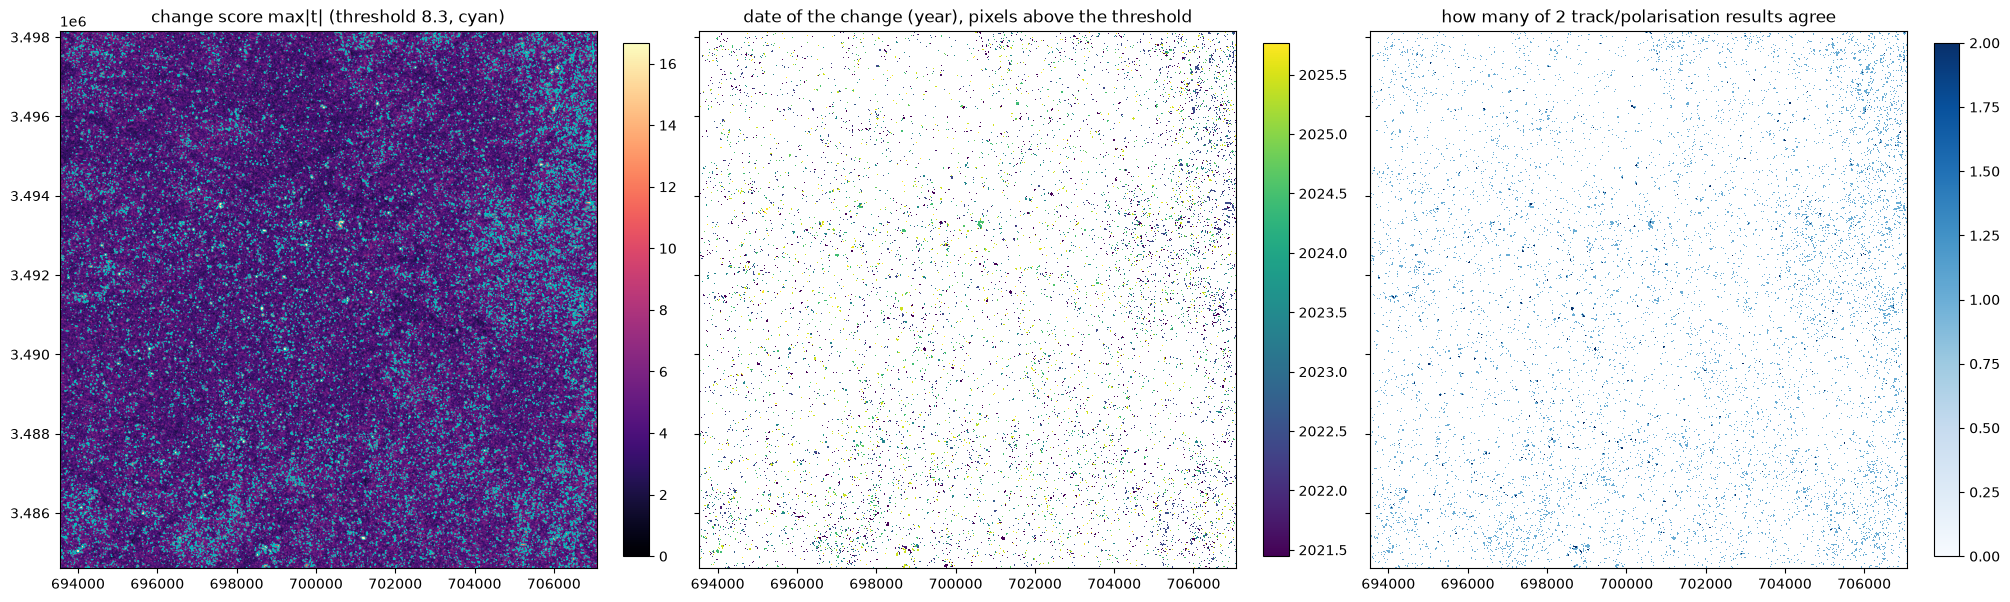

which result gave the score (share of pixels above the threshold): {'D094_VV_tc_cr_ln400': 0.74, 'D094_VH_tc_cr_ln400': 0.26}


In [11]:
year = lambda ordinal: np.where(np.isfinite(ordinal), 1 + (np.nan_to_num(ordinal) - date(1, 1, 1).toordinal()) / 365.2425, np.nan)
hot = (COMB["score"] >= THRESH) & (COMB["confirm"] != 0)
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), constrained_layout=True, sharex=True, sharey=True)
im = axes[0].imshow(np.where(valid10, COMB["score"], np.nan), extent=EXTENT10, cmap="magma", vmin=0, vmax=max(THRESH * 2, 1))
axes[0].contour(np.arange(W10) * GRID10_M + left, top - np.arange(H10) * GRID10_M, hot.astype(float), [0.5], colors="c", linewidths=0.5)
axes[0].set_title(f"change score max|t| (threshold {THRESH:.1f}, cyan)"); fig.colorbar(im, ax=axes[0], shrink=0.8)
im = axes[1].imshow(np.where(hot, year(COMB["split"]), np.nan), extent=EXTENT10, cmap="viridis", interpolation="nearest")
axes[1].set_title("date of the change (year), pixels above the threshold"); fig.colorbar(im, ax=axes[1], shrink=0.8)
im = axes[2].imshow(np.where(hot, COMB["agree"], np.nan), extent=EXTENT10, cmap="Blues", vmin=0, vmax=len(COMB_NAMES), interpolation="nearest")
axes[2].set_title(f"how many of {len(COMB_NAMES)} track/polarisation results agree"); fig.colorbar(im, ax=axes[2], shrink=0.8)
plt.show()
print("which result gave the score (share of pixels above the threshold):",
      {COMB_NAMES[k]: round(float((COMB["best"][hot] == k).mean()), 2) for k in range(len(COMB_NAMES))})

## 7. Candidates and their type

| Candidate | Rule | Why this rule |
|---|---|---|
| **Demolition candidate** | a footprint whose mean change score ≥ the **building threshold**, and at least `MIN_CONFIRMED_FRAC` of its changed pixels held their new level | demolition needs a building that stood before; PWTT scores a building by the mean over its footprint |

**Building threshold.** A building's score averages several pixels that are correlated (speckle filter, resampling), so its null distribution is narrower than that of one pixel's maximum. It has its own permutation null: for `N_NULL_BUILDINGS` random footprints, the dates are shuffled (one permutation per footprint, applied to all its pixels together), the same search is run, and the footprint mean is taken; the `NULL_QUANTILE_BUILDING` quantile is the threshold. 0.995 means about 5 of every 1,000 unchanged buildings exceed it under the null; the quiet-period test (9a) measures the real rate.
| **Construction candidate** | a group of ≥ `CON_MIN_AREA_M2` changed pixels off every footprint (and one pixel away from them), within `CONSTRUCTION_ZONE_M` of buildings or in the settlement mask, and **not** within `SPILLOVER_M` of a demolition candidate of the same date (± `DATE_TOL_DAYS`) | construction appears where no building stood; a demolition also changes the pixels around the footprint (PWTT: false positives cluster next to real damage), which would otherwise appear as "construction" |

Attributes on every candidate: date (first acquisition showing the change), score, `agree`, VV and VH change (dB), `pre_trend` (abrupt or gradual), confirmed / unconfirmed, and (section 8) coherence support. A change on an existing footprint can also be an extension or a new storey: the type rule cannot tell that from demolition, which is one more reason to confirm each candidate on imagery. **The sign of the backscatter change is reported but not used**: published results show it can go either way after destruction.

In [12]:
delta_by_pol = {}
for pol in GRD_POLS:
    names = [n for n in COMB_NAMES if n.endswith(pol)]
    if names:                                   # the change of the result with the largest |t| of that polarisation
        a = np.stack([np.abs(RESULTS_BY_COMBO[n]["t"]) for n in names])
        k = np.argmax(np.nan_to_num(a), axis=0)
        delta_by_pol[f"d{pol.lower()}_db"] = np.take_along_axis(np.stack([RESULTS_BY_COMBO[n]["delta"] for n in names]), k[None], 0)[0]

# Building threshold from a building-level permutation null: the dates of a sample of footprints are shuffled (one
# permutation per footprint, applied to all its pixels), the same search is run, and the mean over the footprint taken.
rng_b = np.random.default_rng(SEED + 2)
sample_f = np.sort(rng_b.choice(len(fp), size=min(N_NULL_BUILDINGS, len(fp)), replace=False))
sel = np.isin(FID, sample_f)
s_pix, s_grp = FPIX[sel], np.searchsorted(sample_f, FID[sel])
series_b, t_b, sp_b = {}, {}, {}
for key, pol in COMBOS:
    store = STORES[(key, pol)]
    filled = store.filled_dates()
    mm = store.memmap("r")
    series_b[combo_name(key, pol)] = np.stack([np.asarray(mm[store.dates.index(d)]).ravel()[s_pix] for d in filled]).astype("float64")
    del mm
    t_b[combo_name(key, pol)] = np.array([date.fromisoformat(d).toordinal() for d in filled], float)
    sp_b[combo_name(key, pol)] = ht.split_dates(t_b[combo_name(key, pol)], TEST)
null_b = ht.footprint_null_scores(series_b, t_b, sp_b, s_grp, TEST, rng_b)
THRESH_B = float(T_THRESHOLD_BUILDING) if T_THRESHOLD_BUILDING else float(np.nanquantile(null_b, NULL_QUANTILE_BUILDING))
THRESH_B_PIXELS = float(np.nanquantile(null_b, NULL_QUANTILE_BUILDING))   # the pixel-test building threshold (7b-7c)
print(f"pixel-test building threshold: mean |t| = {THRESH_B:.2f} ({'fixed' if T_THRESHOLD_BUILDING else f'{NULL_QUANTILE_BUILDING} quantile of '
      f'the building null, {len(sample_f)} footprints'}); pixel threshold {THRESH:.2f}")

BRIGHT = None
if BUILDING_TEST == "step":
    # every building's mean over its pixels, date by date, per track/polarisation
    def building_series(store, dates):
        mm = store.memmap("r")
        out = np.full((len(dates), len(fp)), np.nan, "float32")
        for k, d in enumerate(dates):
            v = np.asarray(mm[store.dates.index(d)]).ravel()[FPIX]
            ok = np.isfinite(v)
            s_ = np.bincount(FID[ok], weights=v[ok], minlength=len(fp))
            n_ = np.bincount(FID[ok], minlength=len(fp))
            out[k] = np.where(n_ > 0, s_ / np.maximum(n_, 1), np.nan)
        del mm
        return out

    BSER, BT = {}, {}
    for key, pol in COMBOS:
        filled = STORES[(key, pol)].filled_dates()
        BSER[combo_name(key, pol)] = building_series(STORES[(key, pol)], filled)
        BT[combo_name(key, pol)] = np.array([date.fromisoformat(d).toordinal() for d in filled], float)
    SV_AREA = {n: float(np.nanmedian(ht.season_excess_var(x, BT[n]))) for n, x in BSER.items()}
    # threshold: the same test on the sampled buildings with whole seasons shuffled (each building's wobble kept)
    rng_s = np.random.default_rng(SEED + 3)
    null_s = None
    for n, x in BSER.items():
        xs = x[:, sample_f].astype("float64")
        xs = np.take_along_axis(xs, ht.season_block_order(BT[n], xs.shape[1], rng_s).T, axis=0)
        a = np.abs(ht.step_test(xs, BT[n], season_var=SV_AREA[n], season_starts_only=STEP_SEASON_STARTS_ONLY)["t"])
        null_s = a if null_s is None else np.maximum(null_s, a)
    THRESH_B = float(T_THRESHOLD_BUILDING) if T_THRESHOLD_BUILDING else float(np.nanquantile(null_s, NULL_QUANTILE_BUILDING))
    RES_B = {n: ht.step_test(x.astype("float64"), BT[n], season_var=SV_AREA[n], season_starts_only=STEP_SEASON_STARTS_ONLY)
             for n, x in BSER.items()}
    names_b = list(RES_B)
    ab = np.stack([np.abs(RES_B[n]["t"]) for n in names_b])
    kb = np.argmax(ab, axis=0)
    pick = lambda key: np.take_along_axis(np.stack([RES_B[n][key] for n in names_b]), kb[None], 0)[0]
    bld = fp[["area_m2", "geometry"]].copy()
    bld["score"], bld["t"], bld["split"], bld["delta_db"] = ab.max(0), pick("t"), pick("split"), pick("delta")
    for n in names_b:                                   # each polarisation's own step (dB) at its own best date
        bld[f"d{n.split('_')[1].lower()}_db"] = RES_B[n]["delta"]
    bld["agree"] = (ab >= THRESH_B).sum(0)
    bld["direction"] = np.where(bld["delta_db"] < 0, "darker", "brighter")
    bld["date"] = [date.fromordinal(int(v)).isoformat() if np.isfinite(v) else None for v in bld["split"]]
    last_season = max(SEASON_FIRST_ALL) if (SEASON_FIRST_ALL := {min(d for d in STORES[c].filled_dates() if d[:4] == y)
                                                                for c in COMBOS for y in {d[:4] for d in STORES[c].filled_dates()}}) else None
    bld["changed"] = bld["score"] >= THRESH_B
    bld["status"] = np.where(bld["date"] == last_season, "unconfirmed (last season only)", "confirmed")
    is_dem = bld["changed"] & ((bld["direction"] == "darker") if DEMOLITION_DIRECTION == "darker" else True)
    DEM = bld[is_dem].copy()
    DEM["type"] = "demolition candidate"
    BRIGHT = bld[bld["changed"] & ~is_dem].copy()
    BRIGHT["type"] = "brightening (building activity, or rubble)"
    print(f"building step test: threshold |t| = {THRESH_B:.2f} ({NULL_QUANTILE_BUILDING} quantile, whole seasons shuffled, "
          f"{len(sample_f)} buildings); typical season wobble of a building mean: "
          + ", ".join(f"{n} {v:.2f} dB²" for n, v in SV_AREA.items()))
    print(f"{len(bld)} buildings scored; {int(bld['changed'].sum())} above the threshold: {len(DEM)} demolition candidates "
          f"({DEMOLITION_DIRECTION}), {len(BRIGHT)} brightening")
else:
    fs = ht.footprint_scores(FID, FPIX, len(fp), COMB, THRESH, extra=delta_by_pol)
    bld = fp[["area_m2", "geometry"]].join(fs)
    bld["date"] = [date.fromordinal(int(v)).isoformat() if np.isfinite(v) else None for v in bld["split"]]
    bld["changed"] = bld["score"] >= THRESH_B
    bld["status"] = np.where(bld["untestable_frac"] > 0.5, "unconfirmed (end of series)",
                             np.where(bld["confirmed_frac"] >= MIN_CONFIRMED_FRAC, "confirmed", "not held"))
    DEM = bld[bld["changed"] & (bld["status"] != "not held")].copy()
    DEM["type"] = "demolition candidate"
    print(f"{len(bld)} buildings scored; {int(bld['changed'].sum())} above the threshold; "
          f"{len(DEM)} demolition candidates ({int((DEM['status'] == 'confirmed').sum())} confirmed)")

off_fp = ~binary_dilation(ON_FOOTPRINT, iterations=1)
con_mask = (COMB["score"] >= THRESH) & (COMB["confirm"] != 0) & off_fp & CON_ZONE
layers = {"score": COMB["score"], "split": COMB["split"], "pre_trend": COMB["pre_trend"], "agree": COMB["agree"], **delta_by_pol}
CON_LAB, con_feats = ht.change_clusters(con_mask, GRID10_T, GRID10_M, CON_MIN_AREA_M2, layers)
CON = gpd.GeoDataFrame.from_features(con_feats, crs=GRID_CRS) if con_feats else gpd.GeoDataFrame(geometry=[], crs=GRID_CRS)
if len(CON):
    CON["date"] = [date.fromordinal(int(round(v))).isoformat() for v in CON["split_median"]]
    CON["type"] = "construction candidate"
if len(CON) and len(DEM):        # spillover: a demolition also changes the pixels next to the footprint
    dd = np.array([date.fromisoformat(d).toordinal() if d else np.nan for d in DEM["date"]])
    spill = []
    for g, sp in zip(CON.geometry, CON["split_median"]):
        near = (DEM.geometry.distance(g) <= SPILLOVER_M).to_numpy() & (np.abs(dd - sp) <= DATE_TOL_DAYS)
        spill.append(bool(near.any()))
    spill = np.array(spill)
    print(f"{int(spill.sum())} off-footprint clusters next to a demolition candidate of the same date: treated as its spillover")
    CON = CON[~spill].reset_index(drop=True)
print(f"{len(CON)} construction candidates ({CON['area_m2'].sum() / 1e4 if len(CON) else 0:.1f} ha)")

per_year = pd.DataFrame({
    "demolition candidates": pd.Series([d[:4] for d in DEM["date"].dropna()]).value_counts(),
    "brightening": pd.Series([d[:4] for d in BRIGHT["date"].dropna()] if BRIGHT is not None else [], dtype=str).value_counts(),
    "construction candidates": pd.Series([d[:4] for d in CON["date"]] if len(CON) else [], dtype=str).value_counts(),
}).fillna(0).astype(int).sort_index()
display(per_year)
SEASON_FIRST = {min(d for d in STORES[c].filled_dates() if d[:4] == y) for c in COMBOS for y in {d[:4] for d in STORES[c].filled_dates()}}
if len(DEM) and not (BUILDING_TEST == "step" and STEP_SEASON_STARTS_ONLY):   # the step test dates every change to a season start
    print(f"share of demolition candidates dated on the first image of a dry season: {DEM['date'].isin(SEASON_FIRST).mean():.0%} "
          f"(one image in {np.mean([len([d for d in STORES[c].filled_dates()]) for c in COMBOS]) / max(len(SEASON_FIRST), 1):.0f}; "
          "much more than that share points to year-to-year shifts rather than demolitions)")
if len(DEM):
    display(DEM[[c for c in ["area_m2", "score", "agree", "date", "status", "pre_trend", "delta_db", *delta_by_pol] if c in DEM]].describe().round(2))

pixel-test building threshold: mean |t| = 5.99 (0.995 quantile of the building null, 4000 footprints); pixel threshold 8.34
building step test: threshold |t| = 8.56 (0.995 quantile, whole seasons shuffled, 4000 buildings); typical season wobble of a building mean: D094_VV_tc_cr_ln400 0.24 dB², D094_VH_tc_cr_ln400 0.22 dB²
43525 buildings scored; 531 above the threshold: 116 demolition candidates (darker), 415 brightening
31 off-footprint clusters next to a demolition candidate of the same date: treated as its spillover
4364 construction candidates (406.7 ha)


,demolition candidates,brightening,construction candidates
2021,27,42,987
2022,36,66,1192
2023,19,96,831
2024,16,76,726
2025,16,100,628
2026,2,35,0


,area_m2,score,agree,delta_db
count,116.00,116.00,116.00,116.00
mean,328.09,11.53,1.07,-6.55
std,339.17,3.30,0.25,2.02
min,50.51,8.56,1.00,-15.80
25%,138.66,9.17,1.00,-7.34
50%,207.35,10.39,1.00,-6.07
75%,424.42,12.85,1.00,-5.07
max,2290.70,28.22,2.00,-3.86


### 7b. How well does this run separate change from no change? (injection test)

The same check as in the geolocation notebook (section 6C), on the footprints sampled for the building threshold, with this run's stacks:

* **False alarms on real data:** the share of sampled buildings whose real, unchanged series scores above the building threshold. It is an upper bound, because a few sampled buildings really changed. The design value is 0.5 %.
* **Detection:** each sampled building gets a step of Δ dB on a random day of the testable period, from the next acquisition on, in every polarisation. The share above the threshold is shown for 2, 3 and 4 dB, down and up.
* **On a season's first image:** the share of the false alarms dated on the first image of a dry season.

With `LOCAL_NORM_M` set, the same is computed **for the stacks without the neighbourhood level** (the previous approach), side by side, so the effect of the change is measured directly on these buildings.

In [13]:
def injection_check(series, label):
    names = list(series)
    td = {n: t_b[n] for n in names}
    sp = {n: sp_b[n] for n in names}
    nfp = len(sample_f)
    npix = np.bincount(s_grp, minlength=nfp)

    def score(xs):
        best = split = None
        for n in names:
            r = ht.change_test(xs[n], td[n], sp[n], TEST)
            a = np.abs(r["t"])
            if best is None:
                best, split = a, r["split"]
            else:
                up = a > best
                best, split = np.where(up, a, best), np.where(up, r["split"], split)
        sc = np.bincount(s_grp, weights=best, minlength=nfp) / np.maximum(npix, 1)
        sm = pd.Series(split).groupby(s_grp).median().reindex(range(nfp)).to_numpy()
        return sc, sm

    nb = ht.footprint_null_scores(series, td, sp, s_grp, TEST, np.random.default_rng(SEED + 5))
    thr = float(np.nanquantile(nb, NULL_QUANTILE_BUILDING))
    s0, split0 = score(series)
    fa = s0 >= thr
    first_days = {date.fromisoformat(d).toordinal() for d in SEASON_FIRST}
    row = {"stacks": label, "building threshold": round(thr, 2), "false alarms %": round(100 * float(fa.mean()), 1),
           "false alarms on a season's first image %": round(100 * float(np.isin(split0[fa], list(first_days)).mean()), 0) if fa.any() else np.nan}
    allsp = np.unique(np.concatenate([sp[n] for n in names]))
    ev = np.random.default_rng(SEED + 6).uniform(allsp.min() - 1, allsp.max(), size=nfp)
    for size in (2, 3, 4):
        hit = []
        for sgn in (-1, 1):
            xs = {n: series[n] + sgn * size * (td[n][:, None] > ev[s_grp][None, :]) for n in names}
            hit.append(score(xs)[0] >= thr)
        row[f"found {size} dB %"] = round(100 * float(np.mean(hit)), 1)
    return row


rows = [injection_check(series_b, "this run" + (f" (neighbourhood level, {LOCAL_NORM_M} m)" if LOCAL_NORM_M else ""))]
if LOCAL_NORM_M:
    series_base = {}
    for key, pol in COMBOS:
        st = BASE_STORES[(key, pol)]
        mm = st.memmap("r")
        series_base[combo_name(key, pol)] = np.stack([np.asarray(mm[st.dates.index(d)]).ravel()[s_pix] for d in STORES[(key, pol)].filled_dates()]).astype("float64")
        del mm
    rows.append(injection_check(series_base, "without the neighbourhood level (previous approach)"))
INJECTION_TABLE = pd.DataFrame(rows).set_index("stacks")
display(INJECTION_TABLE)
print(f"on {len(sample_f)} sampled buildings. SEND THESE NUMBERS:", INJECTION_TABLE.reset_index().to_dict("records"))

,building threshold,false alarms %,false alarms on a season's first image %,found 2 dB %,found 3 dB %,found 4 dB %
stacks,,,,,,
"this run (neighbourhood level, 400 m)",5.63,17.4,43.0,58.4,88.4,96.3
without the neighbourhood level (previous approach),5.86,15.0,45.0,53.2,85.7,95.3


on 4000 sampled buildings. SEND THESE NUMBERS: [{'stacks': 'this run (neighbourhood level, 400 m)', 'building threshold': 5.63, 'false alarms %': 17.4, "false alarms on a season's first image %": 43.0, 'found 2 dB %': 58.4, 'found 3 dB %': 88.4, 'found 4 dB %': 96.3}, {'stacks': 'without the neighbourhood level (previous approach)', 'building threshold': 5.86, 'false alarms %': 15.0, "false alarms on a season's first image %": 45.0, 'found 2 dB %': 53.2, 'found 3 dB %': 85.7, 'found 4 dB %': 95.3}]


### 7c. Diagnosis: why does real brightness vary more than the test expects?

The test compares a building's dates before and after a candidate date, and judges the difference against the scatter **between dates**. That is right only if the dates are independent. If each building also has its **own level from one dry season to the next** (a water tank, a parked car, a bright wall sampled a little differently, vegetation), dates within one season agree with each other more than with other seasons. A normal year-to-year wobble then looks like a significant change.

For the sampled buildings, per pixel:
* **within-season scatter:** the variance of the dates around their own season's mean;
* **between-season scatter:** the variance of the season means, from one season to the next. Measured robustly, from the differences between consecutive seasons, so that one real step does not inflate it.
* **F** = between-season variance ÷ (within-season variance ÷ dates per season). With independent dates F ≈ 1. F = 9 would mean the season-to-season wobble is 3 times larger than the test allows for.

Also shown:
* **when the false alarms are dated:** whether they cluster at the changes in image processing (first images of 2022, 2025, 2026);
* **six false-alarm buildings, season by season:** what they look like.

,dates per season,within-season sd (dB),season-mean sd expected if dates independent (dB),season-mean sd measured (dB),F median,F 90th percentile
stacks,,,,,,
D094_VV_tc_cr_ln400,10.0,0.97,0.31,0.62,3.8,12.3
D094_VH_tc_cr_ln400,10.0,1.06,0.34,0.61,3.2,9.7


false alarms among the 4000 sampled buildings: 532 (13.3%); by year of the detected date:


on the season's first image,False,True,All
year,,,
2021,71,41,112
2022,59,73,132
2023,63,47,110
2024,53,42,95
2025,44,39,83
All,290,242,532


building-mean F: false alarms median 8.5, other buildings median 5.5


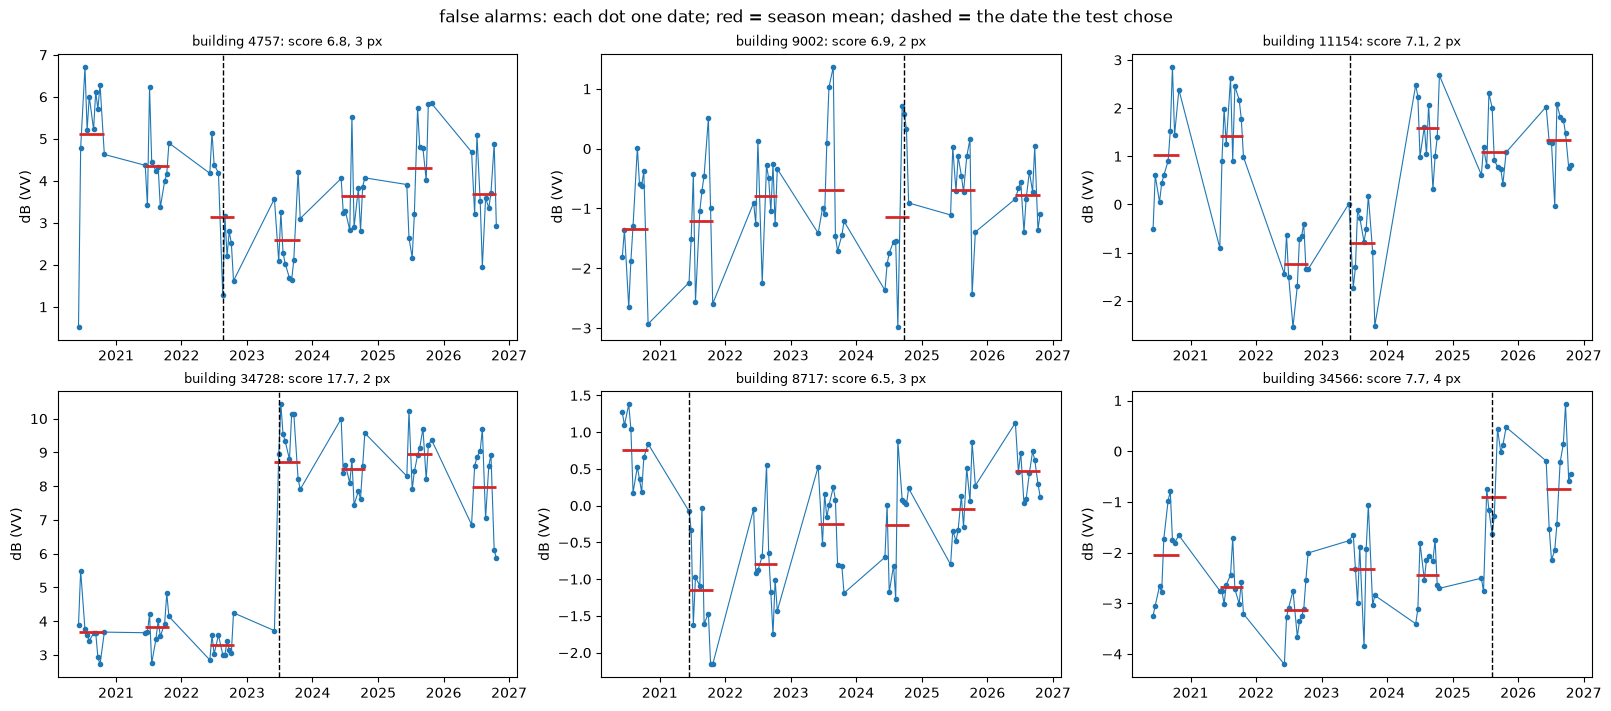

SEND THESE NUMBERS: {'diag': [{'stacks': 'D094_VV_tc_cr_ln400', 'dates per season': 10.0, 'within-season sd (dB)': 0.97, 'season-mean sd expected if dates independent (dB)': 0.31, 'season-mean sd measured (dB)': 0.62, 'F median': 3.8, 'F 90th percentile': 12.3}, {'stacks': 'D094_VH_tc_cr_ln400', 'dates per season': 10.0, 'within-season sd (dB)': 1.06, 'season-mean sd expected if dates independent (dB)': 0.34, 'season-mean sd measured (dB)': 0.61, 'F median': 3.2, 'F 90th percentile': 9.7}], 'false_alarm_rate': 0.133, 'by_year': {'2021': 112, '2022': 132, '2023': 110, '2024': 95, '2025': 83}, 'share_on_season_first': 0.45, 'F_false_alarms': 8.5, 'F_others': 5.5}


In [14]:
def season_stats(x, td):
    # x: (dates, pixels) dB; td: ordinal days -> within-season variance, robust between-season variance, dates per season
    yrs = np.array([date.fromordinal(int(t)).year for t in td])
    seasons = sorted(set(yrs))
    means, within, nper = [], [], []
    for y in seasons:
        xs = x[yrs == y]
        m = np.nanmean(xs, 0)
        means.append(m)
        nper.append(len(xs))
        within.append(np.nansum((xs - m) ** 2, 0) / max(len(xs) - 1, 1))
    means = np.array(means)
    w = np.nanmean(np.array(within), 0)
    dm = np.abs(np.diff(means, axis=0))                     # consecutive seasons
    sb = (np.nanmedian(dm, 0) / 0.954) ** 2                 # robust variance of a season mean (median |diff| = 0.954 sigma)
    return w, sb, float(np.mean(nper)), seasons, means


rows_d, F_by = [], {}
for n, x in series_b.items():
    w, sb, nbar, seasons, means = season_stats(x, t_b[n])
    F = sb / (w / nbar)
    F_by[n] = F
    rows_d.append({"stacks": n, "dates per season": round(nbar, 1), "within-season sd (dB)": round(float(np.nanmedian(np.sqrt(w))), 2),
                   "season-mean sd expected if dates independent (dB)": round(float(np.nanmedian(np.sqrt(w / nbar))), 2),
                   "season-mean sd measured (dB)": round(float(np.nanmedian(np.sqrt(sb))), 2),
                   "F median": round(float(np.nanmedian(F)), 1), "F 90th percentile": round(float(np.nanpercentile(F, 90)), 1)})
DIAG = pd.DataFrame(rows_d).set_index("stacks")
display(DIAG)

# the false alarms of the sampled buildings (real series, no change added), and when they are dated
names = list(series_b)
nfp = len(sample_f)
npix = np.bincount(s_grp, minlength=nfp)
best = split = None
for n in names:
    r = ht.change_test(series_b[n], t_b[n], sp_b[n], TEST)
    a = np.abs(r["t"])
    best, split = (a, r["split"]) if best is None else (np.where(a > best, a, best), np.where(a > best, r["split"], split))
sc0 = np.bincount(s_grp, weights=best, minlength=nfp) / np.maximum(npix, 1)
sp0 = pd.Series(split).groupby(s_grp).median().reindex(range(nfp)).to_numpy()
fa0 = sc0 >= THRESH_B_PIXELS
dated = pd.Series([date.fromordinal(int(v)).isoformat() if np.isfinite(v) else None for v in sp0[fa0]])
first_of = {d: d[:4] for d in SEASON_FIRST}
tab = pd.DataFrame({"year": dated.str[:4], "on the season's first image": dated.isin(SEASON_FIRST)})
print(f"false alarms among the {nfp} sampled buildings: {int(fa0.sum())} ({fa0.mean():.1%}); by year of the detected date:")
display(pd.crosstab(tab["year"], tab["on the season's first image"], margins=True))

# F of the false-alarm buildings against the others
Fb = np.bincount(s_grp, weights=np.nan_to_num(np.nanmax(np.stack([F_by[n] for n in names]), 0)), minlength=nfp) / np.maximum(npix, 1)
print(f"building-mean F: false alarms median {np.nanmedian(Fb[fa0]):.1f}, other buildings median {np.nanmedian(Fb[~fa0]):.1f}")

# six false-alarm buildings, season by season (VV), with the date the test chose
pick = np.random.default_rng(3).choice(np.flatnonzero(fa0), size=min(6, int(fa0.sum())), replace=False) if fa0.any() else []
nv = next((n for n in names if "VV" in n), names[0])
fig, axes = plt.subplots(2, 3, figsize=(16, 7), constrained_layout=True, squeeze=False)
for ax, b in zip(axes.ravel(), pick):
    cols = np.flatnonzero(s_grp == b)
    y = np.nanmean(series_b[nv][:, cols], 1)
    days = [date.fromordinal(int(t)) for t in t_b[nv]]
    ax.plot(days, y, "o-", ms=3, lw=0.8)
    yrs = np.array([d.year for d in days])
    for yy in sorted(set(yrs)):
        m = yrs == yy
        ax.hlines(np.nanmean(y[m]), min(np.array(days)[m]), max(np.array(days)[m]), color="tab:red", lw=2)
    if np.isfinite(sp0[b]):
        ax.axvline(date.fromordinal(int(sp0[b])), color="k", ls="--", lw=1)
    ax.set_title(f"building {sample_f[b]}: score {sc0[b]:.1f}, {len(cols)} px", fontsize=9)
    ax.set_ylabel("dB (VV)")
fig.suptitle("false alarms: each dot one date; red = season mean; dashed = the date the test chose")
plt.show()
print("SEND THESE NUMBERS:", {"diag": DIAG.reset_index().to_dict("records"), "false_alarm_rate": round(float(fa0.mean()), 4),
                              "by_year": tab["year"].value_counts().sort_index().to_dict(),
                              "share_on_season_first": round(float(tab["on the season's first image"].mean()), 2),
                              "F_false_alarms": round(float(np.nanmedian(Fb[fa0])), 1), "F_others": round(float(np.nanmedian(Fb[~fa0])), 1)})

### 7d. Testing whole buildings, with their own year-to-year wobble (measured on the sampled buildings)

7c showed that each pixel's level wobbles from one dry season to the next, about twice as much as independent dates would give, and the test ignores this. Two changes are compared here, on the same sampled buildings and with the same injected steps:

1. **Average first, then test.** Each building's pixels are averaged on every date, and its one averaged series is tested. Wobble that differs from pixel to pixel partly cancels; a demolition drops the whole footprint and does not.
2. **Allow for the wobble.** The test's uncertainty includes the building's own season-to-season variation (`season_effect`), measured from its seasons, either per building or as one typical value for the whole area. The threshold then comes from shuffling **whole seasons** (and dates within them), not single dates, so that it keeps the wobble too.

3. **Use every season (the "STEP" lines).** A demolition lasts, so every later season is evidence. The step test compares **all** dates before a candidate date with **all** dates from it on, which divides the wobble by the number of seasons on each side. With "season starts", only the first date of each season is tried: fewer tries, so a lower bar, and a change during a season is dated to the next season's start.

Each line: the threshold (99.5 % quantile of its own null), the false alarms on the real, unchanged series (design: 0.5 %), and the share of injected steps found (2, 3, 4, 6 dB, down and up, from a random day on).

In [15]:
def footprint_means(x):
    # (dates, pixels) -> (dates, footprints): each sampled building's mean over its pixels, date by date
    nf = len(sample_f)
    out = np.full((x.shape[0], nf), np.nan)
    for i in range(x.shape[0]):
        v = x[i]
        ok = np.isfinite(v)
        s_ = np.bincount(s_grp[ok], weights=v[ok], minlength=nf)
        n_ = np.bincount(s_grp[ok], minlength=nf)
        out[i] = np.where(n_ > 0, s_ / np.maximum(n_, 1), np.nan)
    return out


BM = {n: footprint_means(series_b[n]) for n in series_b}
P_OLD = TEST
P_SEASON = ht.TestParams(**{**TEST.__dict__, "season_effect": True})
nfp = len(sample_f)
half = np.arange(nfp) % 2 == 0                     # null from one half of the buildings, false alarms on the other
ev = np.random.default_rng(SEED + 7).uniform(min(sp.min() for sp in sp_b.values()) - 1, max(sp.max() for sp in sp_b.values()), size=nfp)


def run_test(kind, n, x, p, sv):
    if kind == "windows":                          # the current test: a year before, 150 days after
        return np.abs(ht.change_test(x, t_b[n], sp_b[n], p, season_var=sv(n, x))["t"])
    return np.abs(ht.step_test(x, t_b[n], season_var=sv(n, x), season_starts_only=(kind == "step, season starts"))["t"])


def scores(series, p, sv, kind):
    out = None
    for n, x in series.items():
        a = run_test(kind, n, x, p, sv)
        out = a if out is None else np.maximum(out, a)
    return out


def variant(label, p, sv, kind="windows", block=None):
    rng_v = np.random.default_rng(SEED + 8)
    block = p.season_effect if block is None else block
    null = None
    for n, x in BM.items():
        xn = x[:, half]
        order = (ht.season_block_order(t_b[n], xn.shape[1], rng_v).T if block
                 else np.argsort(rng_v.random(xn.shape), axis=0))
        xs = np.take_along_axis(xn, order, axis=0)
        a = run_test(kind, n, xs, p, sv)
        null = a if null is None else np.maximum(null, a)
    thr = float(np.nanquantile(null, NULL_QUANTILE_BUILDING))
    real = scores({n: x[:, ~half] for n, x in BM.items()}, p, sv, kind)
    row = {"variant": label, "threshold": round(thr, 2), "false alarms %": round(100 * float(np.mean(real >= thr)), 2)}
    for size in (2, 3, 4, 6):
        hit = []
        for sgn in (-1, 1):
            xs = {n: x[:, ~half] + sgn * size * (t_b[n][:, None] > ev[~half][None, :]) for n, x in BM.items()}
            hit.append(scores(xs, p, sv, kind) >= thr)
        row[f"found {size} dB %"] = round(100 * float(np.mean(hit)), 1)
    return row


AREA_SV = {n: float(np.nanmedian(ht.season_excess_var(x, t_b[n]))) for n, x in BM.items()}
rows7d = [variant("building mean, dates independent (no wobble term)", P_OLD, lambda n, x: None),
          variant("building mean + its own wobble", P_SEASON, lambda n, x: None),
          variant("building mean + one typical wobble for the area", P_SEASON, lambda n, x: AREA_SV[n]),
          variant("building mean + half own, half typical", P_SEASON, lambda n, x: 0.5 * ht.season_excess_var(x, t_b[n]) + 0.5 * AREA_SV[n]),
          variant("STEP: all before vs all after, every date, own wobble", P_SEASON, lambda n, x: None, kind="step, every date", block=True),
          variant("STEP: all before vs all after, season starts, own wobble", P_SEASON, lambda n, x: None, kind="step, season starts", block=True),
          variant("STEP: all before vs all after, season starts, typical wobble", P_SEASON, lambda n, x: AREA_SV[n], kind="step, season starts", block=True)]
T7D = pd.DataFrame(rows7d).set_index("variant")
print(f"{nfp} sampled buildings (null from half, false alarms and detection on the other half); typical wobble variance "
      f"of a building mean: {', '.join(f'{n}: {v:.3f} dB²' for n, v in AREA_SV.items())}")
display(T7D)
print("for comparison, 7b (current method, pixel tests averaged): see the table above")
print("SEND THESE NUMBERS:", {"table": T7D.reset_index().to_dict("records"), "area_wobble_var": {n: round(v, 3) for n, v in AREA_SV.items()}})

4000 sampled buildings (null from half, false alarms and detection on the other half); typical wobble variance of a building mean: D094_VV_tc_cr_ln400: 0.244 dB², D094_VH_tc_cr_ln400: 0.213 dB²


,threshold,false alarms %,found 2 dB %,found 3 dB %,found 4 dB %,found 6 dB %
variant,,,,,,
"building mean, dates independent (no wobble term)",6.09,14.90,49.4,82.1,93.5,97.9
building mean + its own wobble,7.09,1.15,4.2,14.8,31.5,64.8
building mean + one typical wobble for the area,8.14,0.85,1.8,5.9,14.1,61.3
"building mean + half own, half typical",7.16,1.00,2.4,8.2,21.2,67.4
"STEP: all before vs all after, every date, own wobble",6.66,4.70,25.3,51.6,73.9,92.8
"STEP: all before vs all after, season starts, own wobble",6.39,4.25,23.1,48.8,69.6,89.5
"STEP: all before vs all after, season starts, typical wobble",7.18,2.90,7.4,38.8,80.8,98.4


for comparison, 7b (current method, pixel tests averaged): see the table above
SEND THESE NUMBERS: {'table': [{'variant': 'building mean, dates independent (no wobble term)', 'threshold': 6.09, 'false alarms %': 14.9, 'found 2 dB %': 49.4, 'found 3 dB %': 82.1, 'found 4 dB %': 93.5, 'found 6 dB %': 97.9}, {'variant': 'building mean + its own wobble', 'threshold': 7.09, 'false alarms %': 1.15, 'found 2 dB %': 4.2, 'found 3 dB %': 14.8, 'found 4 dB %': 31.5, 'found 6 dB %': 64.8}, {'variant': 'building mean + one typical wobble for the area', 'threshold': 8.14, 'false alarms %': 0.85, 'found 2 dB %': 1.8, 'found 3 dB %': 5.9, 'found 4 dB %': 14.1, 'found 6 dB %': 61.3}, {'variant': 'building mean + half own, half typical', 'threshold': 7.16, 'false alarms %': 1.0, 'found 2 dB %': 2.4, 'found 3 dB %': 8.2, 'found 4 dB %': 21.2, 'found 6 dB %': 67.4}, {'variant': 'STEP: all before vs all after, every date, own wobble', 'threshold': 6.66, 'false alarms %': 4.7, 'found 2 dB %': 25.3, 'found 

### 7e. How many of the candidates would noise alone give?

The threshold lets through about 5 in 1,000 unchanged buildings (its 0.995 quantile), in either direction. With tens of thousands of buildings that is a few hundred candidates even if nothing changed. Real change shows only as an **excess** over that number.

Here the step test is run again on the sampled buildings with whole seasons shuffled, which removes any lasting change but keeps each building's noise and wobble. The hits are counted by direction, by year, and for the stricter rule "both VV and VH pass", then scaled to all buildings. Compare *found* with *expected from noise alone*: only the excess is evidence of change.

In [16]:
# how many candidates would noise alone give? The step test on the sampled buildings with whole seasons shuffled (no lasting
# change left), repeated N_NOISE_RUNS times, the same shuffle for VV and VH so their shared wobble is kept; scaled to all buildings
N_NOISE_RUNS = 10
if BUILDING_TEST == "step":
    rng_e = np.random.default_rng(SEED + 7)
    names_e = list(BSER)
    same_dates = all(np.array_equal(BT[n], BT[names_e[0]]) for n in names_e)
    rows_n = []
    for _ in range(N_NOISE_RUNS):
        order = None
        res = {}
        for n in names_e:
            xs = BSER[n][:, sample_f].astype("float64")
            if order is None or not same_dates:
                order = ht.season_block_order(BT[n], xs.shape[1], rng_e).T
            xs = np.take_along_axis(xs, order, axis=0)
            res[n] = ht.step_test(xs, BT[n], season_var=SV_AREA[n], season_starts_only=STEP_SEASON_STARTS_ONLY)
        a = np.stack([np.abs(res[n]["t"]) for n in names_e])
        k = np.argmax(a, 0)
        t_ = np.take_along_axis(np.stack([res[n]["t"] for n in names_e]), k[None], 0)[0]
        s_ = np.take_along_axis(np.stack([res[n]["split"] for n in names_e]), k[None], 0)[0]
        hit = a.max(0) >= THRESH_B
        rows_n.append(pd.DataFrame({"direction": np.where(t_[hit] < 0, "darker", "brighter"), "agree": (a[:, hit] >= THRESH_B).sum(0),
                                    "year": [date.fromordinal(int(v)).year for v in s_[hit]]}))
    noise = pd.concat(rows_n, ignore_index=True)
    scale = len(bld) / (len(sample_f) * N_NOISE_RUNS)          # noise hits per sampled building, times all buildings
    obs = bld[bld["changed"]].assign(year=lambda d: d["date"].str[:4].astype(int))

    def compare(by, o, nz):
        out = pd.DataFrame({"found": o.groupby(by).size(), "expected from noise alone": nz.groupby(by).size() * scale}).fillna(0)
        out["expected from noise alone"] = out["expected from noise alone"].round(0)
        out["excess (found - noise)"] = out["found"] - out["expected from noise alone"]
        return out.astype(int)

    print(f"{len(bld)} buildings, threshold |t| = {THRESH_B:.2f}; noise: {N_NOISE_RUNS} season shuffles of {len(sample_f)} buildings")
    T7E = compare("direction", obs, noise)
    display(T7E)
    print("only buildings where both VV and VH pass the threshold:")
    T7E2 = compare("direction", obs[obs["agree"] >= 2], noise[noise["agree"] >= 2])
    display(T7E2)
    print("by year of the detected date:")
    T7E3 = pd.concat({d: compare("year", obs[obs["direction"] == d], noise[noise["direction"] == d]) for d in ["darker", "brighter"]}, axis=1).fillna(0).astype(int)
    display(T7E3)
    print("SEND THESE NUMBERS:", {"all": T7E.reset_index().to_dict("records"), "both_pols": T7E2.reset_index().to_dict("records"),
                                  "by_year": T7E3.reset_index().to_dict("records")})
else:
    print("7e is written for the step test (BUILDING_TEST = 'step')")

43525 buildings, threshold |t| = 8.56; noise: 10 season shuffles of 4000 buildings


,found,expected from noise alone,excess (found - noise)
direction,,,
brighter,415,73,342
darker,116,60,56


only buildings where both VV and VH pass the threshold:


,found,expected from noise alone,excess (found - noise)
direction,,,
brighter,63,5,58
darker,8,2,6


by year of the detected date:


darker                                                  brighter  \
      found expected from noise alone excess (found - noise)    found   
year                                                                    
2021     27                        22                      5       42   
2022     36                        11                     25       66   
2023     19                         3                     16       96   
2024     16                         7                      9       76   
2025     16                         7                      9      100   
2026      2                        11                     -9       35   

                                                       
     expected from noise alone excess (found - noise)  
year                                                   
2021                        12                     30  
2022                         7                     59  
2023                        11                     85  
2024                        11                     65  
2025                        10                     90  
2026                        23                     12

SEND THESE NUMBERS: {'all': [{'direction': 'brighter', 'found': 415, 'expected from noise alone': 73, 'excess (found - noise)': 342}, {'direction': 'darker', 'found': 116, 'expected from noise alone': 60, 'excess (found - noise)': 56}], 'both_pols': [{'direction': 'brighter', 'found': 63, 'expected from noise alone': 5, 'excess (found - noise)': 58}, {'direction': 'darker', 'found': 8, 'expected from noise alone': 2, 'excess (found - noise)': 6}], 'by_year': [{('year', ''): 2021, ('darker', 'found'): 27, ('darker', 'expected from noise alone'): 22, ('darker', 'excess (found - noise)'): 5, ('brighter', 'found'): 42, ('brighter', 'expected from noise alone'): 12, ('brighter', 'excess (found - noise)'): 30}, {('year', ''): 2022, ('darker', 'found'): 36, ('darker', 'expected from noise alone'): 11, ('darker', 'excess (found - noise)'): 25, ('brighter', 'found'): 66, ('brighter', 'expected from noise alone'): 7, ('brighter', 'excess (found - noise)'): 59}, {('year', ''): 2023, ('darker', 'f

## 8. Coherence support (optional, SLC)

The SLC chain of v5 (same-satellite 12-day pairs, with the fixes made since: DEM margin 0.1°, the "is this pair done" check that reads the saved results, and the workaround for pygeofetch's `download_and_extract` date lookup). Coherence is **supporting evidence** here: for every candidate whose date falls inside the coherence period, `coh_support` says whether the coherence dropped by at least `COH_DROP` at that place within `TOL_DAYS` of the candidate's date (in cells normally coherent, ≥ `COH_STABLE`). Outside the period it is empty. Set `RUN_COHERENCE = False` to skip the section.

In [17]:
def fetch_orbits(items):
    """{date: orbit file}. Precise orbits appear about 3 weeks after acquisition; newer scenes get restituted orbits."""
    out = {}
    for item in items:
        for kind in ("precise", "restituted"):
            try:
                path = fetch_orbit_file(product_name=name_of(item), output_dir=str(DATA / "slc/orbits"), orbit_type=kind)
            except Exception:
                path = None
            if path:
                out[str(item.datetime)[:10]] = path
                break
    return out


def plan_pairs(items, orbit_files, max_days=13):
    """Consecutive acquisitions of the same satellite, at most max_days apart, both with an orbit file."""
    by_sat = {}
    for item in items:
        d = str(item.datetime)[:10]
        if d in orbit_files:
            by_sat.setdefault(name_of(item)[:3], []).append(d)
    return [(a, b) for ds in by_sat.values() for a, b in zip(sorted(ds), sorted(ds)[1:])
            if (date.fromisoformat(b) - date.fromisoformat(a)).days <= max_days]


if RUN_COHERENCE:
    project = InSARProject(name="hebron", aoi=aoi, output_dir=DATA / "slc", polarisation="VV", providers=["copernicus"],
                           streaming_cleanup=STREAMING_CLEANUP)
    slc_found = project.search(start_date=SLC_START, end_date=SLC_END, max_results=500, show_map=False)
    slc_items = one_per_date([i for i in slc_found if covers_aoi(i)], TRACK, SLC_DATES)
    if not SLC_DATES:      # one satellite only: its scenes make the pairs
        sat = Counter(name_of(i)[:3] for i in slc_items).most_common(1)[0][0]
        slc_items = [i for i in slc_items if name_of(i)[:3] == sat]
    slc_items = newest_or_first(slc_items, MAX_SLC)
    slc_by_date = {str(i.datetime)[:10]: i for i in slc_items}
    orbits = fetch_orbits(slc_items)
    pairs = plan_pairs(slc_items, orbits)
    print(f"{len(slc_items)} SLC acquisitions on track {TRACK}; orbit files for {len(orbits)}; {len(pairs)} pairs")

    # DEM for the whole radar crop: box plus 35 % of its span on each side, at least 0.1 deg (0.05 left 1.3 % uncovered)
    import math
    need_dem = (math.floor((BBOX[0] - max(0.35 * (BBOX[2] - BBOX[0]), 0.10)) * 1e4) / 1e4,
                             math.floor((BBOX[1] - max(0.35 * (BBOX[3] - BBOX[1]), 0.10)) * 1e4) / 1e4,
                             math.ceil((BBOX[2] + max(0.35 * (BBOX[2] - BBOX[0]), 0.10)) * 1e4) / 1e4,
                             math.ceil((BBOX[3] + max(0.35 * (BBOX[3] - BBOX[1]), 0.10)) * 1e4) / 1e4)
    dem_bbox = BoundingBox(min_lon=need_dem[0], min_lat=need_dem[1], max_lon=need_dem[2], max_lat=need_dem[3])
    dem_items = client.search(SearchQuery(bbox=dem_bbox, product_type="DEM"), providers=["opentopography"])
    dem_item = (next((i for i in dem_items if "COP30" in i.id.upper()), None)
                or next((i for i in dem_items if "SRTMGL1" in i.id.upper()), dem_items[0]))
    DEM_PATH = client.download([dem_item], destination=DEM_DIR)[0].output_path
    (RESULTS / "dem_path.txt").write_text(str(DEM_PATH))
    print("DEM:", DEM_PATH, "bbox:", need_dem)

14:51:14 INFO [      engine] PyGeoFetch ready
┌ SEARCH PARAMETERS ───────────────────────────────────────────────────────┐
│ Providers  : copernicus                                                  │
│ BBox       : [35.040, 31.480, 35.180, 31.600]                            │
│ Date range : 2026-06-01  →  2026-10-31                                   │
│ Cloud max  : 100%                                                        │
│ Product    : SLC                                                         │
└──────────────────────────────────────────────────────────────────────────┘
14:51:14 INFO [  copernicus] Authenticated with Copernicus Data Space as 'appiahkubis14@gmail.com'
  ✓  copernicus                      77 scenes   2.6s
┌────────────────────────────────────────────┬────────────┬────────────────┬────────┬─────────┬──────────────┬─────────────┬───────┬───────┬──────────────────────┐
│                  SCENE ID                  │    DATE    │   SATELLITE    │ CLOUD  │ PRODUCT │ PO

⬇ 1 scene  →  /run/media/samuel-appiah-kubi/New Volume/hebronv5/dem              0/1  [00:00]

opentopo_COP30_34.94_31.38: 0.00B [00:00, ?B/s]

14:51:17 INFO [  downloader]   ↷ opentopo_COP30_34.94_31.38                    already downloaded, skipping (resume=True)
DEM: /run/media/samuel-appiah-kubi/New Volume/hebronv5/dem/opentopography/opentopo_COP30_34.99_31.43_dem.tif bbox: (34.94, 31.38, 35.28, 31.7)


In [18]:
if RUN_COHERENCE:
    gen = InterferogramGenerator(coherence_window=None, esd_enabled=True, use_gpu=False, use_real_burst_processing=True,
                                 remove_flat_earth_phase=True, memory_guard="warn")
    MIN_DEM_COVERAGE = 0.999

    def dem_coverage(a, b):
        """DEM coverage stored with a saved pair (None if the pair has no complete save)."""
        try:
            return json.loads((Path(IFG_DIR) / f"{a}_{b}" / "result.json").read_text())["metadata"]["geometry"].get("dem_coverage_fraction")
        except Exception:
            return None

    def saved_ok(a, b):
        cov = dem_coverage(a, b)
        return cov is not None and cov >= MIN_DEM_COVERAGE

    def scene_paths(d):
        return [project.extracted_slcs[d], project.download_results[d].output_path] if d in project.extracted_slcs else []

    def have(d):
        return d in project.extracted_slcs and Path(project.extracted_slcs[d]).exists()

    def process_slc_pairs(todo, redo=()):
        """One pair at a time: download what it lacks, form it, verify, delete scenes no later pair needs."""
        records = []
        for i, (a, b) in enumerate(todo):
            missing = [d for d in (a, b) if not have(d)]
            if missing:
                # pygeofetch builds its date lookup from `selected` but loops over every download of the session:
                # let it see only this call's downloads, then merge them back
                earlier = project.download_results
                project.download_results = {}
                try:
                    project.download_and_extract(selected=[slc_by_date[d] for d in missing], max_scenes=len(missing), show_map=False)
                finally:
                    project.download_results = {**earlier, **project.download_results}
            if not (have(a) and have(b)):
                print(f"{a} -> {b}: a scene could not be downloaded or extracted; pair skipped")
                continue
            spec = dict(reference=project.extracted_slcs[a], secondary=project.extracted_slcs[b],
                        reference_date=a, secondary_date=b,
                        reference_safe_zip=project.download_results[a].output_path,
                        secondary_safe_zip=project.download_results[b].output_path,
                        reference_orbit_file=orbits[a], secondary_orbit_file=orbits[b])
            still_needed = [p for pair in todo[i + 1:] for d in pair for p in scene_paths(d)]
            records += gen.process_pairs([spec], IFG_DIR, resume=(a, b) not in redo, streaming_cleanup=STREAMING_CLEANUP,
                                         keep_inputs=still_needed, dem=DEM_PATH, looks_azimuth=2, looks_range=8,
                                         apply_goldstein_filter=False, aoi_bbox=aoi, chunk_rows=CHUNK_ROWS)
            cov = dem_coverage(a, b)
            if cov is not None and cov < MIN_DEM_COVERAGE:
                print(f"  WARNING {a} -> {b}: DEM covers only {100 * cov:.1f}% of the interferogram")
            gc.collect()
        return records

    # a pair already saved completely on disk is never downloaded or formed again; its DEM coverage is only reported.
    # Set REDO_LOW_DEM_COVERAGE = True to recompute saved pairs whose stored DEM coverage is below MIN_DEM_COVERAGE.
    REDO_LOW_DEM_COVERAGE = False

    def saved_complete(a, b):
        f = Path(IFG_DIR) / f"{a}_{b}"
        return f.is_dir() and InterferogramResult.saved_fingerprint(f) is not None

    status = []
    for a, b in pairs:
        cov = dem_coverage(a, b)
        status.append({"pair": f"{a} -> {b}", "saved": saved_complete(a, b),
                       "dem_coverage": None if cov is None else round(100 * cov, 2)})
    display(pd.DataFrame(status))
    low = {tuple(p) for p, st in zip(pairs, status) if st["saved"] and st["dem_coverage"] is not None
           and st["dem_coverage"] < 100 * MIN_DEM_COVERAGE}
    redo = low if REDO_LOW_DEM_COVERAGE else set()
    todo = [tuple(p) for p, st in zip(pairs, status) if not st["saved"] or tuple(p) in redo]
    if low and not REDO_LOW_DEM_COVERAGE:
        print(f"saved with DEM coverage below {100 * MIN_DEM_COVERAGE:.1f}% (kept; REDO_LOW_DEM_COVERAGE = True to redo): {sorted(low)}")
    print(f"{len(pairs) - len(todo)} of {len(pairs)} pairs already on disk: skipped; {len(todo)} to process")
    records = process_slc_pairs(todo, redo) if todo else []

,pair,saved,dem_coverage
0,2026-06-06 -> 2026-06-18,True,98.66
1,2026-06-18 -> 2026-06-30,True,98.73
2,2026-06-30 -> 2026-07-12,True,98.67
3,2026-07-12 -> 2026-07-24,True,98.63
4,2026-07-24 -> 2026-08-05,True,98.59
5,2026-08-05 -> 2026-08-17,True,98.64
6,2026-08-17 -> 2026-08-29,True,98.64
7,2026-08-29 -> 2026-09-10,True,98.65
8,2026-09-10 -> 2026-09-22,True,98.64
9,2026-09-22 -> 2026-10-04,True,98.65


saved with DEM coverage below 99.9% (kept; REDO_LOW_DEM_COVERAGE = True to redo): [('2026-06-06', '2026-06-18'), ('2026-06-18', '2026-06-30'), ('2026-06-30', '2026-07-12'), ('2026-07-12', '2026-07-24'), ('2026-07-24', '2026-08-05'), ('2026-08-05', '2026-08-17'), ('2026-08-17', '2026-08-29'), ('2026-08-29', '2026-09-10'), ('2026-09-10', '2026-09-22'), ('2026-09-22', '2026-10-04'), ('2026-10-04', '2026-10-16'), ('2026-10-16', '2026-10-28')]
12 of 12 pairs already on disk: skipped; 0 to process


In [19]:
COH = None
saved_pairs = sorted(tuple(p.name.split("_")) for p in Path(IFG_DIR).iterdir()
                     if p.is_dir() and InterferogramResult.saved_fingerprint(p) is not None) if RUN_COHERENCE else []
if RUN_COHERENCE and len(saved_pairs) >= 2:
    DEM_PATH = Path((RESULTS / "dem_path.txt").read_text().strip()) if (RESULTS / "dem_path.txt").exists() else globals().get("DEM_PATH")
    if DEM_PATH is None:
        raise RuntimeError("no DEM path: run the SLC acquisition cells of this section first")
    with rasterio.open(DEM_PATH) as src:
        dem, dem_T = src.read(1).astype("float64"), src.transform
    dem = np.where(dem > -1000, dem, np.median(dem[dem > -1000]))
    gx, gy = np.meshgrid(left + GRID_M * (np.arange(W) + 0.5), top - GRID_M * (np.arange(H) + 0.5))

    def dem_at(lon, lat):
        c, r = ~dem_T * (lon, lat)
        return map_coordinates(dem, [r - 0.5, c - 0.5], order=1, mode="nearest")

    def coherence_on_grid(folder):
        """Coherence of one saved pair on the 30 m grid, every radar cell placed at its terrain height."""
        res = InterferogramResult.load(folder)
        g = res.geometry
        lon0, lat0, dlon, dlat = (g.dense(k, dtype=np.float64) for k in ("lon", "lat", "dlon_dh", "dlat_dh"))
        h = np.zeros_like(lon0)
        for _ in range(3):
            h = dem_at(lon0 + dlon * h, lat0 + dlat * h)
        x, y = warp_xy("EPSG:4326", GRID_CRS, (lon0 + dlon * h).ravel().tolist(), (lat0 + dlat * h).ravel().tolist())
        coh = np.asarray(res.coherence, "float64").ravel()
        ok = np.isfinite(coh) & (coh >= 0)
        out = griddata((np.asarray(x)[ok], np.asarray(y)[ok]), coh[ok], (gx, gy), method="linear").astype("float32")
        del res, g
        gc.collect()
        return out

    stack = np.stack([coherence_on_grid(IFG_DIR / f"{a}_{b}") for a, b in saved_pairs])
    m = np.nanmedian(stack, axis=(1, 2))
    stack = stack - m[:, None, None] + np.median(m)
    mid = np.array([(date.fromisoformat(a).toordinal() + date.fromisoformat(b).toordinal()) / 2 for a, b in saved_pairs])
    med = np.nanmedian(stack, 0) if len(stack) >= 3 else np.nanmax(stack, 0)
    low = np.where(np.isfinite(stack), stack, np.inf).argmin(0)
    drop = med - np.take_along_axis(stack, low[None], 0)[0]
    COH = dict(drop=drop, drop_day=mid[low], testable=(med >= COH_STABLE) & np.isfinite(drop), first=mid.min() - 6, last=mid.max() + 6)
    COH["anomalous"] = COH["testable"] & (COH["drop"] >= COH_DROP)
    print(f"coherence: {len(saved_pairs)} pairs ({saved_pairs[0][0]} to {saved_pairs[-1][1]}); "
          f"{COH['testable'].mean():.0%} of cells coherent enough to test")


def coherence_support(gdf):
    """True / False where the candidate's date lies in the coherence period, else None."""
    if COH is None or not len(gdf):
        return [None] * len(gdf)
    c = gdf.geometry.centroid
    cols = ((c.x.to_numpy() - left) // GRID_M).astype(int)
    rows = ((top - c.y.to_numpy()) // GRID_M).astype(int)
    an = binary_dilation(COH["anomalous"], iterations=1)
    out = []
    for r, cc, d in zip(rows, cols, gdf["date"]):
        if d is None or not (0 <= r < H and 0 <= cc < W):
            out.append(None); continue
        day = date.fromisoformat(d).toordinal()
        if not (COH["first"] <= day <= COH["last"]) or not COH["testable"][r, cc]:
            out.append(None); continue
        out.append(bool(an[r, cc] and abs(COH["drop_day"][r, cc] - day) <= TOL_DAYS + 12))
    return out


DEM["coh_support"] = coherence_support(DEM)
if len(CON):
    CON["coh_support"] = coherence_support(CON)
print("coherence support of demolition candidates:", DEM["coh_support"].value_counts(dropna=False).to_dict())

coherence: 12 pairs (2026-06-06 to 2026-10-28); 98% of cells coherent enough to test
coherence support of demolition candidates: {None: 114, False: 2}


## 9. Validation

**9a False alarms on real data (quiet period).** Choose a period, and optionally an area (`QUIET_AREA_PATH`), in which you have good reason to believe **no** demolition or construction happened (from OCHA records and imagery). Every candidate dated inside it is a false alarm. This is LT-CCD's counterfactual test; it measures what the permutation null cannot (seasonality, moisture, vehicles, layover changes on real data). Reported per 1,000 buildings per year.

**9b Building-level labels.** `BUILDING_REF_PATH`: your own labels from dated very-high-resolution imagery, points or polygons with a `class` column (`demolition`, `construction` or `none`) and an optional `date`. For each label, the score is the largest change score within `REF_MATCH_M`. Reported:
* **AUC** of the score, changed labels against `none` labels (independent of the threshold);
* **recall** at the threshold: share of labelled changes with a candidate of the **same** type within `REF_MATCH_M`; and the type confusion (which type the candidate got);
* **precision**, only inside `LABEL_AREA_PATH` (where every change was mapped): share of candidates there that match a label;
* **date error**: candidate date minus label date.

**9c Locality-level references** (OCHA, Peace Now, ARIJ, as in v5): candidates within `REF_RADIUS_M` of each point, against random control points ≥ 300 m away. These coordinates are often at locality level, so this is a coarse check only.

**9d OCHA demolition records, place and time** (`OCHA_FILES`). OCHA records a demolition by date and **community**, not by building. So the test asks: near a community (within `OCHA_RADIUS_M`), are demolition candidates dated at the first acquisition after an OCHA demolition (± `OCHA_DATE_TOL_DAYS`) **more often than at random dates**?
1. **Communities are located** with OpenStreetMap (asked once, cached in `results/ocha_communities.csv`); check the map and correct names with `OCHA_MANUAL_COORDS`.
2. **The chance level** replaces each incident's first acquisition by a random testable one, `OCHA_N_DRAWS` times. Acquisitions after a long gap, such as the first of a season, are drawn more often, as a random event day would be.
3. **Reported:** the enrichment (observed matches divided by matches by chance) and the probability of at least as many by chance.

Above 1 with a small probability: the candidates line up with real demolitions. Near 1: inconclusive, because many OCHA structures (tents, cisterns, animal shelters) are invisible to a 20 m radar, and thousands of candidates give many chance matches. The incidents inside the area are also written as a list and a Google Earth file (`results/ocha_check/`) for finding the demolished buildings by eye, and so are the candidates that matched.

In [20]:
def union(g):
    return g.union_all() if hasattr(g, "union_all") else g.unary_union


def year_span(a, b):
    return (date.fromisoformat(b) - date.fromisoformat(a)).days / 365.25


quiet_table = None
if QUIET_PERIOD:
    q0, q1 = QUIET_PERIOD
    area = union(gpd.read_file(QUIET_AREA_PATH).to_crs(GRID_CRS)) if QUIET_AREA_PATH else box(left, bottom, right, top)
    in_area = bld.geometry.intersects(area)
    dq = DEM[DEM.geometry.intersects(area) & DEM["date"].between(q0, q1)]
    cq = CON[CON.geometry.intersects(area) & CON["date"].between(q0, q1)] if len(CON) else CON
    yrs = year_span(q0, q1)
    quiet_table = pd.DataFrame({
        "buildings in area": [int(in_area.sum())], "years": [round(yrs, 2)],
        "demolition false alarms": [len(dq)], "per 1,000 buildings per year": [1e3 * len(dq) / max(in_area.sum(), 1) / yrs],
        "construction false alarms": [len(cq)], "construction false-alarm area (ha / yr)": [cq["area_m2"].sum() / 1e4 / yrs if len(cq) else 0.0]})
    display(quiet_table.round(3))
else:
    print("QUIET_PERIOD not set: the false-alarm rate on real data is not measured (the permutation null alone is optimistic)")

QUIET_PERIOD not set: the false-alarm rate on real data is not measured (the permutation null alone is optimistic)


In [21]:
label_table = conf_table = pr = None
if BUILDING_REF_PATH:
    lab = gpd.read_file(BUILDING_REF_PATH)
    lab = (lab.set_crs(4326) if lab.crs is None else lab).to_crs(GRID_CRS)
    lab["class"] = lab["class"].str.lower().str.strip()
    dcol = next((c for c in lab.columns if c.lower() == "date"), None)
    lab["label_day"] = pd.to_datetime(lab[dcol], errors="coerce").map(lambda t: t.toordinal() if pd.notna(t) else np.nan) if dcol else np.nan
    pts = lab.geometry.representative_point()
    xy = np.c_[pts.x, pts.y]
    # score: the largest change score within REF_MATCH_M of the label
    rr = ((top - xy[:, 1]) / GRID10_M).astype(int); cc = ((xy[:, 0] - left) / GRID10_M).astype(int)
    win = int(np.ceil(REF_MATCH_M / GRID10_M))
    sc = np.full(len(lab), np.nan)
    for i, (r, c) in enumerate(zip(rr, cc)):
        if 0 <= r < H10 and 0 <= c < W10:
            sl = COMB["score"][max(r - win, 0):r + win + 1, max(c - win, 0):c + win + 1]
            sc[i] = np.nanmax(sl) if np.isfinite(sl).any() else np.nan
    lab["score"] = sc
    changed = lab["class"].isin(["demolition", "construction"])
    auc_all = ht.auc(lab.loc[changed, "score"], lab.loc[lab["class"] == "none", "score"])
    # candidates of each type, as points (footprint or cluster centroids)
    cand = pd.concat([DEM.assign(type="demolition")[["type", "date", "geometry"]],
                      CON.assign(type="construction")[["type", "date", "geometry"]] if len(CON) else None], ignore_index=True)
    cand = gpd.GeoDataFrame(cand, crs=GRID_CRS)
    rows, conf = [], Counter()
    for cls in ("demolition", "construction"):
        L = lab[lab["class"] == cls]
        if not len(L):
            continue
        hit_same, err = 0, []
        for i in L.index:
            p = pts.loc[i]
            near = cand[cand.geometry.distance(p) <= REF_MATCH_M] if len(cand) else cand
            conf[(cls, near["type"].iloc[0] if len(near) else "none")] += 1
            same = near[near["type"] == cls]
            if len(same):
                hit_same += 1
                if np.isfinite(lab.at[i, "label_day"]) and same["date"].notna().any():
                    err.append(min(date.fromisoformat(d).toordinal() for d in same["date"].dropna()) - lab.at[i, "label_day"])
        rows.append({"class": cls, "labels": len(L), "recall (same type)": hit_same / len(L),
                     "median date error (d)": float(np.median(err)) if err else np.nan,
                     "within 30 d": float(np.mean(np.abs(err) <= 30)) if err else np.nan})
    label_table = pd.DataFrame(rows)
    conf_table = pd.Series(conf).unstack(fill_value=0) if conf else None
    if LABEL_AREA_PATH and len(cand):
        area = union(gpd.read_file(LABEL_AREA_PATH).to_crs(GRID_CRS))
        ca = cand[cand.geometry.intersects(area)]
        la = lab[lab.geometry.intersects(area) & changed]
        matched = [any((la["class"] == t) & (la.geometry.distance(g) <= REF_MATCH_M)) for g, t in zip(ca.geometry, ca["type"])]
        label_table["precision (labelled area)"] = [np.mean([m for m, t in zip(matched, ca["type"]) if t == c]) if (ca["type"] == c).any() else np.nan
                                                    for c in label_table["class"]]
    print(f"{len(lab)} labels: {lab['class'].value_counts().to_dict()}; AUC changed vs none: {auc_all:.3f}")
    display(label_table.round(3))
    if conf_table is not None:
        print("type confusion (rows: label, columns: nearest candidate within REF_MATCH_M):"); display(conf_table)
    if (lab["class"] == "none").any():
        y = np.r_[np.ones(int(changed.sum())), np.zeros(int((lab["class"] == "none").sum()))]
        s = np.r_[lab.loc[changed, "score"], lab.loc[lab["class"] == "none", "score"]]
        prec, rec, thr = ht.precision_recall_curve(s, y)
        pr = pd.DataFrame({"threshold": thr, "precision": prec, "recall": rec})
        fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)
        ax.plot(rec, prec, "-o", ms=2); k = np.argmin(np.abs(thr - THRESH))
        ax.plot(rec[k], prec[k], "rs", label=f"threshold {THRESH:.1f}")
        ax.set_xlabel("recall"); ax.set_ylabel("precision (labels only: not the map's precision)"); ax.legend(); ax.set_title(f"labels, AUC {auc_all:.2f}")
        plt.show()
else:
    print("BUILDING_REF_PATH not set: building-level validation skipped (see the reference-data checklist)")

BUILDING_REF_PATH not set: building-level validation skipped (see the reference-data checklist)


In [22]:
def read_points(path):
    """CSV (lon/lat columns) or any vector file -> GeoDataFrame in the grid CRS with an event_day column, inside BBOX."""
    if str(path).lower().endswith(".csv"):
        df = pd.read_csv(path)
        col = lambda names: next(c for c in df.columns if c.lower() in names)
        g = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df[col(("lon", "long", "longitude", "x"))],
                                                              df[col(("lat", "latitude", "y"))]), crs=4326)
    else:
        g = gpd.read_file(path).to_crs(4326)
        g["geometry"] = g.geometry.representative_point()
    g = g.cx[BBOX[0]:BBOX[2], BBOX[1]:BBOX[3]]
    dcol = next((c for c in g.columns if "date" in c.lower()), None)
    g["event_day"] = [t.toordinal() if pd.notna(t) else np.nan for t in pd.to_datetime(g[dcol], errors="coerce")] if dcol else np.nan
    return g.to_crs(GRID_CRS)


loc_table = None
refs = [(cls, p) for cls, ps in {"demolition": [OCHA_PATH], "construction": [PEACENOW_PATH, ARIJ_PATH]}.items() for p in ps if p]
if refs:
    rng_c = np.random.default_rng(SEED)
    rows = []
    for cls, p in refs:
        g = read_points(p)
        cand = DEM if cls == "demolition" else CON
        hit = [bool(len(cand)) and bool((cand.geometry.distance(pt) <= REF_RADIUS_M).any()) for pt in g.geometry]
        # controls: random points in the area at least 300 m from every reference point
        allp = np.c_[g.geometry.x, g.geometry.y]
        ctrl = []
        while len(ctrl) < 5 * len(g) and len(allp):
            x, y = rng_c.uniform(left, right), rng_c.uniform(bottom, top)
            if np.min(np.hypot(allp[:, 0] - x, allp[:, 1] - y)) >= 300:
                ctrl.append((x, y))
        from shapely.geometry import Point
        chit = [bool(len(cand)) and bool((cand.geometry.distance(Point(x, y)) <= REF_RADIUS_M).any()) for x, y in ctrl]
        rows.append({"class": cls, "source": Path(p).stem, "points": len(g), "hit rate": np.mean(hit) if hit else np.nan,
                     "control hit rate": np.mean(chit) if chit else np.nan})
    loc_table = pd.DataFrame(rows)
    display(loc_table.round(3))
else:
    print("no locality-level reference files set (OCHA_PATH, PEACENOW_PATH, ARIJ_PATH)")

no locality-level reference files set (OCHA_PATH, PEACENOW_PATH, ARIJ_PATH)


In [23]:
# 9d: OCHA demolition records against the demolition candidates, place and time
import time
import urllib.parse
import urllib.request
from shapely.geometry import Point

ocha_table = None
OCHA_DIR = RESULTS / "ocha_check"
ocha_files = OCHA_FILES or [DATA / "references" / "demo-repository.xlsx"]
files = [f for f in ocha_files if Path(f).exists()]
if not files:
    print(f"no OCHA file found ({[str(f) for f in ocha_files]}): put demo-repository.xlsx there, or set OCHA_FILES")
else:
    OCHA_DIR.mkdir(parents=True, exist_ok=True)
    frames = []
    for f in files:
        t = pd.read_excel(f) if str(f).lower().endswith((".xlsx", ".xls")) else pd.read_csv(f)
        frames.append(t.rename(columns={"Dateofincident": "date", "community_name": "community", "TotalNumberofStructures": "structures",
                                        "NumberofDisplacedPeople": "displaced", "GeneralLocation": "area"}))
    OCHA = pd.concat(frames, ignore_index=True)
    OCHA["date"] = pd.to_datetime(OCHA["date"])
    OCHA = OCHA[(OCHA["Governorate"] == OCHA_GOVERNORATE) & (OCHA["date"] >= OCHA_START)].drop_duplicates(["date", "community", "structures"])
    OCHA["community"] = OCHA["community"].astype(str).str.strip()
    print(f"OCHA: {len(OCHA)} incidents, {OCHA['structures'].sum()} structures, {OCHA['date'].min():%Y-%m-%d} .. "
          f"{OCHA['date'].max():%Y-%m-%d}, {OCHA['community'].nunique()} communities")

    # 1. locate the communities (OpenStreetMap, once; cached)
    cache_f = RESULTS / "ocha_communities.csv"
    cache = pd.read_csv(cache_f) if cache_f.exists() else pd.DataFrame(columns=["community", "lon", "lat", "osm_name", "how"])
    todo = [c for c in OCHA["community"].unique() if c not in set(cache["community"]) and c not in OCHA_MANUAL_COORDS]
    VIEW = (34.85, 31.30, 35.35, 31.72)

    def nominatim(q):
        url = "https://nominatim.openstreetmap.org/search?" + urllib.parse.urlencode(
            {"q": q, "format": "json", "limit": 1, "viewbox": ",".join(map(str, VIEW)), "bounded": 1})
        req = urllib.request.Request(url, headers={"User-Agent": "hebron-change-research/1.0 (research use)"})
        with urllib.request.urlopen(req, timeout=30) as r:
            out = json.loads(r.read().decode())
        time.sleep(1.1)                                        # Nominatim's usage policy: at most one request a second
        return out[0] if out else None

    found = []
    for c in todo:
        hit = None
        for q in (c, c.replace("Khirbet ", "Khirbat "), c.replace("Al ", "Al-").replace("Ar ", "Ar-").replace("As ", "As-")):
            try:
                hit = nominatim(q)
            except Exception as exc:
                print(f"lookup failed for {c!r}: {exc}")
                break
            if hit:
                break
        found.append({"community": c, "lon": float(hit["lon"]) if hit else np.nan, "lat": float(hit["lat"]) if hit else np.nan,
                      "osm_name": hit["display_name"][:80] if hit else "", "how": "OpenStreetMap" if hit else "not found"})
    if found:
        cache = pd.concat([cache.dropna(axis=1, how="all"), pd.DataFrame(found)], ignore_index=True)
        cache.to_csv(cache_f, index=False)
    COMM = cache.set_index("community")
    for c, (lon, lat) in OCHA_MANUAL_COORDS.items():
        COMM.loc[c, ["lon", "lat", "osm_name", "how"]] = [lon, lat, "", "by hand"]
    COMM = COMM.loc[COMM.index.isin(OCHA["community"].unique())].copy()
    COMM["inside"] = COMM["lon"].between(BBOX[0], BBOX[2]) & COMM["lat"].between(BBOX[1], BBOX[3])
    COMM = COMM.join(OCHA.groupby("community").agg(incidents=("date", "size"), structures=("structures", "sum")))
    print(f"communities located: {int(COMM['lon'].notna().sum())} of {len(COMM)}; inside the study area: {int(COMM['inside'].sum())}; "
          f"not found: {sorted(COMM.index[COMM['lon'].isna()])}")
    display(COMM[COMM["inside"]].sort_values("structures", ascending=False)[["how", "lon", "lat", "incidents", "structures"]])

    # 2. the incidents inside the area, and the whole-city ones, for the check by eye
    INC = OCHA.merge(COMM[["lon", "lat", "inside"]], left_on="community", right_index=True, how="left")
    INC["skipped"] = INC["community"].isin(OCHA_SKIP)
    inside = INC[INC["inside"].fillna(False).astype(bool) & ~INC["skipped"]].sort_values("date").reset_index(drop=True)
    inside.insert(0, "id", [f"O{i + 1:03d}" for i in range(len(inside))])
    city = INC[INC["skipped"]].sort_values("date")
    marks = "".join(f"<Placemark><name>{r.id} {r.community}</name><description>{r.date:%Y-%m-%d}: {r.structures} structure(s)"
                    f"</description><Point><coordinates>{r.lon:.6f},{r.lat:.6f},0</coordinates></Point></Placemark>" for r in inside.itertuples())
    (OCHA_DIR / "ocha_incidents_inside.kml").write_text('<?xml version="1.0" encoding="UTF-8"?><kml xmlns="http://www.opengis.net/kml/2.2">'
                                                        f"<Document><name>OCHA incidents in the study area</name>{marks}</Document></kml>", encoding="utf-8")
    city.assign(date=city["date"].dt.strftime("%Y-%m-%d"))[["date", "community", "structures", "displaced"]].to_csv(OCHA_DIR / "ocha_incidents_whole_city.csv", index=False)

    # 3. place and time: candidates near a community dated where the test would date that incident
    acq = np.array(sorted({date.fromisoformat(d).toordinal() for c in COMBOS for d in STORES[c].filled_dates()}), float)
    yrs_acq = np.array([date.fromordinal(int(v)).year for v in acq])
    STEP_DATES = BUILDING_TEST == "step" and STEP_SEASON_STARTS_ONLY
    if STEP_DATES:
        # the step test dates a change to a season's first image: an incident during a season can come out at that
        # season's start or the next one's; one between seasons at the next season's start. Tested starts: those with a
        # full season of dates before and after (the step test's minimum)
        starts = np.array(sorted({acq[yrs_acq == y].min() for y in set(yrs_acq)}))
        ends = {y: acq[yrs_acq == y].max() for y in set(yrs_acq)}
        testable = starts[[(acq < s_).sum() >= 10 and (acq >= s_).sum() >= 10 for s_ in starts]]

        def expected(t):
            y = date.fromordinal(int(t)).year
            in_season = y in ends and acq[yrs_acq == y].min() <= t <= ends[y]
            nxt = starts[starts > t]
            out = ([acq[yrs_acq == y].min()] if in_season else []) + ([nxt.min()] if nxt.size else [])
            return np.array([v for v in out if v in testable])
        tol = 0
    else:
        testable = np.unique(np.concatenate([ht.split_dates(np.array(sorted(date.fromisoformat(d).toordinal()
                                                                                for d in STORES[c].filled_dates()), float), TEST) for c in COMBOS]))

        def expected(t):
            f = acq[acq > t]
            return np.array([f.min()]) if f.size and f.min() in testable else np.array([])
        tol = OCHA_DATE_TOL_DAYS
    cand = DEM[DEM["date"].notna()].copy()
    ct = np.array([date.fromisoformat(d).toordinal() for d in cand["date"]], float)
    cx, cy = cand.geometry.centroid.x.to_numpy(), cand.geometry.centroid.y.to_numpy()
    pts = gpd.GeoSeries([Point(xy) for xy in zip(inside["lon"], inside["lat"])], crs=4326).to_crs(GRID_CRS)
    near = [np.flatnonzero(np.hypot(cx - q.x, cy - q.y) <= OCHA_RADIUS_M) for q in pts]
    t_inc = np.array([d.toordinal() for d in inside["date"].dt.date], float)
    exp = [expected(t) for t in t_inc]
    ok = np.array([e.size > 0 for e in exp])
    hits = lambda nb, e: int(sum((np.abs(ct[nb][:, None] - e[None, :]) <= tol).any(1))) if e.size and len(nb) else 0
    h_obs = np.array([hits(nb, e) for nb, e in zip(near, exp)])
    inside["expected_candidate_dates"] = [", ".join(date.fromordinal(int(v)).isoformat() for v in e) for e in exp]
    inside["testable"], inside["candidates_near_in_time"], inside["candidates_near_any_time"] = ok, h_obs, [len(nb) for nb in near]
    inside.assign(date=inside["date"].dt.strftime("%Y-%m-%d")).to_csv(OCHA_DIR / "ocha_incidents_inside.csv", index=False)
    print(f"{len(inside)} incidents inside the area ({int(ok.sum())} testable: the date the test would give them is one it tests); "
          f"{len(city)} recorded only as a whole city or region (listed for the check by eye)")
    if ok.sum():
        # chance: the same incidents on random days (uniform over the testable period), dated the same way
        rng_o = np.random.default_rng(SEED)
        lo, hi = (testable.min() - 300, testable.max()) if STEP_DATES else (testable.min() - 1, testable.max())
        near_ok = [near[i] for i in np.flatnonzero(ok)]
        draws = []
        for _ in range(OCHA_N_DRAWS):
            row = []
            for nb in near_ok:
                e = np.array([])
                while not e.size:
                    e = expected(rng_o.uniform(lo, hi))
                row.append(hits(nb, e))
            draws.append(row)
        draws = np.array(draws)
        obs_c, obs_i = int(h_obs[ok].sum()), int((h_obs[ok] > 0).sum())
        ch_c, ch_i = float(draws.sum(1).mean()), float((draws > 0).sum(1).mean())
        ocha_table = pd.DataFrame([
            {"measure": "candidates near an incident at the right time", "observed": obs_c, "by chance (mean)": round(ch_c, 1),
             "enrichment": round(obs_c / ch_c, 2) if ch_c else np.nan, "p (chance >= observed)": float(np.mean(draws.sum(1) >= obs_c))},
            {"measure": "incidents with at least one such candidate", "observed": obs_i, "by chance (mean)": round(ch_i, 1),
             "enrichment": round(obs_i / ch_i, 2) if ch_i else np.nan, "p (chance >= observed)": float(np.mean((draws > 0).sum(1) >= obs_i))}])
        display(ocha_table)
        display(inside.loc[ok, ["id", "date", "community", "structures", "expected_candidate_dates", "candidates_near_in_time", "candidates_near_any_time"]])
        rows_m = []
        for i in np.flatnonzero(ok & (h_obs > 0)):
            sel_m = near[i][(np.abs(ct[near[i]][:, None] - exp[i][None, :]) <= tol).any(1)]
            for j in sel_m:
                rows_m.append({"incident": inside.loc[i, "id"], "community": inside.loc[i, "community"],
                               "ocha_date": inside.loc[i, "date"].strftime("%Y-%m-%d"), "candidate_date": cand.iloc[j]["date"],
                               "score": round(float(cand.iloc[j]["score"]), 2), "geometry": cand.geometry.iloc[j]})
        if rows_m:
            M = gpd.GeoDataFrame(rows_m, crs=GRID_CRS)
            cen = M.geometry.centroid.to_crs(4326)
            M.to_crs(4326).to_file(OCHA_DIR / "ocha_matched_candidates.gpkg", driver="GPKG")
            M.drop(columns="geometry").assign(lon=cen.x.round(6), lat=cen.y.round(6)).to_csv(OCHA_DIR / "ocha_matched_candidates.csv", index=False)
            print(f"{len(M)} candidates matched an incident: {OCHA_DIR / 'ocha_matched_candidates.csv'} (confirm them on imagery)")
    print("written to", OCHA_DIR)

OCHA: 239 incidents, 636 structures, 2020-01-08 .. 2024-06-26, 68 communities
communities located: 48 of 68; inside the study area: 9; not found: ['Al Abaidiya', 'Al Bowereh (Aqabat Injeleh)', 'Ar Rakeez', 'At Taybe', 'Farsh Alhawa', "Khallet Athaba'", 'Khallet Edar', 'Khirbet Jamrura', 'Khirbet Sarura', 'Khirbet al Fakheit', 'Maghayir al Abeed', "Mantiqat Shi'b al Butum", "Masafer Bani Na'im", 'Om Ashoqhan', 'Umm At Tiran', 'Umm Fagarah', 'Umm Lasafa', 'Umm Qussa', 'Umm ad Daraj', 'Yaqeen']


,how,lon,lat,incidents,structures
community,,,,,
Hebron,OpenStreetMap,35.094487,31.528902,32,65
Bani Na'im,OpenStreetMap,35.163048,31.516871,6,17
Birin,OpenStreetMap,35.136339,31.490014,8,15
Halhul,OpenStreetMap,35.099316,31.577547,10,15
Al Hijra,OpenStreetMap,35.054513,31.490376,3,11
Al Baqa'a,OpenStreetMap,35.126016,31.538017,4,11
Sa'ir,OpenStreetMap,35.145219,31.582929,1,4
Beit Kahil,OpenStreetMap,35.066311,31.570936,1,3
Beit 'Einun,OpenStreetMap,35.139097,31.577807,1,1


34 incidents inside the area (32 testable: the date the test would give them is one it tests); 35 recorded only as a whole city or region (listed for the check by eye)


,measure,observed,by chance (mean),enrichment,p (chance >= observed)
0,candidates near an incident at the right time,16,16.8,0.96,0.5955
1,incidents with at least one such candidate,7,7.7,0.91,0.7350


,id,date,community,structures,expected_candidate_dates,candidates_near_in_time,candidates_near_any_time
2,O003,2020-06-08,Birin,5,2021-06-13,0,2
3,O004,2020-07-20,Halhul,2,2021-06-13,0,0
4,O005,2020-07-21,Birin,2,2021-06-13,0,2
5,O006,2020-09-17,Halhul,2,2021-06-13,0,0
6,O007,2020-10-27,Birin,2,2021-06-13,0,2
7,O008,2020-11-08,Bani Na'im,1,2021-06-13,0,8
8,O009,2020-11-23,Halhul,1,2021-06-13,0,0
9,O010,2020-11-30,Halhul,1,2021-06-13,0,0
10,O011,2020-12-01,Al Hijra,3,2021-06-13,0,0
11,O012,2021-02-23,Al Hijra,4,2021-06-13,0,0


16 candidates matched an incident: /run/media/samuel-appiah-kubi/New Volume/hebronv5/results/ocha_check/ocha_matched_candidates.csv (confirm them on imagery)
written to /run/media/samuel-appiah-kubi/New Volume/hebronv5/results/ocha_check


## 10. Export and maps

`results/hebron_candidates_v6.gpkg` with layers `demolition_candidates` (footprints) and `construction_candidates` (clusters), every attribute included; GeoTIFFs on the 10 m grid: `change_score`, `change_date_year`, `change_agree` and each track/polarisation's signed t; CSV tables.

**The demolition map** (`hebron_candidates_v6.png`): demolition candidates coloured by the year their change first shows, construction candidates outlined, and the OCHA communities of section 9d, with the candidates that matched an OCHA incident outlined in black. The same candidates go to **`hebron_demolition_candidates.kml`**, one folder per tier (most likely real first) and per year, each with its date, score and status, to open in Google Earth Pro next to the historical imagery. Footprint data: Microsoft Global ML Building Footprints (ODbL), unless you set your own.

**Ranking for the check by eye** (`demolition_candidates_ranked.csv`): tier 1 = VV and VH both pass; tiers 2 to 4 by the share of that year's darker candidates that is more than noise alone (section 7e): 2 = at least 0.6, 3 = at least 0.4, 4 = lower. Check tier 1 and 2 first.

In [24]:
def save_tif10(arr, path, dtype="float32", nodata=np.nan):
    with rasterio.open(path, "w", driver="GTiff", dtype=dtype, count=1, height=H10, width=W10, crs=GRID_CRS,
                       transform=GRID10_T, nodata=nodata, compress="deflate") as dst:
        dst.write(np.asarray(arr, dtype=dtype), 1)
    return path


out = [save_tif10(np.where(valid10, COMB["score"], np.nan), RESULTS / "change_score.tif"),
       save_tif10(np.where(COMB["score"] >= THRESH, year(COMB["split"]), np.nan), RESULTS / "change_date_year.tif"),
       save_tif10(np.where(valid10, COMB["agree"], 0), RESULTS / "change_agree.tif", "uint8", 0)]
for n, r in RESULTS_BY_COMBO.items():
    out.append(save_tif10(r["t"], RESULTS / f"t_{n}.tif"))
# rank the demolition candidates for the check by eye, from section 7e (found against noise alone):
# share likely real = excess / found, for "both VV and VH pass" and otherwise for the candidate's year
def likely_real(tab, key):
    if tab is None or key not in tab.index:
        return np.nan
    f, e = tab.loc[key, "found"], tab.loc[key, "expected from noise alone"]
    return float(np.clip((f - e) / f, 0, 1)) if f else np.nan


T7E2_, T7E3_ = globals().get("T7E2"), globals().get("T7E3")
if len(DEM):
    yr = DEM["date"].fillna("0").str[:4].astype(int)
    both = DEM["agree"] >= 2 if "agree" in DEM else pd.Series(False, DEM.index)
    DEM["share_likely_real"] = np.where(both, likely_real(T7E2_, "darker"),
                                        [likely_real(T7E3_["darker"] if T7E3_ is not None else None, y) for y in yr]).round(2)
    s_ = DEM["share_likely_real"].fillna(0)
    DEM["tier"] = np.select([both, s_ >= 0.6, s_ >= 0.4], [1, 2, 3], 4)
    DEM = DEM.sort_values(["tier", "score"], ascending=[True, False])
    cen_r = DEM.geometry.centroid.to_crs(4326)
    DEM.drop(columns="geometry").assign(lon=cen_r.x.round(6), lat=cen_r.y.round(6))[
        [c for c in ["tier", "share_likely_real", "date", "score", "agree", "delta_db", "area_m2", "status", "lon", "lat"] if c in DEM or c in ("lon", "lat")]
    ].to_csv(RESULTS / "demolition_candidates_ranked.csv", index=False)
    print("demolition candidates by tier (1 = both VV and VH; 2 = share likely real >= 0.6; 3 = >= 0.4; 4 = lower):")
    display(DEM.groupby("tier").agg(candidates=("score", "size"), share_likely_real=("share_likely_real", "mean")).round(2))
    print("ranked list for the check by eye:", RESULTS / "demolition_candidates_ranked.csv")
gpkg = RESULTS / "hebron_candidates_v6.gpkg"
keep = ["tier", "share_likely_real", "area_m2", "score", "score_max", "frac_above", "agree", "date", "status", "pre_trend", "ratio", *delta_by_pol, "coh_support", "type", "geometry"]
keep = keep + ["delta_db", "direction"]
DEM[[c for c in keep if c in DEM]].to_crs(4326).to_file(gpkg, layer="demolition_candidates", driver="GPKG")
if BRIGHT is not None and len(BRIGHT):
    BRIGHT[[c for c in keep if c in BRIGHT]].to_crs(4326).to_file(gpkg, layer="brightening_buildings", driver="GPKG")
if len(CON):
    CON.to_crs(4326).to_file(gpkg, layer="construction_candidates", driver="GPKG")
per_year.to_csv(RESULTS / "candidates_per_year.csv")
for name, t in (("validation_quiet_period", quiet_table), ("validation_labels", label_table), ("validation_localities", loc_table),
                ("validation_ocha", globals().get("ocha_table")), ("validation_pr_curve", pr)):
    if t is not None:
        t.to_csv(RESULTS / f"{name}.csv", index=False)
(RESULTS / "run_v6.json").write_text(json.dumps({"threshold": THRESH, "null_quantile": NULL_QUANTILE, "building_threshold": THRESH_B,
                                                 "building_null_quantile": NULL_QUANTILE_BUILDING, "sampling": SAMPLING, "combos": COMB_NAMES,
                                                 "test": TEST.__dict__, "lee_window": LEE_WINDOW, "footprints": str(FOOTPRINTS_PATH),
                                                 "demolition_candidates": len(DEM), "construction_candidates": len(CON)}, indent=1))
print(f"written: {gpkg.name} and {len(out)} GeoTIFFs in {RESULTS}")

demolition candidates by tier (1 = both VV and VH; 2 = share likely real >= 0.6; 3 = >= 0.4; 4 = lower):


,candidates,share_likely_real
tier,,
1,8,0.75
2,51,0.75
3,29,0.56
4,28,0.18


ranked list for the check by eye: /run/media/samuel-appiah-kubi/New Volume/hebronv5/results/demolition_candidates_ranked.csv
written: hebron_candidates_v6.gpkg and 5 GeoTIFFs in /run/media/samuel-appiah-kubi/New Volume/hebronv5/results


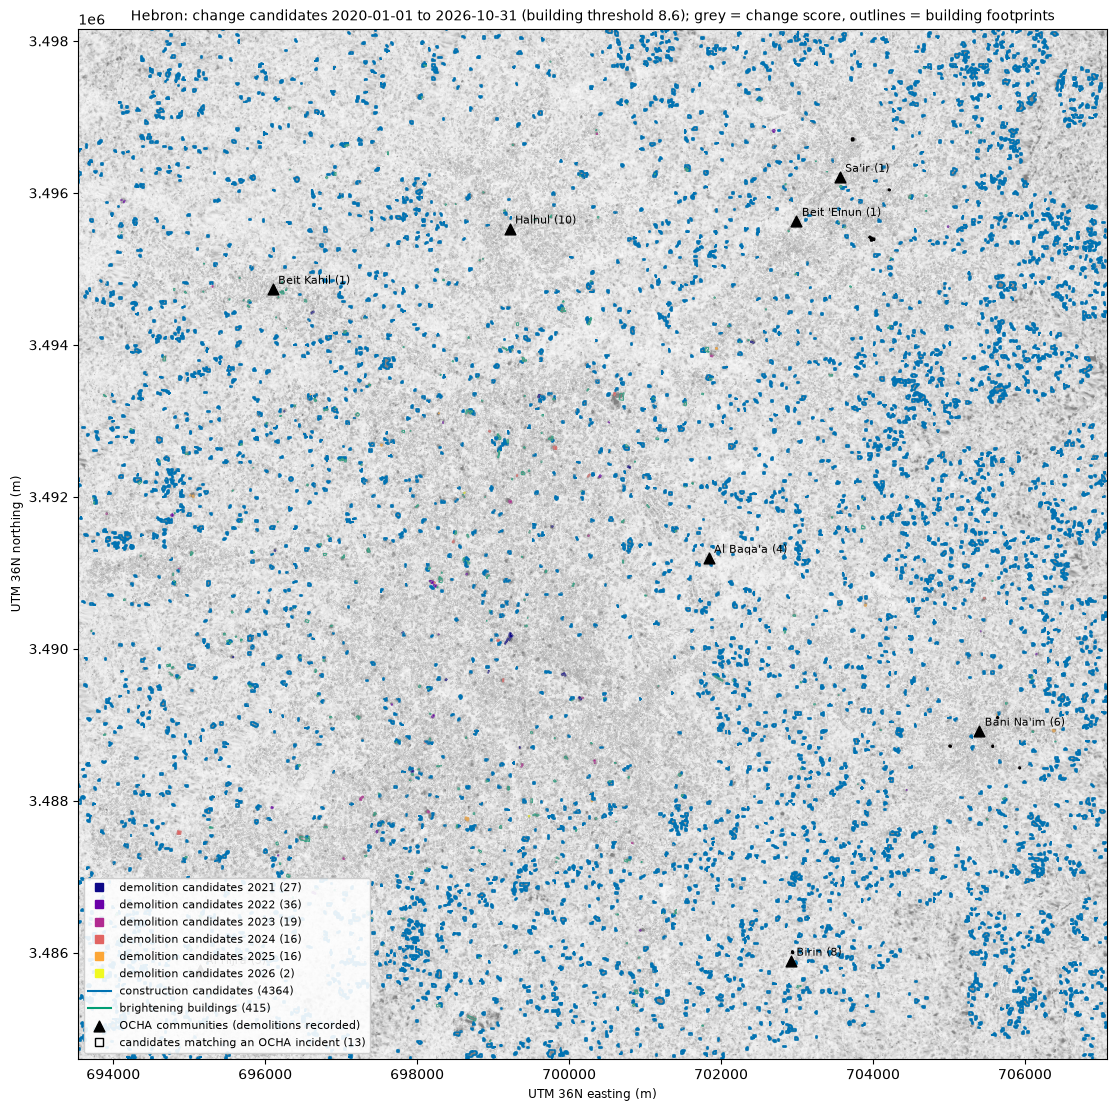

written: /run/media/samuel-appiah-kubi/New Volume/hebronv5/results/hebron_candidates_v6.png and /run/media/samuel-appiah-kubi/New Volume/hebronv5/results/hebron_demolition_candidates.kml (open in Google Earth Pro)


In [25]:
# the demolition map: candidates coloured by the year their change first shows; construction outlined; OCHA communities
BLUE = "#0072B2"
fig, ax = plt.subplots(figsize=(12, 11), constrained_layout=True)
ax.imshow(np.where(valid10, COMB["score"], np.nan), extent=EXTENT10, cmap="Greys", vmin=0, vmax=THRESH * 1.5, alpha=0.5)
fp.boundary.plot(ax=ax, color="0.65", linewidth=0.2)
years = sorted({d[:4] for d in DEM["date"].dropna()}) if len(DEM) else []
cmap = plt.get_cmap("plasma", max(len(years), 1))
for k, yv in enumerate(years):
    sub = DEM[DEM["date"].fillna("").str.startswith(yv)]
    col = cmap(k / max(len(years) - 1, 1) * 0.85)
    sub.plot(ax=ax, color=col, edgecolor=col, linewidth=0.8)
    ax.plot([], [], "s", color=col, label=f"demolition candidates {yv} ({len(sub)})")
if len(CON):
    CON.plot(ax=ax, facecolor="none", edgecolor=BLUE, linewidth=1.2)
    ax.plot([], [], color=BLUE, label=f"construction candidates ({len(CON)})")
if BRIGHT is not None and len(BRIGHT):
    BRIGHT.plot(ax=ax, facecolor="none", edgecolor="#009E73", linewidth=0.6)
    ax.plot([], [], color="#009E73", label=f"brightening buildings ({len(BRIGHT)})")
inside_o = globals().get("inside")
if inside_o is not None and len(inside_o):
    pts_o = gpd.GeoDataFrame(inside_o.groupby("community").agg(lon=("lon", "first"), lat=("lat", "first"), n=("id", "size")).reset_index(),
                             geometry=gpd.points_from_xy(inside_o.groupby("community")["lon"].first(), inside_o.groupby("community")["lat"].first()),
                             crs=4326).to_crs(GRID_CRS)
    ax.scatter(pts_o.geometry.x, pts_o.geometry.y, marker="^", s=60, c="k", zorder=5, label="OCHA communities (demolitions recorded)")
    for _, r in pts_o.iterrows():
        ax.annotate(f"{r['community']} ({r['n']})", (r.geometry.x, r.geometry.y), xytext=(4, 4), textcoords="offset points", fontsize=8)
    mf = RESULTS / "ocha_check" / "ocha_matched_candidates.gpkg"
    if mf.exists():
        mm = gpd.read_file(mf).to_crs(GRID_CRS)
        mm.plot(ax=ax, facecolor="none", edgecolor="k", linewidth=1.6, zorder=6)
        ax.plot([], [], "s", mfc="none", mec="k", label=f"candidates matching an OCHA incident ({mm.geometry.apply(lambda g: g.wkb).nunique()})")
ax.set_xlim(EXTENT10[0], EXTENT10[1]); ax.set_ylim(EXTENT10[2], EXTENT10[3])
ax.set_xlabel("UTM 36N easting (m)"); ax.set_ylabel("UTM 36N northing (m)")
ax.legend(loc="lower left", framealpha=0.9, fontsize=8)
ax.set_title(f"Hebron: change candidates {START} to {END} (building threshold {THRESH_B:.1f}); grey = change score, "
             "outlines = building footprints", fontsize=10)
fig.savefig(RESULTS / "hebron_candidates_v6.png", dpi=250)
plt.show()

# the same for Google Earth Pro: one folder per year, each candidate with its date, score and status
def kml_poly(g):
    g = g if g.geom_type == "Polygon" else max(g.geoms, key=lambda q: q.area)
    return " ".join(f"{x:.7f},{y:.7f},0" for x, y in g.exterior.coords)


if len(DEM):
    d4 = DEM.to_crs(4326)
    folders = []
    tier_names = {1: "tier 1: VV and VH both", 2: "tier 2: likely real", 3: "tier 3: about even", 4: "tier 4: mostly noise"}
    for tv in sorted(d4["tier"].unique()) if "tier" in d4 else [None]:
        st = d4 if tv is None else d4[d4["tier"] == tv]
        sub_f = []
        for k, yv in enumerate(years):
            sub = st[st["date"].fillna("").str.startswith(yv)]
            if not len(sub):
                continue
            pm = "".join(f"<Placemark><name>{r.date}</name><description>score {r.score:.1f}; {r.status}"
                         f"{'; share likely real ' + format(r.share_likely_real, '.2f') if 'share_likely_real' in d4 else ''}</description><styleUrl>#y{k}</styleUrl>"
                         f"<Polygon><outerBoundaryIs><LinearRing><coordinates>{kml_poly(r.geometry)}</coordinates></LinearRing></outerBoundaryIs></Polygon></Placemark>"
                         for r in sub.itertuples())
            sub_f.append(f"<Folder><name>{yv} ({len(sub)})</name>{pm}</Folder>")
        folders.append("".join(sub_f) if tv is None else f"<Folder><name>{tier_names[int(tv)]} ({len(st)})</name>{''.join(sub_f)}</Folder>")
    styles = "".join(f'<Style id="y{k}"><LineStyle><color>ff{int(255*c[2]):02x}{int(255*c[1]):02x}{int(255*c[0]):02x}</color><width>2</width></LineStyle>'
                     f"<PolyStyle><fill>0</fill></PolyStyle></Style>" for k, c in enumerate(cmap(np.linspace(0, 0.85, max(len(years), 1)))))
    (RESULTS / "hebron_demolition_candidates.kml").write_text('<?xml version="1.0" encoding="UTF-8"?><kml xmlns="http://www.opengis.net/kml/2.2">'
                                                             f"<Document><name>Hebron demolition candidates</name>{styles}{''.join(folders)}</Document></kml>",
                                                             encoding="utf-8")
    print("written:", RESULTS / "hebron_candidates_v6.png", "and", RESULTS / "hebron_demolition_candidates.kml", "(open in Google Earth Pro)")

**Reading the result.** Treat every candidate as a place to look, not a finding. Before reporting numbers: (1) check the footprint date against your period (section 5); (2) run the quiet-period test (9a) and report its false-alarm rate; (3) label a sample of candidates **and** of random buildings on dated imagery (9b), and report AUC, recall, precision in the labelled area and the type confusion. Only the type confusion tells you whether the "existed before" rule separates demolition from construction in Hebron; `pre_trend` and the VV/VH signs are there to test whether timing shape or polarisation adds to it.

## 11. Figures, maps and numbers for the report

Everything the report needs, from this run, saved to `results/report/` (figures as PNG at 300 dpi, tables as CSV, key numbers in `key_numbers.json`):

| File | What it shows |
|---|---|
| R1_study_area | the footprints tested and the OCHA communities inside the area |
| R2_coregistration | how far each date was shifted and stretched to line up with the reference (the 2022 geometry change) |
| R3_detection_power | the share of added steps found, by step size, for the first approach and the final one, with their false-alarm rates (7d) |
| R4_found_vs_noise_by_year | candidates found against what noise alone gives, per year and direction (7e) |
| R5_map_candidates | demolition candidates by tier and brightening buildings |
| R6_heatmaps_rate | brightening and demolition candidates per 1,000 buildings, in 750 m cells |
| R7_maps_per_year | one map per dry season |
| R8_example_series | the time series of the six highest-ranked demolition candidates |
| R9_step_and_size | how large the steps are, and how large the buildings |

**Construction on empty land** (off footprints, the pixel test) is left out: it is still noisy. The last output is a results paragraph filled with this run's numbers.

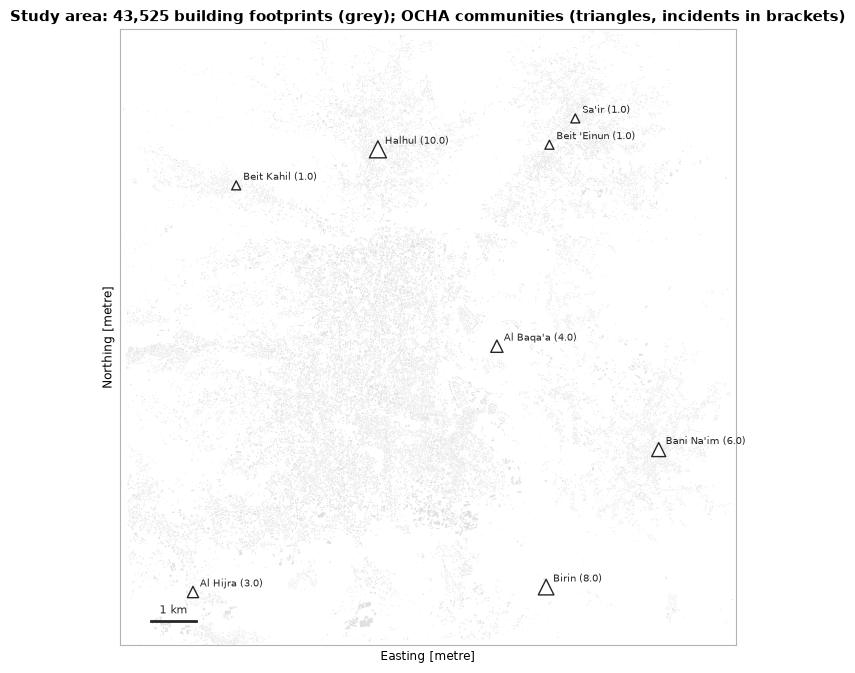

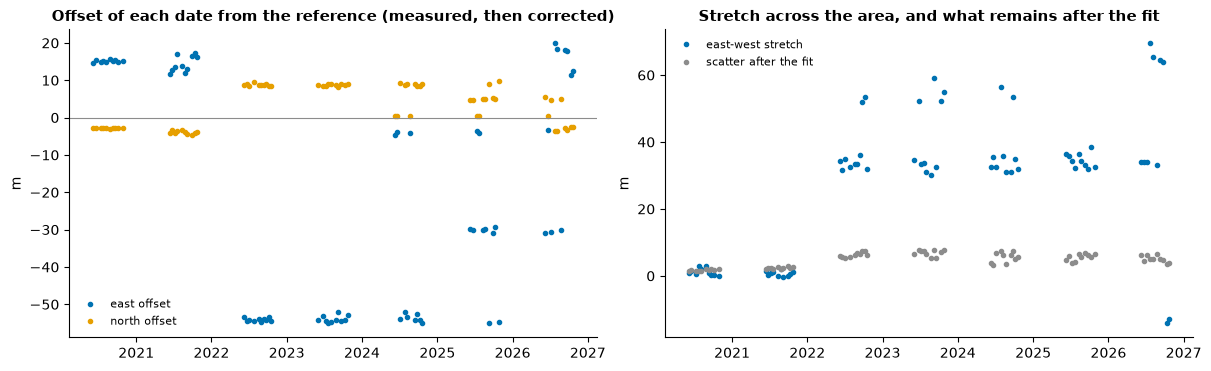

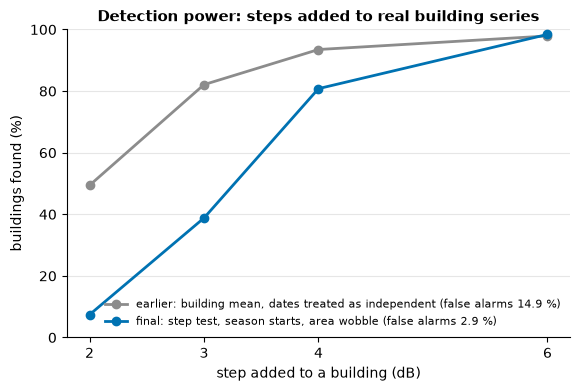

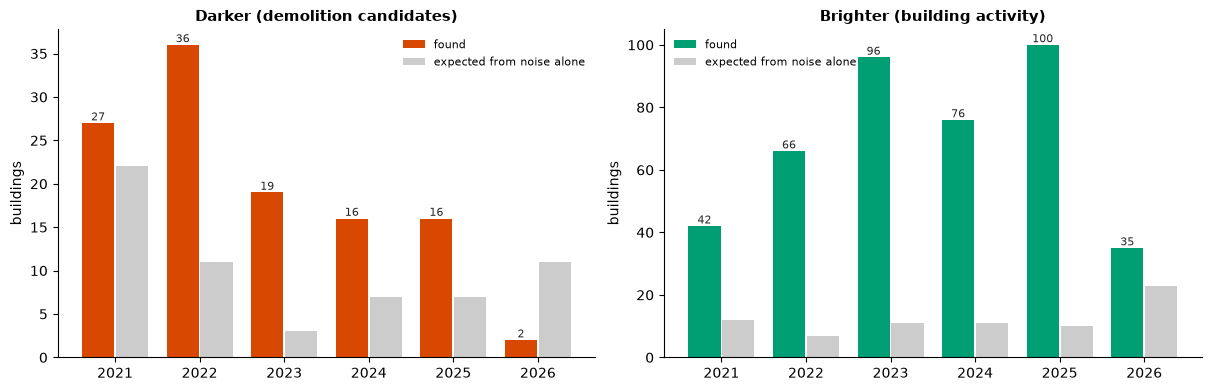

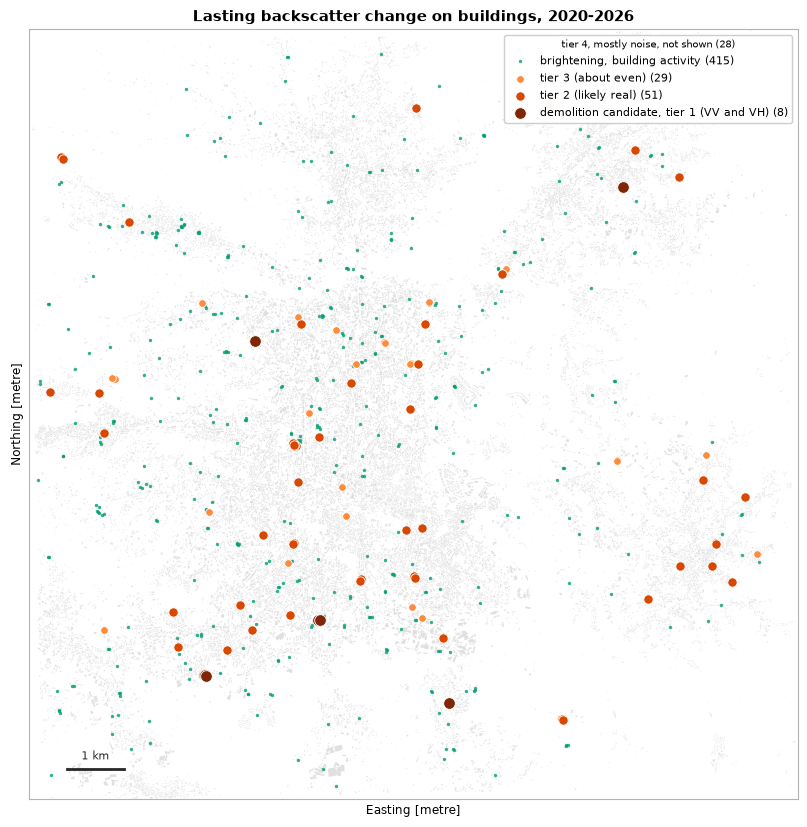

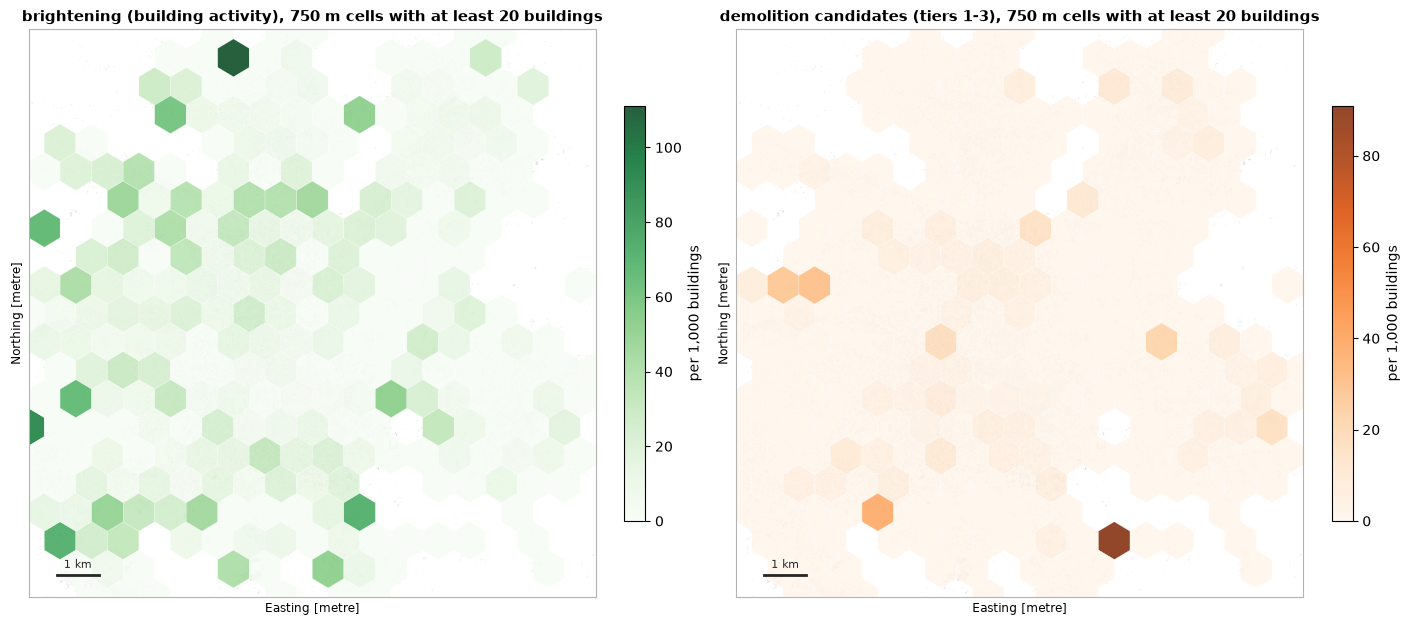

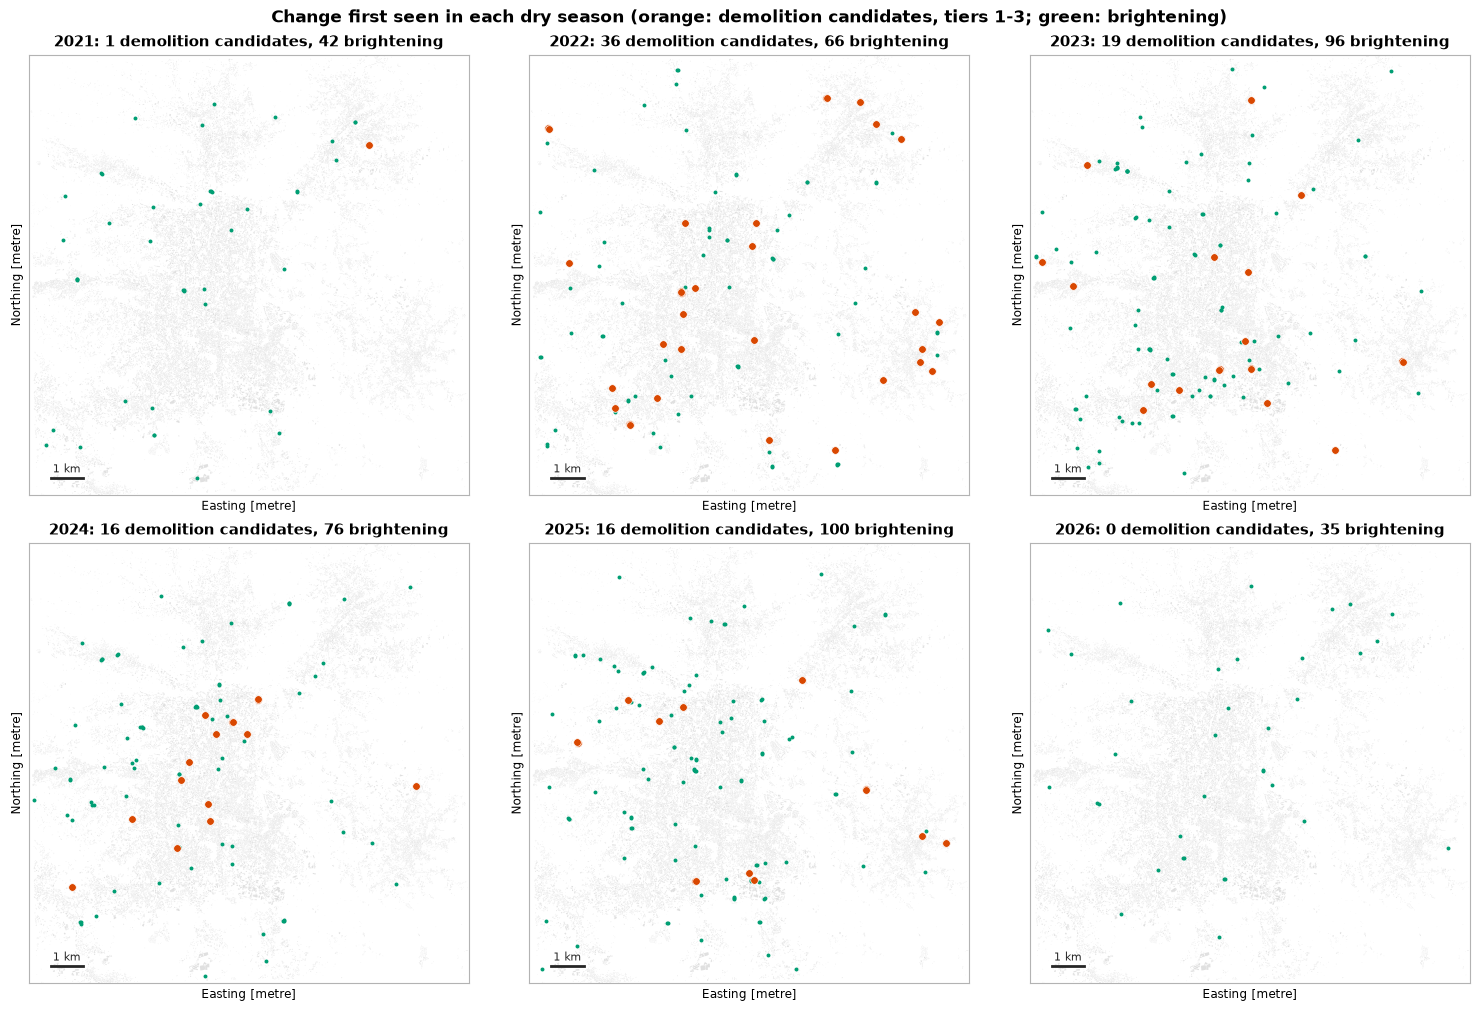

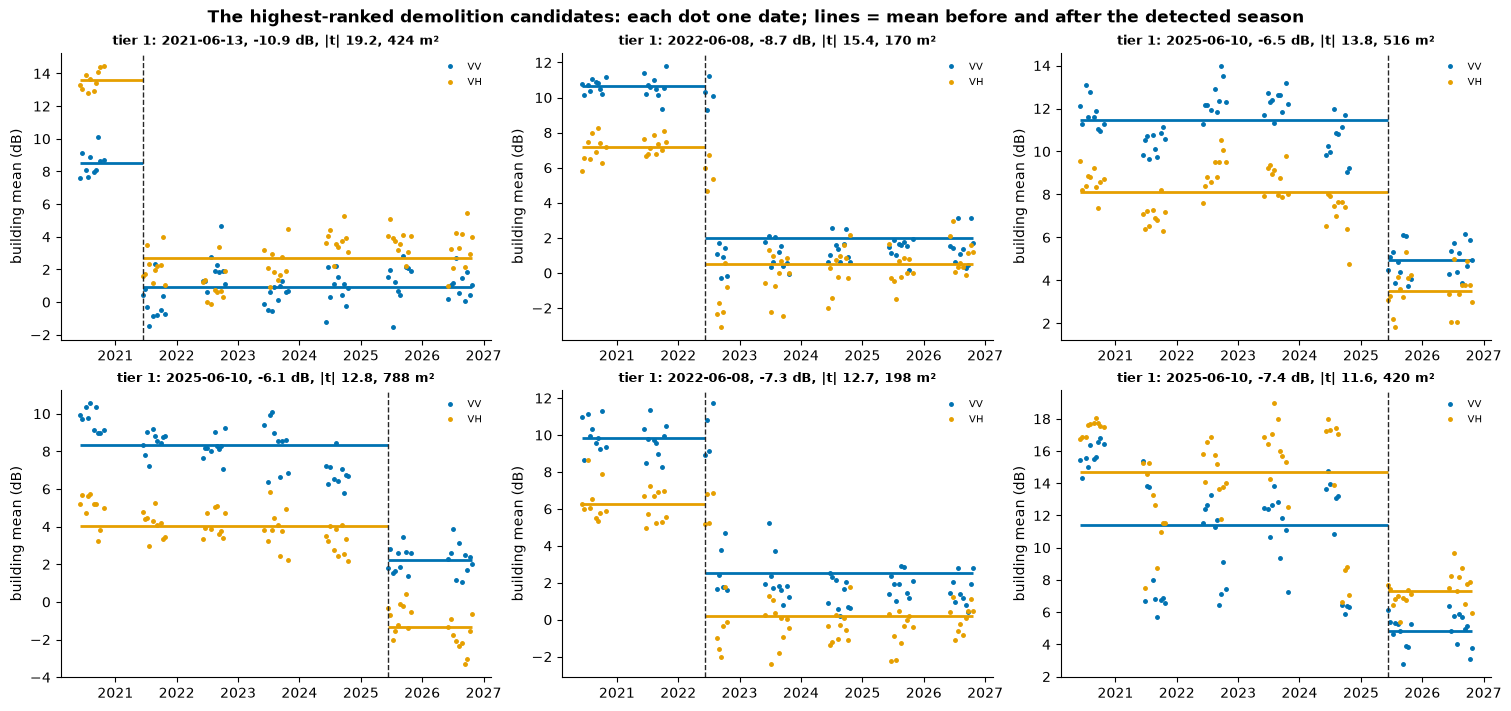

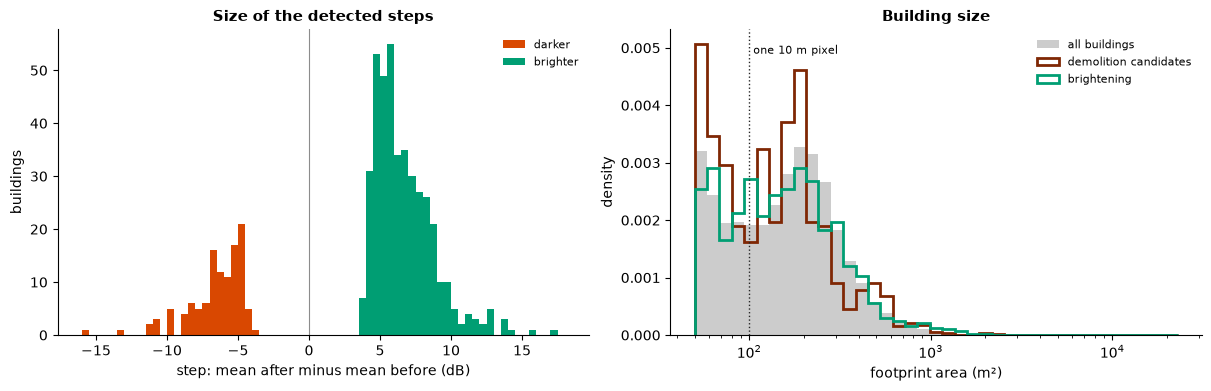

RESULTS (filled from this run)
Of 43,525 building footprints, 415 show a lasting brightening and 116 a lasting darkening between
2020 and 2026, at a threshold that unchanged buildings exceed 0.5 % of the time.
Noise alone, measured by shuffling whole dry seasons, gives about 73 brighter and 60 darker buildings: about 342
brightening and 56 darkening buildings are more than noise (82 % and 48 % of those found).
Steps added to real building series are found 39 % of the time at 3 dB, 81 % at 4 dB and 98 % at 6 dB.
OCHA check: 16 candidates near an incident at the expected date, against 16.8 by chance (enrichment 0.96, p = 0.60).

9 figures and the tables in /run/media/samuel-appiah-kubi/New Volume/hebronv5/results/report:
   R1_study_area.png
   R2_coregistration.png
   R3_detection_power.png
   R4_found_vs_noise_by_year.png
   R5_map_candidates.png
   R6_heatmaps_rate.png
   R7_maps_per_year.png
   R8_example_series.png
   R9_step_and_size.png
   T_candidates_per_year.csv
   T_coregistra

In [26]:
# every figure, map and table for the report, into results/report (PNG at 300 dpi; tables as CSV; key numbers as JSON)
REPORT = RESULTS / "report"
REPORT.mkdir(exist_ok=True)
DARK_C = {1: "#7f2704", 2: "#d94801", 3: "#fd8d3c", 4: "#fdd0a2"}      # demolition tiers: one hue, darker = more likely real
GREEN, GREY, INK = "#009E73", "0.55", "0.15"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11})
SAVED = []
import matplotlib.dates as mdates


def year_axis(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


def save(fig, name):
    fig.savefig(REPORT / name, dpi=300, bbox_inches="tight")
    SAVED.append(name)
    plt.show()


def base_map(ax):
    fp.plot(ax=ax, color="0.88", edgecolor="none")
    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True)
        s.set_color("0.7")
    # 1 km scale bar
    x0, y0 = left + 0.05 * (right - left), bottom + 0.04 * (top - bottom)
    ax.plot([x0, x0 + 1000], [y0, y0], color=INK, lw=2)
    ax.text(x0 + 500, y0 + 0.012 * (top - bottom), "1 km", ha="center", fontsize=8, color=INK)


bld_c = bld.geometry.centroid
bx, by = bld_c.x.to_numpy(), bld_c.y.to_numpy()
DEM_R = DEM if "tier" in DEM else DEM.assign(tier=3)
if "share_likely_real" not in DEM_R:
    DEM_R = DEM_R.assign(share_likely_real=np.nan)
dem_c = DEM_R.geometry.centroid
br_c = BRIGHT.geometry.centroid if BRIGHT is not None and len(BRIGHT) else gpd.GeoSeries([], crs=GRID_CRS)
T7E_ = globals().get("T7E")
T7E3_ = globals().get("T7E3")
T7D_ = globals().get("T7D")

# ---------------------------------------------------------------- R1 study area
fig, ax = plt.subplots(figsize=(8, 8))
base_map(ax)
ins = globals().get("inside")
if ins is not None and len(ins):
    cm_ = ins.groupby("community").agg(lon=("lon", "first"), lat=("lat", "first"), incidents=("id", "size"))
    q = gpd.GeoSeries([Point(xy) for xy in zip(cm_["lon"], cm_["lat"])], crs=4326).to_crs(GRID_CRS)
    ax.scatter(q.x, q.y, s=30 + 12 * cm_["incidents"].to_numpy(), marker="^", color="white", edgecolor=INK, lw=1, zorder=3)
    for (name, r), g in zip(cm_.iterrows(), q):
        ax.annotate(f"{name} ({r.incidents})", (g.x, g.y), xytext=(5, 4), textcoords="offset points", fontsize=7, color=INK)
ax.set_title(f"Study area: {len(bld):,} building footprints (grey); OCHA communities (triangles, incidents in brackets)")
save(fig, "R1_study_area.png")

# ---------------------------------------------------------------- R2 co-registration over time
m_ = globals().get("mine")
if m_ is not None and len(m_) and "east_m" in m_:
    cr_ = m_.assign(day=pd.to_datetime(m_["date"])).sort_values("day")
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
    ax[0].plot(cr_["day"], cr_["east_m"], "o", ms=3, color="#0072B2", label="east offset")
    ax[0].plot(cr_["day"], cr_["north_m"], "o", ms=3, color="#E69F00", label="north offset")
    ax[0].axhline(0, color=GREY, lw=0.8)
    ax[0].set_ylabel("m")
    ax[0].set_title("Offset of each date from the reference (measured, then corrected)")
    ax[0].legend(frameon=False, fontsize=8)
    if "stretch_ew_m" in cr_:
        ax[1].plot(cr_["day"], cr_["stretch_ew_m"], "o", ms=3, color="#0072B2", label="east-west stretch")
    ax[1].plot(cr_["day"], cr_["scatter_m"], "o", ms=3, color=GREY, label="scatter after the fit")
    ax[1].set_ylabel("m")
    ax[1].set_title("Stretch across the area, and what remains after the fit")
    ax[1].legend(frameon=False, fontsize=8)
    year_axis(ax[0])
    year_axis(ax[1])
    save(fig, "R2_coregistration.png")
    cr_.groupby(cr_["date"].str[:4])[[c for c in ["east_m", "north_m", "stretch_ew_m", "stretch_ns_m", "scatter_m"] if c in cr_]] \
       .median().round(1).to_csv(REPORT / "T_coregistration_per_year.csv")

# ---------------------------------------------------------------- R3 detection power and false alarms (7d)
if T7D_ is not None:
    sizes = sorted(int(c.split()[1]) for c in T7D_.columns if c.startswith("found ") and c.endswith(" dB %"))
    pick_v = {"earlier: building mean, dates treated as independent": next((v for v in T7D_.index if v.startswith("building mean, dates independent")), None),
              "final: step test, season starts, area wobble": next((v for v in T7D_.index if "season starts, typical" in v), None)}
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for (lab, v), col in zip(pick_v.items(), [GREY, "#0072B2"]):
        if v is None:
            continue
        r = T7D_.loc[v]
        ax.plot(sizes, [r[f"found {s} dB %"] for s in sizes], "o-", color=col, lw=2, ms=6,
                label=f"{lab} (false alarms {r['false alarms %']:.1f} %)")
    ax.set_xlabel("step added to a building (dB)")
    ax.set_ylabel("buildings found (%)")
    ax.set_ylim(0, 100)
    ax.set_xticks(sizes)
    ax.grid(axis="y", color="0.9")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    ax.set_title("Detection power: steps added to real building series")
    save(fig, "R3_detection_power.png")
    T7D_.to_csv(REPORT / "T_detection_power_variants.csv")

# ---------------------------------------------------------------- R4 found against noise alone, by year (7e)
if T7E3_ is not None:
    yrs_ = T7E3_.index.astype(str)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
    for a, d, col in zip(ax, ["darker", "brighter"], [DARK_C[2], GREEN]):
        xi = np.arange(len(yrs_))
        a.bar(xi - 0.2, T7E3_[(d, "found")], 0.38, color=col, label="found")
        a.bar(xi + 0.2, T7E3_[(d, "expected from noise alone")], 0.38, color="0.8", label="expected from noise alone")
        for i, (f_, e_) in enumerate(zip(T7E3_[(d, "found")], T7E3_[(d, "expected from noise alone")])):
            a.text(i - 0.2, f_, f"{f_}", ha="center", va="bottom", fontsize=8, color=INK)
        a.set_xticks(xi, yrs_)
        a.set_title({"darker": "Darker (demolition candidates)", "brighter": "Brighter (building activity)"}[d])
        a.legend(frameon=False, fontsize=8)
        a.set_ylabel("buildings")
    save(fig, "R4_found_vs_noise_by_year.png")
    T7E3_.to_csv(REPORT / "T_found_vs_noise_by_year.csv")
if T7E_ is not None:
    T7E_.to_csv(REPORT / "T_found_vs_noise.csv")
    if globals().get("T7E2") is not None:
        T7E2.to_csv(REPORT / "T_found_vs_noise_both_pols.csv")

# ---------------------------------------------------------------- R5 main map: demolition candidates by tier, brightening
fig, ax = plt.subplots(figsize=(10, 10))
base_map(ax)
if len(br_c):
    ax.scatter(br_c.x, br_c.y, s=6, color=GREEN, alpha=0.8, lw=0, label=f"brightening, building activity ({len(br_c)})", zorder=2)
for tv in [3, 2, 1]:
    sel = (DEM_R["tier"] == tv).to_numpy()
    if sel.any():
        ax.scatter(dem_c.x[sel], dem_c.y[sel], s={1: 70, 2: 45, 3: 30}[tv], color=DARK_C[tv], edgecolor="white", lw=0.6, zorder=3 + (4 - tv),
                   label={1: "demolition candidate, tier 1 (VV and VH)", 2: "tier 2 (likely real)", 3: "tier 3 (about even)"}[tv] + f" ({int(sel.sum())})")
n4 = int((DEM_R["tier"] == 4).sum())
ax.legend(loc="upper right", frameon=True, framealpha=0.95, fontsize=8, title=f"tier 4, mostly noise, not shown ({n4})", title_fontsize=7)
ax.set_title(f"Lasting backscatter change on buildings, {START[:4]}-{END[:4]}")
save(fig, "R5_map_candidates.png")

# ---------------------------------------------------------------- R6 heat maps: rate per 1,000 buildings
HEX_M = 750
gs = max(int((right - left) / HEX_M), 5)
fig, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
is_br = np.zeros(len(bld))
if BRIGHT is not None and len(BRIGHT):
    is_br[BRIGHT.index.to_numpy()] = 1
is_dm = np.zeros(len(bld))
is_dm[DEM_R.index[DEM_R["tier"] <= 3].to_numpy()] = 1
for a, v, cmap_, lab in zip(ax, [is_br, is_dm], ["Greens", "Oranges"], ["brightening (building activity)", "demolition candidates (tiers 1-3)"]):
    base_map(a)
    hb = a.hexbin(bx, by, C=v * 1000, reduce_C_function=np.mean, gridsize=gs, extent=(left, right, bottom, top),
                  mincnt=20, cmap=cmap_, alpha=0.85, linewidths=0.2, edgecolors="white")
    fig.colorbar(hb, ax=a, shrink=0.6, label="per 1,000 buildings")
    a.set_title(f"{lab}, {HEX_M} m cells with at least 20 buildings")
save(fig, "R6_heatmaps_rate.png")

# ---------------------------------------------------------------- R7 one panel per year
yrs_all = sorted({d[:4] for d in pd.concat([DEM_R["date"], BRIGHT["date"] if BRIGHT is not None else pd.Series(dtype=str)]).dropna()})
if yrs_all:
    nc = 3
    nr = int(np.ceil(len(yrs_all) / nc))
    fig, axs = plt.subplots(nr, nc, figsize=(15, 5 * nr), constrained_layout=True, squeeze=False)
    for a in axs.ravel()[len(yrs_all):]:
        a.set_visible(False)
    for a, yv in zip(axs.ravel(), yrs_all):
        base_map(a)
        sb = BRIGHT[BRIGHT["date"].fillna("").str.startswith(yv)].geometry.centroid if BRIGHT is not None else []
        sd = DEM_R[DEM_R["date"].fillna("").str.startswith(yv) & (DEM_R["tier"] <= 3)].geometry.centroid
        if len(sb):
            a.scatter(sb.x, sb.y, s=8, color=GREEN, lw=0)
        if len(sd):
            a.scatter(sd.x, sd.y, s=30, color=DARK_C[2], edgecolor="white", lw=0.5)
        a.set_title(f"{yv}: {len(sd)} demolition candidates, {len(sb)} brightening")
    fig.suptitle("Change first seen in each dry season (orange: demolition candidates, tiers 1-3; green: brightening)", fontweight="bold")
    save(fig, "R7_maps_per_year.png")

# ---------------------------------------------------------------- R8 example building time series
if BUILDING_TEST == "step" and len(DEM_R):
    ex = DEM_R.sort_values(["tier", "score"], ascending=[True, False]).head(6)
    fig, axs = plt.subplots(2, 3, figsize=(15, 7), constrained_layout=True, squeeze=False)
    for a, (i, r) in zip(axs.ravel(), ex.iterrows()):
        for n, col in zip(BSER, ["#0072B2", "#E69F00", "#CC79A7", "#56B4E9"]):
            days = [date.fromordinal(int(t)) for t in BT[n]]
            y = np.asarray(BSER[n][:, i], float)
            a.plot(days, y, "o", ms=2.5, color=col, label=n.split("_")[1])
            sp_ = date.fromisoformat(r["date"]).toordinal()
            pre, post = BT[n] < sp_, BT[n] >= sp_
            a.hlines(np.nanmean(y[pre]), days[0], date.fromordinal(sp_), color=col, lw=2)
            a.hlines(np.nanmean(y[post]), date.fromordinal(sp_), days[-1], color=col, lw=2)
        a.axvline(date.fromisoformat(r["date"]), color=INK, ls="--", lw=1)
        a.set_title(f"tier {int(r['tier'])}: {r['date']}, {r['delta_db']:+.1f} dB, |t| {r['score']:.1f}, {r['area_m2']:.0f} m²", fontsize=9)
        a.set_ylabel("building mean (dB)")
        a.legend(frameon=False, fontsize=7)
        year_axis(a)
    for a in axs.ravel()[len(ex):]:
        a.set_visible(False)
    fig.suptitle("The highest-ranked demolition candidates: each dot one date; lines = mean before and after the detected season",
                 fontweight="bold")
    save(fig, "R8_example_series.png")

# ---------------------------------------------------------------- R9 size of the change and of the buildings
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
ch = bld[bld["changed"]]
bins = np.arange(np.floor(ch["delta_db"].min()) if len(ch) else -10, (np.ceil(ch["delta_db"].max()) if len(ch) else 10) + 0.5, 0.5)
ax[0].hist(DEM_R["delta_db"], bins=bins, color=DARK_C[2], label="darker")
if BRIGHT is not None and len(BRIGHT):
    ax[0].hist(BRIGHT["delta_db"], bins=bins, color=GREEN, label="brighter")
ax[0].axvline(0, color=GREY, lw=0.8)
ax[0].set_xlabel("step: mean after minus mean before (dB)")
ax[0].set_ylabel("buildings")
ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("Size of the detected steps")
ab_ = np.logspace(np.log10(max(MIN_FOOTPRINT_M2, 1)), np.log10(bld["area_m2"].max() + 1), 40)
ax[1].hist(bld["area_m2"], bins=ab_, color="0.8", label="all buildings", density=True)
ax[1].hist(DEM_R["area_m2"], bins=ab_, histtype="step", color=DARK_C[1], lw=2, label="demolition candidates", density=True)
if BRIGHT is not None and len(BRIGHT):
    ax[1].hist(BRIGHT["area_m2"], bins=ab_, histtype="step", color=GREEN, lw=2, label="brightening", density=True)
ax[1].axvline(100, color=INK, ls=":", lw=1)
ax[1].text(100, ax[1].get_ylim()[1] * 0.92, " one 10 m pixel", fontsize=8)
ax[1].set_xscale("log")
ax[1].set_xlabel("footprint area (m²)")
ax[1].set_ylabel("density")
ax[1].legend(frameon=False, fontsize=8)
ax[1].set_title("Building size")
save(fig, "R9_step_and_size.png")

# ---------------------------------------------------------------- tables and key numbers
tiers_t = DEM_R.groupby("tier").agg(candidates=("score", "size"), share_likely_real=("share_likely_real", "mean"),
                                    median_step_db=("delta_db", "median"), median_area_m2=("area_m2", "median")).round(2)
tiers_t.to_csv(REPORT / "T_demolition_tiers.csv")
per_year.to_csv(REPORT / "T_candidates_per_year.csv")
if globals().get("ocha_table") is not None:
    ocha_table.to_csv(REPORT / "T_ocha_check.csv", index=False)
if globals().get("INJECTION_TABLE") is not None:
    INJECTION_TABLE.to_csv(REPORT / "T_injection_pixel_method.csv")


def g(tab, d, col):
    try:
        return int(tab.loc[d, col])
    except Exception:
        return None


final_v = next((v for v in T7D_.index if "season starts, typical" in v), None) if T7D_ is not None else None
KEY = {"period": f"{START} .. {END}", "buildings_scored": int(len(bld)), "footprint_source": str(FOOTPRINTS_PATH),
       "stacks": list(BSER) if BUILDING_TEST == "step" else COMB_NAMES, "building_threshold_abs_t": round(THRESH_B, 2),
       "threshold_rule": f"{NULL_QUANTILE_BUILDING} quantile of season-shuffled building scores",
       "darker_found": g(T7E_, "darker", "found"), "darker_noise": g(T7E_, "darker", "expected from noise alone"),
       "brighter_found": g(T7E_, "brighter", "found"), "brighter_noise": g(T7E_, "brighter", "expected from noise alone"),
       "darker_both_pols_found": g(globals().get("T7E2"), "darker", "found"), "darker_both_pols_noise": g(globals().get("T7E2"), "darker", "expected from noise alone"),
       "tiers": {int(k): int(v) for k, v in DEM_R["tier"].value_counts().sort_index().items()},
       "detection_power_final_%": {c: float(T7D_.loc[final_v, c]) for c in T7D_.columns if c.startswith("found")} if final_v else None,
       "false_alarms_final_%": float(T7D_.loc[final_v, "false alarms %"]) if final_v else None,
       "ocha": globals().get("ocha_table").to_dict("records") if globals().get("ocha_table") is not None else None,
       "off_footprint_construction": f"{len(CON)} clusters from the pixel test: not reliable, not used in the report"}
(REPORT / "key_numbers.json").write_text(json.dumps(KEY, indent=1, default=str))

# a results paragraph filled from this run
d_f, d_n, b_f, b_n = KEY["darker_found"], KEY["darker_noise"], KEY["brighter_found"], KEY["brighter_noise"]
if None not in (d_f, d_n, b_f, b_n):
    print(f"""RESULTS (filled from this run)
Of {KEY['buildings_scored']:,} building footprints, {b_f} show a lasting brightening and {d_f} a lasting darkening between
{START[:4]} and {END[:4]}, at a threshold that unchanged buildings exceed {100 * (1 - NULL_QUANTILE_BUILDING):.1f} % of the time.
Noise alone, measured by shuffling whole dry seasons, gives about {b_n} brighter and {d_n} darker buildings: about {b_f - b_n}
brightening and {d_f - d_n} darkening buildings are more than noise ({100 * (b_f - b_n) / b_f:.0f} % and {100 * (d_f - d_n) / d_f:.0f} % of those found).""")
    if final_v:
        print(f"Steps added to real building series are found {T7D_.loc[final_v, 'found 3 dB %']:.0f} % of the time at 3 dB, "
              f"{T7D_.loc[final_v, 'found 4 dB %']:.0f} % at 4 dB and {T7D_.loc[final_v, 'found 6 dB %']:.0f} % at 6 dB.")
    if globals().get("ocha_table") is not None:
        o = ocha_table.iloc[0]
        print(f"OCHA check: {o['observed']} candidates near an incident at the expected date, against {o['by chance (mean)']} by chance "
              f"(enrichment {o['enrichment']}, p = {o['p (chance >= observed)']:.2f}).")
print(f"\n{len(SAVED)} figures and the tables in {REPORT}:")
for f in sorted(p.name for p in REPORT.iterdir()):
    print("  ", f)